# E15-H80 - moved flag read on the matched pairs

**Author**: Konrad Jelen (kj) <br>
**Date**: 2026-10-09 <br>
**Pipeline stage**: experiment - E13 campaign, stage A (measure), per-statement `moved` annotation of the structural detail file <br>
**Execution model**: opus <br>

Measures one registered lever on the `moved` flag that `docdistance.pipeline._build_structural_details` writes on every
statement record. The shipped flag and the E12-H61 conjunction both read the exact-plan alignment. When document `A` is
longer than document `B`, uniform marginals force a statement of `A` that has no counterpart to spread its mass over
several targets. Its aligned target is then the largest of several equal plan entries (DEF-TRANS-13), and that target
also shifts the ranks of the statements that were kept. The lever reads `moved` on the one-to-one matched pairs only.
Nothing under `src/` is edited: every arm is computed in this notebook from the shipped per-statement records plus the
matching.

**Mechanism under test**. A unit-capacity partial matching pairs each statement of `A` (length `n`) with at most one
statement of `B` (length `m`) and keeps the pair only when its ground cost `C` is below the cutoff `c`:

$$M^* = \arg\min_{M} \sum_{(i,j) \in M} \Big(\min(C_{ij},\, c) + \varepsilon\,\Big|\tfrac{i}{n} - \tfrac{j}{m}\Big|\Big), \qquad M_c = \{(i,j) \in M^* : C_{ij} < c\}$$

With `r_A(i)` the rank of statement `i` among the matched statements of `A` and `r_B(j)` the rank of its target among the
matched statements of `B`, both in document order:

$$d_i = r_B(j) - r_A(i), \qquad \mathrm{moved}_i = (i \in M_c) \;\wedge\; (d_i \neq 0) \;\wedge\; \Big(\Big|\tfrac{d_i}{|M_c|}\Big| > \tau\Big)$$

Registered values: `c = 0.325`, `ε = 1e-6`, `τ = MOVED_TOLERANCE = 0.05`. The flag is a per-statement annotation. It is
not a distance and not a metric, and no distance is changed by it.

**Arms**. Every arm keeps the shipped rule that a statement with `no_counterpart` reads `moved` false.
- **shipped** - `abs(displacement_norm) > τ` on the exact-plan alignment
- **conjunction** (baseline, E12-H61) - `displacement != 0 AND abs(displacement_norm) > τ` on the exact-plan alignment
- **conjunction AND matched** - the conjunction, kept only on statements that hold a match (reported without a bar)
- **lever** - the matched-pair definition above
- **lever, no tie-break** - the lever with `ε = 0` (reported without a bar)

## Approach
1. **Harness sanity check** - the E12-H61 reorder-pool reading (13675 flagged true relocations over 1680 permutations, 0 lost under the conjunction) and the E13-H70 deletion set (280 cases, 280 of 280 at or below `0.005` under the matched order gap). The record places this check before the kill-gate
2. **Kill-gate** - the conjunction must flag at least one statement in at least one of the 280 order-preserving deletion cases, otherwise the lever has nothing to correct on real documents
3. **Clause 1** - the lever flags 0 statements, kept or removed, in 280 of 280 deletion cases
4. **Clause 2** - on each of the 1680 verbatim reorder-pool permutations the lever's flag array is `np.array_equal` to the conjunction's
5. **Clause 3** - on the same 1680 permutations applied to the back-translation of each base, the lever keeps at least 98% of the truly relocated statements that the conjunction flags
6. **Clause 4** - the E12-H61 fixtures read insertion 0 of 6, swap 2 of 2, reversal 12 of 12, 12 to 8 text shrinkage 0 of 12
7. **Reported without a bar** - precision and recall on reordered-and-deleted cases, false fires on reworded reorders, the lever with no tie-break, the share of deletion cases with a tied plan row
8. **Outside the record** - five executor passes on what the registered sets cannot show: the cutoff on the reworded reorders, reworded survivors, a long document with repeated statements, document lengths where one rank step equals the tolerance, and documents encoded in separate calls
9. **Guardrails** - `V` counted on the ibm panel, triangle inequality of shipped `smd`, source tree hashed, default path compared by exact equality

## Outputs
- `reports/E15-H80-moved-on-matched-pairs-metrics.json` - every measured number, the bar readings, the guardrail readings
- In-notebook: one table per check and clause, eight figures, the conclusions

## Environment

No GPU is used. The campaign primer pins stage A to CPU, so `CUDA_VISIBLE_DEVICES` is set empty before any model library
is imported. The working directory is set to the repository root because the models resolve through `docdistance.json`
in the current folder.

In [1]:
import os

os.chdir("/home/lab/workspace/learning/projects/docdistance")   # docdistance.json is read from the current folder
os.environ["CUDA_VISIBLE_DEVICES"] = ""            # CPU only - set before any torch import
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
print(f"device: CPU only | encoder backend: OpenVINO INT8 | cwd: {os.getcwd()}")

device: CPU only | encoder backend: OpenVINO INT8 | cwd: /home/lab/workspace/learning/projects/docdistance


## Imports

The shipped `docdistance` library (the detail builder, the transport primitives, the pipeline constants), scipy for the
assignment solve, polars for the result tables, rich and matplotlib for the output. `inspect` and `difflib` carry the
E12-H61 conjunction builder, which is compiled from the shipped source text.

In [2]:
%load_ext autoreload
%autoreload 2

# stdlib
import contextlib                                   # silence the model-load stderr of the shipped pipeline
import difflib                                      # diff of the E12-H61 conjunction variant against the shipped source
import hashlib                                      # sha256 of the source tree (src-untouched guardrail)
import inspect                                      # shipped source text; source text of the copied functions
import io                                           # sink for the redirected stderr
import itertools                                    # tie resolutions of a plan row; transposition pairs
import json                                         # fixture files, saved readings, the metrics JSON
import subprocess                                   # git status (src-untouched guardrail)
import sys                                          # interpreter path, progress-bar stream
import warnings                                     # silence third-party deprecation warnings
from collections import Counter                     # repeated statement texts, tally of differing distances
from collections.abc import Iterable                # type of a sequence of statement texts
from pathlib import Path                            # repository paths

warnings.filterwarnings("ignore")

# scientific
import numpy as np                                  # arrays, exact equality checks
import polars as pl                                 # result tables
import scipy                                        # version line
from scipy.optimize import linear_sum_assignment    # unit-capacity statement matching (the lever)

# visualisation
import matplotlib.pyplot as plt                     # inline figures

# console
from rich.console import Console, Group             # one output block per result
from rich.panel import Panel                        # bordered verdict blocks
from rich.table import Table                        # tabular readings
from tqdm import tqdm                               # text progress bar for the ladder sweep

# optimal transport and the shipped library
import ot                                           # POT, the solver behind smd and the exact plan
import docdistance                                  # version line
from docdistance import distance as _core           # _aligned_plan, the coupling behind order_alignment
from docdistance import pipeline                    # source text of the shipped detail builder
from docdistance.distance import SMD_MAX, cost_matrix, opw_gap, smd      # shipped functions, used unmodified
from docdistance.pipeline import (                  # shipped constants, entry point and detail builder
    DIFF_CHANGED_COST,
    MOVED_TOLERANCE,
    NO_COUNTERPART_COST,
    DocDistance,
    _build_structural_details,
)

console = Console()
console.print(
    f"[bold medium_purple]Imports ready[/bold medium_purple]\n"
    f"  python [dark_sea_green]{sys.version.split()[0]}[/dark_sea_green] [dim]{sys.executable}[/dim]\n"
    f"  docdistance [dark_sea_green]{docdistance.__version__}[/dark_sea_green] | POT [dark_sea_green]{ot.__version__}[/dark_sea_green]"
    f" | numpy [dark_sea_green]{np.__version__}[/dark_sea_green] | scipy [dark_sea_green]{scipy.__version__}[/dark_sea_green]"
    f" | polars [dark_sea_green]{pl.__version__}[/dark_sea_green]"
)

Imports ready
  python 3.14.8 /home/lab/workspace/learning/projects/docdistance/.venv/bin/python
  docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6 | scipy 1.17.1 | polars 1.42.1

## Reproducibility

`SEED = 0` is the E12-H62 and E13-H70 seed. The interior-deletion draws use `np.random.default_rng([SEED, base index, k, rep])`,
so this value makes the rebuilt deletion set identical to the E13-H70 set. Every other computation is deterministic:
the encoder is a frozen INT8 graph, and the network simplex, the fixed-iteration Sinkhorn and the assignment solver
take no random input.

In [3]:
SEED = 0
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=0


## Configuration

Paths, the registered lever and bar of the E15-H80 record, the registered harness and prediction numbers, the E13-H70
deletion grid, the E12-H61 fixtures and the figure palette. Every threshold that decides a verdict field is a number the
record states. The record leaves four reading rules open; they are written here as executor rules and the readings they
affect are reported with their second readings.

- **Deletion-set check** - the notes of this run ask for the 280 E13-H70 deletion cases to be verified by reproducing 280 of 280 at or below `0.005` under the matched order gap. E13-H70 registered that reading at `c = 0.6`; the reading at `c = 0.325` is printed beside it
- **Reversal fixture** - the record says "reversal 12 of 12" and E12-H61 holds two reversal fixtures (orthogonal and real text). Clause 4 requires both
- **Back-translation alignment** - a `<base>~bt` document is used when it names the base in `paraphrase_of`, has the same statement count, equals the stored `.bt.json` list, and every statement and its reword are mutual cheapest partners. A base that fails is left out and reported
- **Tied plan row** - two entries of one plan row are "equal largest" when they differ by at most `TIE_ATOL = 1e-12`; the count under exact float equality is printed beside it

In [4]:
# Paths
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
FIXTURE = ROOT / "data/processed/structure-fixture"                       # 10 base documents, reorder pool, ~bt paraphrases
PARAPHRASE_DIR = ROOT / "data/interim/structure-paraphrase"               # <base>.bt.json, the stored back-translations
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"   # ibm panel for the V guardrail
H61_NOTEBOOK = ROOT / "notebooks/experiments/E12-H61-kj-moved-conjunction.ipynb"
H70_NOTEBOOK = ROOT / "notebooks/experiments/E13-H70-kj-matched-order-gap.ipynb"
H61_METRICS = ROOT / "reports/E12-H61-moved-conjunction-metrics.json"     # saved E12-H61 readings
H70_METRICS = ROOT / "reports/E13-H70-matched-order-gap-metrics.json"     # saved E13-H70 readings
METRICS_OUT = ROOT / "reports/E15-H80-moved-on-matched-pairs-metrics.json"

# Registered lever (E15-H80 record)
C_MATCH = 0.325                        # cutoff c of the unit-capacity partial matching
EPS_TIE = 1e-6                         # weight of the positional tie-break abs(i / n - j / m)

# Registered bar (E15-H80 record, applied literally)
N_DELETION_CASES = 280                 # clause 1: the lever flags 0 statements in every one of these cases
N_POOL_PERMUTATIONS = 1680             # clause 2: flag arrays np.array_equal to the conjunction on every permutation
RETENTION_BAR = 0.98                   # clause 3: share of the conjunction-flagged true relocations the lever keeps
FIXTURE_BAR = {"insertion": (0, 6), "swap": (2, 2), "reversal": (12, 12), "shrinkage": (0, 12)}   # clause 4: (flagged, of)

# Registered harness reading (E12-H61), kill-gate and prediction (E15-H80 record), standing guardrail (campaign primer)
H61_POOL_FLAGGED = 13675               # true relocations the shipped flag fires on over the 1680 permutations
H61_POOL_LOST = 0                      # of which the conjunction loses
KILL_GATE_MIN_CASES = 1                # the conjunction must flag a statement in at least this many deletion cases
PRED_CONJ_CASE_SHARE = 0.10            # the conjunction flags >= 1 statement in at least this share of the deletion cases
PRED_RETENTION_MIN, PRED_RETENTION_MAX = 0.99, 1.0   # the lever keeps 99% to 100% of the conjunction-flagged true relocations
V_GUARDRAIL = 0                        # V stays 0/24 on the ibm panel

# E13-H70 deletion set and ladder, rebuilt exactly
KS = (1, 2, 3, 4)                      # statements deleted
INTERIOR_REPS = 5                      # interior draws per base and k
C_H70 = NO_COUNTERPART_COST            # 0.6, the cutoff E13-H70 registered for its 280/280 reading
GAP_BAR = 0.005                        # paraphrase reference p95, the E13-H70 ceiling
K_LADDER = 2                           # deletions of the reordered-and-deleted ladder
N_RUNGS = 6                            # E11 rungs: equal-width bins of the normalized footrule displacement
RUNG_EDGES = np.linspace(0.0, 1.0, N_RUNGS + 1)

# E12-H61 fixtures, copied unchanged - worked example of docs/example-map-interpretations.md
DOC_A = """The API now supports pagination on all list endpoints.
Authentication tokens expire after 24 hours.
The dashboard loads in under two seconds on average.
Users can export reports as CSV or PDF.
The mobile app supports offline mode for cached data.
We fixed a memory leak in the background sync worker."""

DOC_B = """The API now supports pagination on all list endpoints.
Dark mode is now available across the entire interface.
Users can export reports as CSV or PDF.
The dashboard loads in under two seconds on average.
Push notifications can now be scheduled by the user.
We fixed a memory leak in the background sync worker."""

# the insertion fixture: A itself, with one novel statement prepended - every A statement is
# untouched in content and in relative order, so the ground truth is 0 moved
NOVEL = "The billing service migrated to the new invoicing backend."
DOC_B_INS = NOVEL + "\n" + DOC_A

SWAP_INDICES = (2, 3)   # the dashboard/export swap - the true positives of the worked example

# --- 12 to 8 shrinkage synthetic, the DEF-TRANS-2 evidence shape --------------------------------
SHRINK_N, SHRINK_REMOVED = 12, {2, 5, 8, 11}
SHRINK_KEPT = [i for i in range(SHRINK_N) if i not in SHRINK_REMOVED]

SHRINK_TEXT = [
    "The API now supports pagination on all list endpoints.",
    "Authentication tokens expire after 24 hours.",
    "The dashboard loads in under two seconds on average.",
    "Users can export reports as CSV or PDF.",
    "The mobile app supports offline mode for cached data.",
    "We fixed a memory leak in the background sync worker.",
    "Search results are ranked by recency as well as relevance.",
    "Audit logs retain twelve months of account activity.",
    "Webhooks retry failed deliveries with exponential backoff.",
    "The onboarding wizard was reduced from nine steps to four.",
    "Scheduled reports can be delivered to a shared mailbox.",
    "Container images are rebuilt nightly against the latest base image.",
]

# Executor rules - the record gives no number for these (see the section text)
TIE_ATOL = 1e-12                       # two entries of one plan row are "equal largest" within this absolute difference
TIE_COMBO_CAP = 50_000                 # largest number of tie resolutions enumerated for one deletion case

# Passes outside the registered record
LONG_DOC = "source"                    # the one structure-fixture document above 14 statements
LONG_PREFIXES = (14, 20, 30, 40, 50)   # prefix lengths; the whole document is appended as the last length
LONG_REPS = 20                         # interior draws per prefix length
LONG_K = 2                             # statements deleted per draw
LONG_SEED = 7                          # seed head of the E13-H70 third pass: [7, n, draw]
BOUNDARY_LENGTHS = (14, 20, 40)        # document lengths of the single-transposition pass
C_SWEEP = (0.25, 0.28, 0.30, 0.32, C_MATCH, 0.35, 0.45, C_H70)   # cutoffs of the sensitivity pass on the reworded reorders
BOUNDARY_SCAN_MAX = 100                # longest length of the arithmetic scan

# ibm panel for the V guardrail: (file, label, tier), reference first
PANEL_DOCS = [
    ("exec-summary-gold-opus-4-6.md", "gold", "gold"),
    ("exec-summary-gold-2-opus-4-6.md", "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md", "v1", "gold"),
    ("exec-summary-2-opus-4-6.md", "v2", "gold"),
    ("exec-summary-opus-4-6.md", "opus", "gold"),
    ("exec-summary-sonnet-4-6.md", "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md", "haiku", "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md", "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md", "adv2-b", "adv2"),
]
PANEL_REFERENCE = "gold"
PANEL_PRIMER_ROW = {"V": 0, "margin_pts": 4.71}    # naive row on OpenVINO INT8 quoted by the campaign primer

# Arms: key → (label, colour, hatch, marker); one colour and one pattern per arm for the whole notebook
ARM_STYLE = {
    "shipped": ("shipped (norm only)", "#E74C3C", "", "o"),
    "conjunction": ("conjunction (E12-H61 baseline)", "#F39C12", "//", "s"),
    "conjunction_and_matched": ("conjunction AND matched", "#9B59B6", "..", "^"),
    "lever": ("lever (matched pairs)", "#3498DB", "xx", "D"),
    "lever_no_tiebreak": ("lever, no tie-break", "#2ECC71", "\\\\", "v"),
}
FLAG_ARMS = tuple(ARM_STYLE)
ARM_LABEL = {arm: style[0] for arm, style in ARM_STYLE.items()}
COL_REFERENCE = "#7F8C8D"              # bars and reference lines

console.print(
    f"[bold medium_purple]Configuration[/bold medium_purple]\n"
    f"[dim]{'─' * 60}[/dim]\n"
    f"[bold]Paths[/bold]\n"
    f"  Fixture: [dim]{FIXTURE.relative_to(ROOT)}[/dim]\n"
    f"  Saved readings: [dim]{H61_METRICS.relative_to(ROOT)}[/dim], [dim]{H70_METRICS.relative_to(ROOT)}[/dim]\n"
    f"  Output: [cadet_blue]{METRICS_OUT.relative_to(ROOT)}[/cadet_blue]\n\n"
    f"[bold]Registered lever[/bold]\n"
    f"  Matching cutoff c: [dark_sea_green]{C_MATCH}[/dark_sea_green] [dim](shipped DIFF_CHANGED_COST = {DIFF_CHANGED_COST:.6f})[/dim]\n"
    f"  Tie-break weight eps: [dark_sea_green]{EPS_TIE}[/dark_sea_green]\n"
    f"  MOVED_TOLERANCE: [dark_sea_green]{MOVED_TOLERANCE}[/dark_sea_green] | NO_COUNTERPART_COST: [dark_sea_green]{NO_COUNTERPART_COST}[/dark_sea_green] [dim](shipped constants)[/dim]\n\n"
    f"[bold]Registered bar[/bold]\n"
    f"  Clause 1: the lever flags 0 statements in [dark_sea_green]{N_DELETION_CASES}[/dark_sea_green]/{N_DELETION_CASES} order-preserving deletion cases\n"
    f"  Clause 2: lever flags np.array_equal to the conjunction on [dark_sea_green]{N_POOL_PERMUTATIONS}[/dark_sea_green]/{N_POOL_PERMUTATIONS} verbatim permutations\n"
    f"  Clause 3: the lever keeps >= [dark_sea_green]{RETENTION_BAR:.0%}[/dark_sea_green] of the conjunction-flagged true relocations on reworded reorders\n"
    f"  Clause 4: fixtures (flagged, of) [dark_sea_green]{FIXTURE_BAR}[/dark_sea_green]\n\n"
    f"[bold]Registered harness and prediction[/bold]\n"
    f"  E12-H61 pool reading: [dark_sea_green]{H61_POOL_FLAGGED}[/dark_sea_green] flagged true relocations, [dark_sea_green]{H61_POOL_LOST}[/dark_sea_green] lost\n"
    f"  Kill-gate: conjunction flags in >= [dark_sea_green]{KILL_GATE_MIN_CASES}[/dark_sea_green] deletion case | guardrail V = [dark_sea_green]{V_GUARDRAIL}[/dark_sea_green]/24\n"
    f"  Prediction: conjunction flags in >= [dark_sea_green]{PRED_CONJ_CASE_SHARE:.0%}[/dark_sea_green] of the deletion cases; retention"
    f" [dark_sea_green]{PRED_RETENTION_MIN:.0%}[/dark_sea_green] to [dark_sea_green]{PRED_RETENTION_MAX:.0%}[/dark_sea_green]\n\n"
    f"[bold]Deletion set (E13-H70)[/bold]\n"
    f"  k: [dark_sea_green]{KS}[/dark_sea_green] | positions: head, tail, interior x{INTERIOR_REPS} | seed [dark_sea_green]{SEED}[/dark_sea_green]"
    f" | reproduction cutoff [dark_sea_green]{C_H70}[/dark_sea_green], ceiling [dark_sea_green]{GAP_BAR}[/dark_sea_green]\n\n"
    f"[bold]Executor rules[/bold]\n"
    f"  Tied plan row: difference <= [dark_sea_green]{TIE_ATOL}[/dark_sea_green] | tie resolutions enumerated per case: at most [dark_sea_green]{TIE_COMBO_CAP}[/dark_sea_green]\n\n"
    f"[bold]Outside the record[/bold]\n"
    f"  Long document: [dark_sea_green]{LONG_DOC}[/dark_sea_green], prefixes [dark_sea_green]{LONG_PREFIXES}[/dark_sea_green] and the whole document,"
    f" k = [dark_sea_green]{LONG_K}[/dark_sea_green], interior x{LONG_REPS}, seed head [dark_sea_green]{LONG_SEED}[/dark_sea_green]\n"
    f"  Tolerance boundary: lengths [dark_sea_green]{BOUNDARY_LENGTHS}[/dark_sea_green], arithmetic scan to [dark_sea_green]{BOUNDARY_SCAN_MAX}[/dark_sea_green]\n"
    f"  Cutoff sensitivity on the reworded reorders: c in [dark_sea_green]{C_SWEEP}[/dark_sea_green]\n\n"
    f"[bold]Device[/bold]\n"
    f"  Using: [green]cpu[/green] [dim](CUDA_VISIBLE_DEVICES empty)[/dim]"
)

Configuration
────────────────────────────────────────────────────────────
Paths
  Fixture: data/processed/structure-fixture
  Saved readings: reports/E12-H61-moved-conjunction-metrics.json, reports/E13-H70-matched-order-gap-metrics.json
  Output: reports/E15-H80-moved-on-matched-pairs-metrics.json

Registered lever
  Matching cutoff c: 0.325 (shipped DIFF_CHANGED_COST = 0.325269)
  Tie-break weight eps: 1e-06
  MOVED_TOLERANCE: 0.05 | NO_COUNTERPART_COST: 0.6 (shipped constants)

Registered bar
  Clause 1: the lever flags 0 statements in 280/280 order-preserving deletion cases
  Clause 2: lever flags np.array_equal to the conjunction on 1680/1680 verbatim permutations
  Clause 3: the lever keeps >= 98% of the conjunction-flagged true relocations on reworded reorders
  Clause 4: fixtures (flagged, of) {'insertion': (0, 6), 'swap': (2, 2), 'reversal': (12, 12), 'shrinkage': (0, 
12)}

Registered harness and prediction
  E12-H61 pool reading: 13675 flagged true relocations, 0 lost
  Kill-gate: conjunction flags in >= 1 deletion case | guardrail V = 0/24
  Prediction: conjunction flags in >= 10% of the deletion cases; retention 99% to 100%

Deletion set (E13-H70)
  k: (1, 2, 3, 4) | positions: head, tail, interior x5 | seed 0 | reproduction cutoff 0.6, ceiling 0.005

Executor rules
  Tied plan row: difference <= 1e-12 | tie resolutions enumerated per case: at most 50000

Outside the record
  Long document: source, prefixes (14, 20, 30, 40, 50) and the whole document, k = 2, interior x20, seed head 7
  Tolerance boundary: lengths (14, 20, 40), arithmetic scan to 100
  Cutoff sensitivity on the reworded reorders: c in (0.25, 0.28, 0.3, 0.32, 0.325, 0.35, 0.45, 0.6)

Device
  Using: cpu (CUDA_VISIBLE_DEVICES empty)

## Fixture load and encode

The structure fixture stores statements, not embeddings. Each of its 25 documents is encoded once with the shipped
OpenVINO INT8 encoder, and the E12-H61 text fixtures go through the shipped segmenter and encoder. The fixture
dictionary `FIXTURES` is the E12-H61 one, unchanged.

In [5]:
META = json.loads((FIXTURE / "meta.json").read_text())
STATEMENTS = json.loads((FIXTURE / "statements.json").read_text())
REORDER = json.loads((FIXTURE / "reorder_pool.json").read_text())
BASES = META["base_docs"]

with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance(backend="openvino", offline=True)
    ENC = dd.encoder
    EMB = {label: ENC.encode(doc["statements"]) for label, doc in STATEMENTS.items()}
    sa_ins, ea_ins = dd.embed_statements(DOC_A)
    sb_ins, eb_ins = dd.embed_statements(DOC_B_INS)
    sa_we, ea_we = dd.embed_statements(DOC_A)
    sb_we, eb_we = dd.embed_statements(DOC_B)
    e_shrink = dd.encoder.encode(SHRINK_TEXT)

# orthogonal synthetics - the DEF-TRANS-2 evidence shape, no encoder involved
E_ORTH = np.eye(SHRINK_N, dtype=np.float32)
S_ORTH = [f"a{i}" for i in range(SHRINK_N)]

FIXTURES = {
    "insertion":      dict(sa=sa_ins, ea=ea_ins, sb=sb_ins, eb=eb_ins, truth="0 moved (order-preserving insertion)"),
    "worked_example": dict(sa=sa_we, ea=ea_we, sb=sb_we, eb=eb_we, truth="swap pair A2/A3 moved"),
    "shrink_orth":    dict(sa=S_ORTH, ea=E_ORTH, sb=[f"b{i}" for i in SHRINK_KEPT], eb=E_ORTH[SHRINK_KEPT],
                           truth="0 moved among the 8 kept"),
    "shrink_text":    dict(sa=SHRINK_TEXT, ea=e_shrink, sb=[SHRINK_TEXT[i] for i in SHRINK_KEPT],
                           eb=e_shrink[SHRINK_KEPT], truth="0 moved among the 8 kept"),
    "reversal_orth":  dict(sa=S_ORTH, ea=E_ORTH, sb=S_ORTH[::-1], eb=E_ORTH[::-1], truth="12 of 12 moved"),
    "reversal_text":  dict(sa=SHRINK_TEXT, ea=e_shrink, sb=SHRINK_TEXT[::-1], eb=e_shrink[::-1], truth="12 of 12 moved"),
}


def repeated_count(texts: Iterable[str]) -> int:
    """Number of entries of ``texts`` whose text occurs more than once among them."""
    return sum(n for n in Counter(texts).values() if n > 1)


def make_table(title: str, columns: list[str], rows: list[list], left: int = 1) -> Table:
    """A Rich table: the first ``left`` columns left-aligned, the others right-aligned."""
    table = Table(title=title, header_style="bold medium_purple")
    for position, column in enumerate(columns):
        table.add_column(column, justify="left" if position < left else "right")
    for row in rows:
        table.add_row(*[str(value) for value in row])
    return table


REPEATED_IN_BASES = sum(repeated_count(STATEMENTS[base]["statements"]) for base in BASES)
REPEATED_IN_PARAPHRASES = sum(repeated_count(STATEMENTS[f"{base}~bt"]["statements"]) for base in BASES)
N_MIN, N_MAX = min(len(EMB[base]) for base in BASES), max(len(EMB[base]) for base in BASES)

console.print(Group(
    make_table(f"Encoded documents - {len(EMB)} in total, the {len(BASES)} base documents listed",
               ["base", "statements", "repeated statements", "~bt statements", "article", "pool entries", "pool entries with k != 0"],
               [[base, len(EMB[base]), repeated_count(STATEMENTS[base]["statements"]), len(EMB[f"{base}~bt"]),
                 STATEMENTS[base]["article"], len(REORDER[base]), sum(entry["k"] != 0 for entry in REORDER[base])] for base in BASES]),
    make_table("E12-H61 fixtures", ["fixture", "n_a", "n_b", "ground truth"],
               [[name, len(f["sa"]), len(f["sb"]), f["truth"]] for name, f in FIXTURES.items()]),
    f"base documents: {N_MIN} to {N_MAX} statements | statements whose text occurs more than once in their document:"
    f" {REPEATED_IN_BASES} in the {len(BASES)} base documents, {REPEATED_IN_PARAPHRASES} in their {len(BASES)} back-translation paraphrases"))

                           Encoded documents - 25 in total, the 10 base documents listed                           
┏━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        ┃            ┃                     ┃                ┃           ┃              ┃  pool entries with k != ┃
┃ base   ┃ statements ┃ repeated statements ┃ ~bt statements ┃   article ┃ pool entries ┃                       0 ┃
┡━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold   │         11 │                   0 │             11 │       ibm │          182 │                     168 │
│ gold-2 │         13 │                   0 │             13 │       ibm │          182 │                     168 │
│ v1     │         12 │                   0 │             12 │       ibm │          182 │                     168 │
│ v2     │         12 │                   0 │             12 │       ibm │          182 │                     168 │
│ opus   │         13 │                   0 │             13 │       ibm │          182 │                     168 │
│ sonnet │         11 │                   0 │             11 │       ibm │          182 │                     168 │
│ haiku  │         14 │                   0 │             14 │       ibm │          182 │                     168 │
│ werg-a │         11 │                   0 │             11 │ wergeland │          182 │                     168 │
│ werg-b │         13 │                   0 │             13 │ wergeland │          182 │                     168 │
│ werg-c │         14 │                   0 │             14 │ wergeland │          182 │                     168 │
└────────┴────────────┴─────────────────────┴────────────────┴───────────┴──────────────┴─────────────────────────┘
                          E12-H61 fixtures                           
┏━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ fixture        ┃ n_a ┃ n_b ┃                         ground truth ┃
┡━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ insertion      │   6 │   7 │ 0 moved (order-preserving insertion) │
│ worked_example │   6 │   6 │                swap pair A2/A3 moved │
│ shrink_orth    │  12 │   8 │             0 moved among the 8 kept │
│ shrink_text    │  12 │   8 │             0 moved among the 8 kept │
│ reversal_orth  │  12 │  12 │                       12 of 12 moved │
│ reversal_text  │  12 │  12 │                       12 of 12 moved │
└────────────────┴─────┴─────┴──────────────────────────────────────┘
base documents: 11 to 14 statements | statements whose text occurs more than once in their document: 0 in the 10 
base documents, 0 in their 10 back-translation paraphrases

## Guardrail baseline

Recorded before any measurement, so that the closing guardrail section compares against it: one sha256 over every `.py`
file under `src/` and under `tests/`, and the shipped detail dictionary of the pair `(gold, gold-2)` as serialized bytes.

In [6]:
def tree_digest(folder: str) -> str:
    """One sha256 over the path and bytes of every ``.py`` file under ``folder``, in sorted path order."""
    digest = hashlib.sha256()
    for path in sorted((ROOT / folder).rglob("*.py")):
        digest.update(str(path.relative_to(ROOT)).encode())
        digest.update(path.read_bytes())
    return digest.hexdigest()


def detail_bytes(label_a: str, label_b: str) -> bytes:
    """Serialized shipped structural details of one fixture pair."""
    details = _build_structural_details(STATEMENTS[label_a]["statements"], EMB[label_a], STATEMENTS[label_b]["statements"], EMB[label_b])
    return json.dumps(details, sort_keys=True).encode()


GUARD_FOLDERS = ("src", "tests")
GUARD_PAIR = ("gold", "gold-2")
digest_before = {folder: tree_digest(folder) for folder in GUARD_FOLDERS}
guard_before = detail_bytes(*GUARD_PAIR)
guard_header = json.loads(guard_before)

console.print(
    f"[bold medium_purple]Guardrail baseline[/bold medium_purple]\n"
    f"  shipped details of {GUARD_PAIR}: {len(guard_before)} bytes, smd [dark_sea_green]{guard_header['smd']}[/dark_sea_green],"
    f" order gap [dark_sea_green]{guard_header['order_gap']}[/dark_sea_green], n_moved [dark_sea_green]{guard_header['summary']['n_moved']}[/dark_sea_green]\n"
    + "\n".join(f"  sha256 {folder}/**/*.py: [dim]{digest[:16]}[/dim]" for folder, digest in digest_before.items())
)

Guardrail baseline
  shipped details of ('gold', 'gold-2'): 8503 bytes, smd 0.223439, order gap 0.134365, n_moved 7
  sha256 src/**/*.py: be7e159f81c53284
  sha256 tests/**/*.py: 00ea6c7799307adb

## The arms

The four arms and the no-tie-break reading, computed from the unmodified output of the shipped builder. The two
exact-plan arms read the per-statement fields `moved`, `displacement` and `no_counterpart`. The record field `moved` is
the shipped flag itself (`not no_counterpart AND abs(displacement_norm) > τ` on the unrounded norm), so the conjunction
is `moved AND displacement != 0`; the stored `displacement_norm` is rounded to 4 decimals and is not re-thresholded.
The lever solves the matching on the ground cost of the same pair. `case_counts` turns the flag arrays of one pair into
counts against a ground truth.

In [7]:
def match_pairs(cost: np.ndarray, c: float, eps: float) -> tuple[np.ndarray, np.ndarray]:
    """Unit-capacity partial matching at cutoff ``c`` with the positional tie-break ``eps`` (the registered lever).

    Solves the assignment problem on ``min(cost, c) + eps * abs(i / n - j / m)`` and discards every pair
    whose ground cost, without the tie-break, is at or above ``c``. Returns two index arrays: pair ``p``
    joins statement ``rows[p]`` of ``A`` with statement ``cols[p]`` of ``B``; ``rows`` is ascending.
    """
    n, m = cost.shape
    tie_break = np.abs(np.arange(n)[:, None] / n - np.arange(m)[None, :] / m)
    rows, cols = linear_sum_assignment(np.minimum(cost, c) + eps * tie_break)
    kept = cost[rows, cols] < c
    return rows[kept], cols[kept]


def lever_reading(cost: np.ndarray, no_counterpart: np.ndarray, eps: float, c: float = C_MATCH) -> dict:
    """The matched-pair ``moved`` reading of one pair at cutoff ``c`` (default: the registered ``C_MATCH``).

    ``shift`` is the rank of the matched target among the matched targets minus the rank of the
    statement among the matched statements, both in document order. ``raw`` is the lever before the
    shipped rule that a statement with ``no_counterpart`` reads ``moved`` false; ``flags`` is after it.
    The flag is an annotation, not a distance.
    """
    rows, cols = match_pairs(cost, c, eps)
    n_a = cost.shape[0]
    matched = np.zeros(n_a, dtype=bool)
    shift = np.zeros(n_a, dtype=int)
    matched[rows] = True
    shift[rows] = np.argsort(np.argsort(cols)) - np.argsort(np.argsort(rows))
    raw = matched & (shift != 0) & (np.abs(shift / max(len(rows), 1)) > MOVED_TOLERANCE)
    return {"flags": raw & ~no_counterpart, "raw": raw, "matched": matched, "rows": rows, "cols": cols}


def record_arms(details: dict) -> dict:
    """The two exact-plan arms and the shipped per-statement fields they read, from one shipped details dict."""
    records = details["statements"]
    shipped = np.array([r["moved"] for r in records], dtype=bool)        # the shipped flag, as written on the record
    displacement = np.array([r["displacement"] for r in records])
    return {
        "shipped": shipped,
        "conjunction": shipped & (displacement != 0),                    # E12-H61: displacement != 0 AND the shipped flag
        "no_counterpart": np.array([r["no_counterpart"] for r in records], dtype=bool),
        "target_index": np.array([r["target_index"] for r in records]),
    }


def arm_flags(details: dict, ea: np.ndarray, eb: np.ndarray) -> dict:
    """Per-statement flag array of every arm for one pair, plus the matching diagnostics.

    ``details`` is the unmodified output of the shipped ``_build_structural_details`` for ``(ea, eb)``.
    ``fully_matched`` is true when both documents have the same length and every statement holds a match;
    ``same_map`` is true when, in addition, the matching equals the exact-plan alignment of the records.
    """
    arms = record_arms(details)
    cost = cost_matrix(ea, eb)                                           # the ground cost the shipped builder computed
    lever = lever_reading(cost, arms["no_counterpart"], EPS_TIE)
    no_tiebreak = lever_reading(cost, arms["no_counterpart"], 0.0)
    fully_matched = bool(len(lever["rows"]) == cost.shape[0] == cost.shape[1])
    return arms | {
        "lever": lever["flags"],
        "lever_no_tiebreak": no_tiebreak["flags"],
        "conjunction_and_matched": arms["conjunction"] & lever["matched"],
        "lever_raw": lever["raw"],
        "matched": lever["matched"],
        "pairs": (lever["rows"], lever["cols"]),
        "pairs_no_tiebreak": (no_tiebreak["rows"], no_tiebreak["cols"]),
        "fully_matched": fully_matched,
        "same_map": bool(fully_matched and np.array_equal(lever["cols"], arms["target_index"])),
    }


def case_counts(flags: dict, truth: np.ndarray, kept: np.ndarray) -> dict:
    """Counts of one pair against ``truth`` (statement truly relocated) and ``kept`` (statement present in ``B``).

    Per arm: ``tp`` flagged and truly relocated, ``fp_kept`` flagged, kept and not relocated, ``fp_removed``
    flagged and removed, ``any`` at least one flag. ``rule_acted`` counts the statements the lever would
    flag without the no_counterpart rule.
    """
    row = {"n_a": len(truth), "n_true": int(truth.sum()), "n_kept": int(kept.sum()), "n_removed": int((~kept).sum()),
           "n_matched": int(flags["matched"].sum()), "fully_matched": flags["fully_matched"], "same_map": flags["same_map"],
           "rule_acted": int((flags["lever_raw"] & flags["no_counterpart"]).sum())}
    for arm in FLAG_ARMS:
        flagged = flags[arm]
        row[f"tp_{arm}"] = int((flagged & truth).sum())
        row[f"fp_kept_{arm}"] = int((flagged & ~truth & kept).sum())
        row[f"fp_removed_{arm}"] = int((flagged & ~kept).sum())
        row[f"any_{arm}"] = bool(flagged.any())
    return row


def score_pair(sa: list[str], ea: np.ndarray, sb: list[str], eb: np.ndarray, truth: np.ndarray, kept: np.ndarray) -> tuple[dict, dict]:
    """Shipped details of one pair → ``(flag arrays of every arm, counts against the ground truth)``."""
    flags = arm_flags(_build_structural_details(sa, ea, sb, eb), ea, eb)
    return flags, case_counts(flags, truth, kept)


def total(rows: list[dict], key: str) -> int:
    """Sum of one count over a list of case rows."""
    return int(sum(row[key] for row in rows))


def deletion_summary(rows: list[dict]) -> dict:
    """Per arm over a set of order-preserving deletion cases: flagged kept, flagged removed, cases with a flag."""
    return {arm: {"flagged_kept": total(rows, f"fp_kept_{arm}"), "flagged_removed": total(rows, f"fp_removed_{arm}"),
                  "cases_with_flag": total(rows, f"any_{arm}")} for arm in FLAG_ARMS}


def bar_value(value: float) -> str:
    """Bar label: an integer count as it is, a share at 3 decimals."""
    return f"{value:g}" if float(value).is_integer() else f"{value:.3f}"


def grouped_bars(ax: plt.Axes, categories: list, series: dict, ylabel: str, title: str) -> None:
    """Grouped bars with value labels: one group per category, one bar per arm of ``series`` (arm → values), fixed arm colour and hatch."""
    width = 0.8 / len(series)
    x = np.arange(len(categories))
    for position, (arm, values) in enumerate(series.items()):
        label, colour, hatch, _ = ARM_STYLE[arm]
        bars = ax.bar(x + (position - (len(series) - 1) / 2) * width, values, width, color=colour, hatch=hatch, edgecolor="white", label=label)
        ax.bar_label(bars, fmt=bar_value, fontsize=6, padding=1)          # a bar at zero stays visible through its label
    ax.set_xticks(x, [str(category) for category in categories])
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)


print("arms defined:", ", ".join(FLAG_ARMS), f"| matching cutoff {C_MATCH}, tie-break {EPS_TIE}, tolerance {MOVED_TOLERANCE}")

arms defined: shipped, conjunction, conjunction_and_matched, lever, lever_no_tiebreak | matching cutoff 0.325, tie-break 1e-06, tolerance 0.05


The E12-H61 conjunction builder, copied unchanged from that notebook: the shipped function's own source text with
exactly three substituted lines, compiled here. It serves the harness check only. Each anchor is asserted to occur once
in the shipped source, so a change of the shipped flag definition during this run stops the notebook.

In [8]:
SRC = inspect.getsource(pipeline._build_structural_details)

SUBS = [
    ('def _build_structural_details(', 'def _build_structural_details_conj('),
    ('            record["moved"] = bool(abs(displacement_norm) > MOVED_TOLERANCE)',
     '            record["moved"] = bool(int(disp[i]) != 0 and abs(displacement_norm) > MOVED_TOLERANCE)'),
    ('            "moved": "abs(displacement_norm) > moved_tolerance",',
     '            "moved": "displacement != 0 and abs(displacement_norm) > moved_tolerance",'),
]
CONJ_SRC = SRC
for old, new in SUBS:
    assert SRC.count(old) == 1, f"anchor not unique in the shipped source: {old!r}"
    CONJ_SRC = CONJ_SRC.replace(old, new, 1)

diff = list(difflib.unified_diff(SRC.splitlines(), CONJ_SRC.splitlines(),
                                 "pipeline._build_structural_details", "notebook conjunction variant",
                                 lineterm="", n=1))
N_CHANGED = sum(1 for ln in diff if ln.startswith("+") and not ln.startswith("+++"))
assert N_CHANGED == 3, f"expected 3 changed lines, got {N_CHANGED}"
print("\n".join(diff))

_ns = dict(vars(pipeline))
exec(compile("from __future__ import annotations\n" + CONJ_SRC, "<E12-H61-conjunction>", "exec"), _ns)
build_conj = _ns["_build_structural_details_conj"]
print(f"\nchanged lines: {N_CHANGED} | variant compiled: {build_conj.__name__}")

--- pipeline._build_structural_details
+++ notebook conjunction variant
@@ -1,2 +1,2 @@
-def _build_structural_details(
+def _build_structural_details_conj(
     sa: list[str],
@@ -85,3 +85,3 @@
             record["displacement_norm"] = round(displacement_norm, 4)
-            record["moved"] = bool(abs(displacement_norm) > MOVED_TOLERANCE)
+            record["moved"] = bool(int(disp[i]) != 0 and abs(displacement_norm) > MOVED_TOLERANCE)
             record["no_counterpart"] = False
@@ -128,3 +128,3 @@
             "displacement_norm": "target_index/n_b - index/n_a",
-            "moved": "abs(displacement_norm) > moved_tolerance",
+            "moved": "displacement != 0 and abs(displacement_norm) > moved_tolerance",
             "no_counterpart": (

changed lines: 3 | variant compiled: _build_structural_details_conj


## Harness sanity check

The record places the harness check before the kill-gate: the E12-H61 reorder-pool reading must reproduce (13675
flagged true relocations over 1680 permutations, 0 lost under the conjunction), else the run is `Blocked`. The loop
below is the E12-H61 loop with its ground-truth rule: `B` is `A[perm]`, so statement `i` of `A` truly relocates when
`inv_perm[i] != i`. Two container names differ from the E12-H61 cell (`REORDER` for the pool, `STATEMENTS` for the
statement map); every computing line is unchanged. The shipped details of each permutation are kept for clause 2.

In [9]:
pool_rows, n_pairs = [], 0
POOL_PAIRS = []                # per permutation: the shipped details and the E12-H61 flag arrays, kept for clause 2
for base in BASES:
    E = EMB[base]; S = STATEMENTS[base]["statements"]; nb_ = len(S)
    for entry in REORDER[base]:
        if entry["k"] == 0:
            continue
        perm = np.asarray(entry["perm"])
        inv = np.empty_like(perm); inv[perm] = np.arange(nb_)   # A statement i lands at B position inv[i]
        relocated = inv != np.arange(nb_)
        ship = _build_structural_details(S, E, [S[j] for j in perm], E[perm])
        conj = build_conj(S, E, [S[j] for j in perm], E[perm])
        ms = np.array([r["moved"] for r in ship["statements"]])
        mc = np.array([r["moved"] for r in conj["statements"]])
        pool_rows.append({
            "base": base, "k": entry["k"], "seed": entry["seed"], "disp": entry["disp"],
            "n_relocated": int(relocated.sum()),
            "shipped_true": int((ms & relocated).sum()),
            "conj_true": int((mc & relocated).sum()),
            "lost": int((ms & relocated & ~mc).sum()),
            "shipped_false": int((ms & ~relocated).sum()),
            "conj_false": int((mc & ~relocated).sum()),
        })
        POOL_PAIRS.append({"base": base, "k": entry["k"], "perm": perm, "relocated": relocated, "details": ship, "conj_compiled": mc})
        n_pairs += 1

POOL_RELOCATED = sum(r["n_relocated"] for r in pool_rows)
POOL_SHIPPED_TRUE = sum(r["shipped_true"] for r in pool_rows)
POOL_CONJ_TRUE = sum(r["conj_true"] for r in pool_rows)
POOL_LOST = sum(r["lost"] for r in pool_rows)
POOL_SHIPPED_FALSE = sum(r["shipped_false"] for r in pool_rows)
POOL_CONJ_FALSE = sum(r["conj_false"] for r in pool_rows)
print(f"{n_pairs} permutations with k != 0 over {len(BASES)} base documents scored under the shipped and the conjunction builder")

1680 permutations with k != 0 over 10 base documents scored under the shipped and the conjunction builder


In [10]:
h61_saved = json.loads(H61_METRICS.read_text())
h61_pool = h61_saved["reorder_pool"]

# the conjunction arm of this notebook (record fields) against the compiled E12-H61 conjunction, flag for flag
RECORD_CONJ_EQUAL_POOL = sum(bool(np.array_equal(record_arms(pair["details"])["conjunction"], pair["conj_compiled"])) for pair in POOL_PAIRS)
fixture_conj_rows = []
for name, f in FIXTURES.items():
    ship = _build_structural_details(f["sa"], f["ea"], f["sb"], f["eb"])
    compiled = np.array([r["moved"] for r in build_conj(f["sa"], f["ea"], f["sb"], f["eb"])["statements"]])
    fixture_conj_rows.append({"fixture": name, "shipped": int(ship["summary"]["n_moved"]), "conjunction": int(compiled.sum()),
                              "saved_shipped": h61_saved["moved_counts"][name]["shipped"],
                              "saved_conjunction": h61_saved["moved_counts"][name]["conjunction"],
                              "record_equal": bool(np.array_equal(record_arms(ship)["conjunction"], compiled))})
RECORD_CONJ_EQUAL_FIXTURES = sum(row["record_equal"] for row in fixture_conj_rows)
FIXTURE_COUNTS_REPRODUCED = sum(row["shipped"] == row["saved_shipped"] and row["conjunction"] == row["saved_conjunction"] for row in fixture_conj_rows)

HARNESS_POOL_PASSED = bool(n_pairs == N_POOL_PERMUTATIONS and POOL_SHIPPED_TRUE == H61_POOL_FLAGGED and POOL_LOST == H61_POOL_LOST)
HARNESS_ARM_CONSISTENT = bool(RECORD_CONJ_EQUAL_POOL == n_pairs and RECORD_CONJ_EQUAL_FIXTURES == len(FIXTURES))

pool_colour = "dark_sea_green" if HARNESS_POOL_PASSED and HARNESS_ARM_CONSISTENT else "indian_red"
console.print(Group(
    make_table("Harness - E12-H61 reorder-pool reading, reproduced against the record and the saved metrics",
               ["reading", "here", "record", "saved E12-H61"],
               [["permutations with k != 0", n_pairs, N_POOL_PERMUTATIONS, h61_pool["n_permutations"]],
                ["truly relocated statements", POOL_RELOCATED, "-", h61_pool["relocated_statements"]],
                ["flagged by shipped (true relocations)", POOL_SHIPPED_TRUE, H61_POOL_FLAGGED, h61_pool["true_positives_shipped"]],
                ["flagged by conjunction (true relocations)", POOL_CONJ_TRUE, "-", h61_pool["true_positives_conjunction"]],
                ["true relocations lost by the conjunction", POOL_LOST, H61_POOL_LOST, h61_pool["true_positives_lost"]],
                ["false fires on in-place statements, shipped", POOL_SHIPPED_FALSE, "-", h61_pool["false_fires_shipped"]],
                ["false fires on in-place statements, conjunction", POOL_CONJ_FALSE, "-", h61_pool["false_fires_conjunction"]]]),
    make_table("E12-H61 fixtures - n_moved under both builders, and the conjunction arm of this notebook against the compiled builder",
               ["fixture", "shipped", "conjunction", "saved shipped", "saved conjunction", "record arm == compiled"],
               [[row["fixture"], row["shipped"], row["conjunction"], row["saved_shipped"], row["saved_conjunction"], row["record_equal"]]
                for row in fixture_conj_rows]),
    Panel(
        f"[bold {pool_colour}]{'HARNESS CHECK PASSED' if HARNESS_POOL_PASSED else 'HARNESS CHECK FAILED - verdict Blocked'}[/bold {pool_colour}]"
        f" - registered reading: {POOL_SHIPPED_TRUE} flagged true relocations over {n_pairs} permutations, {POOL_LOST} lost under the conjunction"
        f" (record: {H61_POOL_FLAGGED}, {N_POOL_PERMUTATIONS}, {H61_POOL_LOST})\n"
        f"conjunction arm of this notebook (record field moved AND displacement != 0) np.array_equal to the compiled E12-H61 conjunction:"
        f" {RECORD_CONJ_EQUAL_POOL}/{n_pairs} permutations, {RECORD_CONJ_EQUAL_FIXTURES}/{len(FIXTURES)} fixtures\n"
        f"saved E12-H61 n_moved counts reproduced on {FIXTURE_COUNTS_REPRODUCED}/{len(FIXTURES)} fixtures (reported, not a pass condition)",
        border_style=pool_colour, expand=False)))

Harness - E12-H61 reorder-pool reading, reproduced against the record and the saved 
                                      metrics                                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ reading                                         ┃  here ┃ record ┃ saved E12-H61 ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ permutations with k != 0                        │  1680 │   1680 │          1680 │
│ truly relocated statements                      │ 13675 │      - │         13675 │
│ flagged by shipped (true relocations)           │ 13675 │  13675 │         13675 │
│ flagged by conjunction (true relocations)       │ 13675 │      - │         13675 │
│ true relocations lost by the conjunction        │     0 │      0 │             0 │
│ false fires on in-place statements, shipped     │     0 │      - │             0 │
│ false fires on in-place statements, conjunction │     0 │      - │             0 │
└─────────────────────────────────────────────────┴───────┴────────┴───────────────┘
 E12-H61 fixtures - n_moved under both builders, and the conjunction arm of this notebook against the  
                                           compiled builder                                            
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ fixture        ┃ shipped ┃ conjunction ┃ saved shipped ┃ saved conjunction ┃ record arm == compiled ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ insertion      │       4 │           0 │             4 │                 0 │                   True │
│ worked_example │       4 │           4 │             4 │                 4 │                   True │
│ shrink_orth    │       0 │           0 │             0 │                 0 │                   True │
│ shrink_text    │       2 │           2 │             2 │                 2 │                   True │
│ reversal_orth  │      12 │          12 │            12 │                12 │                   True │
│ reversal_text  │      12 │          12 │            12 │                12 │                   True │
└────────────────┴─────────┴─────────────┴───────────────┴───────────────────┴────────────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ HARNESS CHECK PASSED - registered reading: 13675 flagged true relocations over 1680 permutations, 0 lost under  │
│ the conjunction (record: 13675, 1680, 0)                                                                        │
│ conjunction arm of this notebook (record field moved AND displacement != 0) np.array_equal to the compiled      │
│ E12-H61 conjunction: 1680/1680 permutations, 6/6 fixtures                                                       │
│ saved E12-H61 n_moved counts reproduced on 6/6 fixtures (reported, not a pass condition)                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

### Deletion set of E13-H70

The 280 order-preserving deletion cases are rebuilt with the E13-H70 code: `delete_positions`, `deletion_plans`,
`match_statements` and `matched_opw_gap` are copied unchanged, the loop order is base → `k` → (head, tail, 5 interior
draws), and each draw is seeded with `[SEED, base index, k, rep]`. The set is verified by the E13-H70 reading itself:
280 of 280 cases at or below `0.005` under the matched order gap at the cutoff E13-H70 registered (`0.6`). The same
reading at `c = 0.325` and the saved E13-H70 medians are printed beside it. The last line compares the source text of
each copied function with the code cells of its origin notebook.

In [11]:
def delete_positions(n: int, k: int, family: str, rng: np.random.Generator) -> list[int]:
    """Indices to drop (E12-H62, verbatim); the surviving indices stay in ascending order."""
    if family == "head":
        return list(range(k))
    if family == "tail":
        return list(range(n - k, n))
    return sorted(rng.choice(np.arange(1, n - 1), size=k, replace=False).tolist())


def deletion_plans(base_index: int, n: int, k: int) -> list[dict]:
    """The 7 E12-H62 deletion plans of one base at depth ``k``: head, tail and 5 interior draws."""
    plans = []
    for family, rep in [("head", 0), ("tail", 0)] + [("interior", r) for r in range(INTERIOR_REPS)]:
        rng = np.random.default_rng([SEED, base_index, k, rep])
        drop = delete_positions(n, k, family, rng)
        plans.append({"family": family, "rep": rep, "keep": [i for i in range(n) if i not in drop]})
    return plans


def match_statements(A: np.ndarray, B: np.ndarray, c: float) -> tuple[np.ndarray, np.ndarray]:
    """Unit-capacity partial matching of the statements of ``A`` and ``B`` at cutoff ``c``.

    Solves the assignment problem on ``min(cost, c)`` and discards every pair whose ground cost is at
    or above ``c``. Returns the matched pairs as two index arrays: pair ``p`` joins statement
    ``rows[p]`` of ``A`` with statement ``cols[p]`` of ``B``.
    """
    cost = cost_matrix(A, B)
    rows, cols = linear_sum_assignment(np.minimum(cost, c))
    kept = cost[rows, cols] < c
    return rows[kept], cols[kept]


def matched_opw_gap(A: np.ndarray, B: np.ndarray, c: float) -> tuple[float, int]:
    """Shipped ``opw_gap`` over the matched sub-sequences; returns ``(gap, matched pairs)``.

    A score, not a metric. Each side keeps its own document order: the matched indices are sorted
    ascending before the sub-sequences are taken. The gap is ``nan`` when no pair is matched. A fully
    matched equal-length pair is passed to ``opw_gap`` unmodified, so its value is the shipped value.
    """
    rows, cols = match_statements(A, B, c)
    if len(rows) == 0:
        return float("nan"), 0
    if len(rows) == len(A) == len(B):
        return opw_gap(A, B), len(rows)
    return opw_gap(A[np.sort(rows)], B[np.sort(cols)]), len(rows)


def rung_of(disp: float) -> int:
    """E11 rung (1 to 6) of a normalized footrule displacement: 6 equal-width bins, top edge closed."""
    return int(min(np.searchsorted(RUNG_EDGES, disp, side="right"), N_RUNGS))


CASES = [
    {"base": base, "k": k, **plan}
    for base_index, base in enumerate(BASES)
    for k in KS
    for plan in deletion_plans(base_index, len(EMB[base]), k)
]
shipped_deletion = np.array([opw_gap(EMB[case["base"]], EMB[case["base"]][case["keep"]]) for case in CASES])
matched_deletion = {c: np.array([matched_opw_gap(EMB[case["base"]], EMB[case["base"]][case["keep"]], c)[0] for case in CASES])
                    for c in (C_H70, C_MATCH)}
print(f"{len(CASES)} deletion cases | {len({case['base'] for case in CASES})} bases | k {sorted({case['k'] for case in CASES})}")

280 deletion cases | 10 bases | k [1, 2, 3, 4]


In [12]:
def sig(value: float, digits: int = 6) -> float:
    """``value`` at ``digits`` significant digits, the precision of the saved E13-H70 metrics."""
    return float(f"{float(value):.{digits}g}")


def copied_unchanged(function, notebook: Path) -> bool:
    """True when the source text of ``function`` occurs verbatim in a code cell of ``notebook``."""
    cells = json.loads(notebook.read_text())["cells"]
    return any(inspect.getsource(function).strip() in "".join(cell["source"]) for cell in cells if cell["cell_type"] == "code")


h70_saved = json.loads(H70_METRICS.read_text())["clause_1_deletions"]
DEL_WITHIN = {c: int((matched_deletion[c] <= GAP_BAR).sum()) for c in matched_deletion}
SHIPPED_ABOVE_BAR = int((shipped_deletion > GAP_BAR).sum())
h70_compare = [
    ("cases", len(CASES), h70_saved["n"]),
    (f"matched gap <= {GAP_BAR} at c = {C_H70}", DEL_WITHIN[C_H70], h70_saved["within_bar"]),
    (f"matched median at c = {C_H70}", sig(np.median(matched_deletion[C_H70])), h70_saved["matched_median"]),
    (f"matched max at c = {C_H70}", sig(matched_deletion[C_H70].max()), h70_saved["matched_max"]),
    ("shipped opw_gap median", sig(np.median(shipped_deletion)), h70_saved["shipped_median"]),
]
H70_SAVED_EQUAL = sum(here == saved for _, here, saved in h70_compare)
COPIED = {fn.__name__: copied_unchanged(fn, H70_NOTEBOOK) for fn in (delete_positions, deletion_plans, match_statements, matched_opw_gap, rung_of)}
COPIED_H61 = all(new in "".join("".join(cell["source"]) for cell in json.loads(H61_NOTEBOOK.read_text())["cells"]) for _, new in SUBS)

HARNESS_DELETION_PASSED = bool(len(CASES) == N_DELETION_CASES and DEL_WITHIN[C_H70] == N_DELETION_CASES)
SANITY_PASSED = bool(HARNESS_POOL_PASSED and HARNESS_ARM_CONSISTENT and HARNESS_DELETION_PASSED)

del_colour = "dark_sea_green" if HARNESS_DELETION_PASSED else "indian_red"
console.print(Group(
    make_table("Harness - the E13-H70 deletion set, rebuilt, against the saved E13-H70 metrics", ["reading", "here", "saved E13-H70"],
               [[name, here, saved] for name, here, saved in h70_compare]),
    Panel(
        f"[bold {del_colour}]{'DELETION SET REPRODUCED' if HARNESS_DELETION_PASSED else 'DELETION SET NOT REPRODUCED - verdict Blocked'}[/bold {del_colour}]"
        f" - {DEL_WITHIN[C_H70]}/{len(CASES)} cases at or below {GAP_BAR} under the matched order gap at c = {C_H70}\n"
        f"second reading at the cutoff of this record, c = {C_MATCH}: {DEL_WITHIN[C_MATCH]}/{len(CASES)};"
        f" per-case readings np.array_equal between the two cutoffs: {bool(np.array_equal(matched_deletion[C_H70], matched_deletion[C_MATCH]))}\n"
        f"shipped opw_gap above {GAP_BAR}: {SHIPPED_ABOVE_BAR}/{len(CASES)} | saved E13-H70 values equal at 6 significant digits: {H70_SAVED_EQUAL}/{len(h70_compare)}\n"
        f"function source found verbatim in the E13-H70 notebook: {COPIED} | E12-H61 substitution lines found verbatim in the E12-H61 notebook: {COPIED_H61}\n"
        f"[bold]harness sanity check (pool reading, arm consistency, deletion set): {'PASSED' if SANITY_PASSED else 'FAILED'}[/bold]",
        border_style=del_colour, expand=False)))

 Harness - the E13-H70 deletion set, rebuilt, against the saved  
                         E13-H70 metrics                         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ reading                         ┃        here ┃ saved E13-H70 ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cases                           │         280 │           280 │
│ matched gap <= 0.005 at c = 0.6 │         280 │           280 │
│ matched median at c = 0.6       │ 6.73362e-05 │   6.73362e-05 │
│ matched max at c = 0.6          │ 0.000610062 │   0.000610062 │
│ shipped opw_gap median          │    0.102628 │      0.102628 │
└─────────────────────────────────┴─────────────┴───────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ DELETION SET REPRODUCED - 280/280 cases at or below 0.005 under the matched order gap at c = 0.6                │
│ second reading at the cutoff of this record, c = 0.325: 280/280; per-case readings np.array_equal between the   │
│ two cutoffs: True                                                                                               │
│ shipped opw_gap above 0.005: 280/280 | saved E13-H70 values equal at 6 significant digits: 5/5                  │
│ function source found verbatim in the E13-H70 notebook: {'delete_positions': True, 'deletion_plans': True,      │
│ 'match_statements': True, 'matched_opw_gap': True, 'rung_of': True} | E12-H61 substitution lines found verbatim │
│ in the E12-H61 notebook: True                                                                                   │
│ harness sanity check (pool reading, arm consistency, deletion set): PASSED                                      │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Kill-gate

The registered gate: on the 280 order-preserving deletion cases the E12-H61 conjunction must flag at least one
statement, kept or removed, in at least one case. If it flags none, the defect of DEF-TRANS-13 does not reproduce on
real documents and the hypothesis is killed. Each case is the pair `(A, A minus k statements)`; nothing moved in any of
them, so every flag is a false fire. The shipped details of each case are kept for clause 1.

In [13]:
DEL = []                       # one entry per deletion case: texts, embeddings, kept mask, shipped details, exact-plan arms
for case in CASES:
    S = STATEMENTS[case["base"]]["statements"]
    A = EMB[case["base"]]
    B = A[case["keep"]]
    kept = np.zeros(len(S), dtype=bool)
    kept[case["keep"]] = True
    details = _build_structural_details(S, A, [S[j] for j in case["keep"]], B)
    DEL.append({"case": case, "S": S, "A": A, "B": B, "kept": kept, "details": details, "record": record_arms(details)})

kill_df = pl.DataFrame([
    {"k": e["case"]["k"], "case_with_flag": bool(e["record"]["conjunction"].any()),
     "flagged_kept": int((e["record"]["conjunction"] & e["kept"]).sum()), "flagged_removed": int((e["record"]["conjunction"] & ~e["kept"]).sum()),
     "n_kept": int(e["kept"].sum()), "n_removed": int((~e["kept"]).sum()),
     "removed_no_counterpart": int((e["record"]["no_counterpart"] & ~e["kept"]).sum())}
    for e in DEL
])
KILL_CASES_WITH_FLAG = int(kill_df["case_with_flag"].sum())
KILL_FLAGGED_KEPT, KILL_FLAGGED_REMOVED = int(kill_df["flagged_kept"].sum()), int(kill_df["flagged_removed"].sum())
KILL_GATE_PASSED = bool(KILL_CASES_WITH_FLAG >= KILL_GATE_MIN_CASES)

per_k = kill_df.group_by("k").agg(pl.len().alias("cases"), pl.col("case_with_flag").sum(), pl.col("flagged_kept").sum(), pl.col("n_kept").sum(),
                                  pl.col("flagged_removed").sum(), pl.col("n_removed").sum(), pl.col("removed_no_counterpart").sum()).sort("k")
gate_colour = "dark_sea_green" if KILL_GATE_PASSED else "indian_red"
console.print(Group(
    make_table("Kill-gate - E12-H61 conjunction on the 280 order-preserving deletion cases (every flag is a false fire)",
               ["k", "cases", "cases with >= 1 flag", "flagged kept", "flagged removed", "removed with no_counterpart"],
               [[row["k"], row["cases"], f"{row['case_with_flag']}/{row['cases']}", f"{row['flagged_kept']}/{row['n_kept']}",
                 f"{row['flagged_removed']}/{row['n_removed']}", f"{row['removed_no_counterpart']}/{row['n_removed']}"]
                for row in per_k.iter_rows(named=True)]
               + [["all", kill_df.height, f"{KILL_CASES_WITH_FLAG}/{kill_df.height}", f"{KILL_FLAGGED_KEPT}/{int(kill_df['n_kept'].sum())}",
                   f"{KILL_FLAGGED_REMOVED}/{int(kill_df['n_removed'].sum())}",
                   f"{int(kill_df['removed_no_counterpart'].sum())}/{int(kill_df['n_removed'].sum())}"]]),
    Panel(
        f"[bold {gate_colour}]{'GATE PASSED - the experiment proceeds' if KILL_GATE_PASSED else 'GATE FIRED - verdict Killed-at-gate'}[/bold {gate_colour}]\n"
        f"the conjunction flags at least one statement in {KILL_CASES_WITH_FLAG}/{kill_df.height} cases"
        f" ({KILL_CASES_WITH_FLAG / kill_df.height:.1%}; the gate needs {KILL_GATE_MIN_CASES} case): {KILL_FLAGGED_KEPT} kept and {KILL_FLAGGED_REMOVED} removed statements",
        border_style=gate_colour, expand=False)))

  Kill-gate - E12-H61 conjunction on the 280 order-preserving deletion cases (every flag is a false  
                                                fire)                                                
┏━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ k   ┃ cases ┃ cases with >= 1 flag ┃ flagged kept ┃ flagged removed ┃ removed with no_counterpart ┃
┡━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 1   │    70 │                43/70 │       84/798 │           29/70 │                       34/70 │
│ 2   │    70 │                64/70 │      156/728 │          94/140 │                      28/140 │
│ 3   │    70 │                69/70 │      182/658 │         138/210 │                      35/210 │
│ 4   │    70 │                70/70 │      256/588 │         211/280 │                      16/280 │
│ all │   280 │              246/280 │     678/2772 │         472/700 │                     113/700 │
└─────┴───────┴──────────────────────┴──────────────┴─────────────────┴─────────────────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ GATE PASSED - the experiment proceeds                                                                           │
│ the conjunction flags at least one statement in 246/280 cases (87.9%; the gate needs 1 case): 678 kept and 472  │
│ removed statements                                                                                              │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Clause 1 - order-preserving deletions

The registered clause: at `c = 0.325` and `ε = 1e-6` the lever flags 0 statements, kept or removed, in 280 of 280
deletion cases. The table reports every arm on the same cases, split into kept and removed statements; the record asks
for these false-fire counts without a bar. `survivors recovered` counts the cases in which the matching pairs every
surviving statement with its own copy and leaves exactly the removed statements unmatched.

In [14]:
def survivors_recovered(rows: np.ndarray, cols: np.ndarray, keep: list[int]) -> bool:
    """True when the matching of ``A`` with ``A[keep]`` pairs every surviving statement with its own copy."""
    return bool(len(rows) == len(keep) and np.array_equal(rows, np.asarray(keep)[cols]))


del_rows = []
for entry in DEL:
    entry["flags"] = arm_flags(entry["details"], entry["A"], entry["B"])
    del_rows.append({"base": entry["case"]["base"], "k": entry["case"]["k"], "family": entry["case"]["family"],
                     "recovered": survivors_recovered(*entry["flags"]["pairs"], entry["case"]["keep"]),
                     **case_counts(entry["flags"], np.zeros(len(entry["S"]), dtype=bool), entry["kept"])})
del_df = pl.DataFrame(del_rows)
DEL_SUMMARY = deletion_summary(del_rows)
DEL_KEPT_TOTAL, DEL_REMOVED_TOTAL = total(del_rows, "n_kept"), total(del_rows, "n_removed")
DEL_RECOVERED = total(del_rows, "recovered")
DEL_RULE_ACTED = total(del_rows, "rule_acted")
LEVER_CLEAN_CASES = len(del_rows) - DEL_SUMMARY["lever"]["cases_with_flag"]
CLAUSE1_MET = bool(len(del_rows) == N_DELETION_CASES and LEVER_CLEAN_CASES == N_DELETION_CASES)
CONJ_CASE_SHARE = DEL_SUMMARY["conjunction"]["cases_with_flag"] / len(del_rows)

c1_colour = "dark_sea_green" if CLAUSE1_MET else "indian_red"
console.print(Group(
    make_table(f"Clause 1 - flags per arm on the {len(del_rows)} order-preserving deletion cases (ground truth: 0 moved)",
               ["arm", "flagged kept statements", "flagged removed statements", "cases with >= 1 flag", "cases with 0 flags"],
               [[ARM_LABEL[arm], f"{s['flagged_kept']}/{DEL_KEPT_TOTAL}", f"{s['flagged_removed']}/{DEL_REMOVED_TOTAL}",
                 f"{s['cases_with_flag']}/{len(del_rows)}", f"{len(del_rows) - s['cases_with_flag']}/{len(del_rows)}"]
                for arm, s in DEL_SUMMARY.items()]),
    Panel(
        f"[bold {c1_colour}]clause 1 {'MET' if CLAUSE1_MET else 'NOT MET'}[/bold {c1_colour}]: the lever flags 0 statements in"
        f" {LEVER_CLEAN_CASES}/{len(del_rows)} cases (bar {N_DELETION_CASES}/{N_DELETION_CASES})\n"
        f"conjunction baseline: at least one flag in {DEL_SUMMARY['conjunction']['cases_with_flag']}/{len(del_rows)} cases = {CONJ_CASE_SHARE:.4f}"
        f" (prediction: at least {PRED_CONJ_CASE_SHARE})\n"
        f"survivors recovered by the matching: {DEL_RECOVERED}/{len(del_rows)} cases | statements the no_counterpart rule switched off in the lever: {DEL_RULE_ACTED}\n"
        f"scope: base documents of {N_MIN} to {N_MAX} statements, {REPEATED_IN_BASES} repeated statements, survivors byte-identical",
        border_style=c1_colour, expand=False)))

            Clause 1 - flags per arm on the 280 order-preserving deletion cases (ground truth: 0 moved)            
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃                      ┃          flagged kept ┃      flagged removed ┃                      ┃                    ┃
┃ arm                  ┃            statements ┃           statements ┃ cases with >= 1 flag ┃ cases with 0 flags ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ shipped (norm only)  │             1149/2772 │              526/700 │              274/280 │              6/280 │
│ conjunction (E12-H61 │              678/2772 │              472/700 │              246/280 │             34/280 │
│ baseline)            │                       │                      │                      │                    │
│ conjunction AND      │              678/2772 │                0/700 │              202/280 │             78/280 │
│ matched              │                       │                      │                      │                    │
│ lever (matched       │                0/2772 │                0/700 │                0/280 │            280/280 │
│ pairs)               │                       │                      │                      │                    │
│ lever, no tie-break  │                0/2772 │                0/700 │                0/280 │            280/280 │
└──────────────────────┴───────────────────────┴──────────────────────┴──────────────────────┴────────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 1 MET: the lever flags 0 statements in 280/280 cases (bar 280/280)                                       │
│ conjunction baseline: at least one flag in 246/280 cases = 0.8786 (prediction: at least 0.1)                    │
│ survivors recovered by the matching: 280/280 cases | statements the no_counterpart rule switched off in the     │
│ lever: 0                                                                                                        │
│ scope: base documents of 11 to 14 statements, 0 repeated statements, survivors byte-identical                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

The figure shows the deletion cases under every arm. Left: the number of cases, out of 70 per deletion depth `k`, in
which an arm flags at least one statement. Right: the flagged statements of each arm over all 280 cases, split into
kept and removed. The reading to check is whether the lever bars are at zero while the exact-plan arms are not.

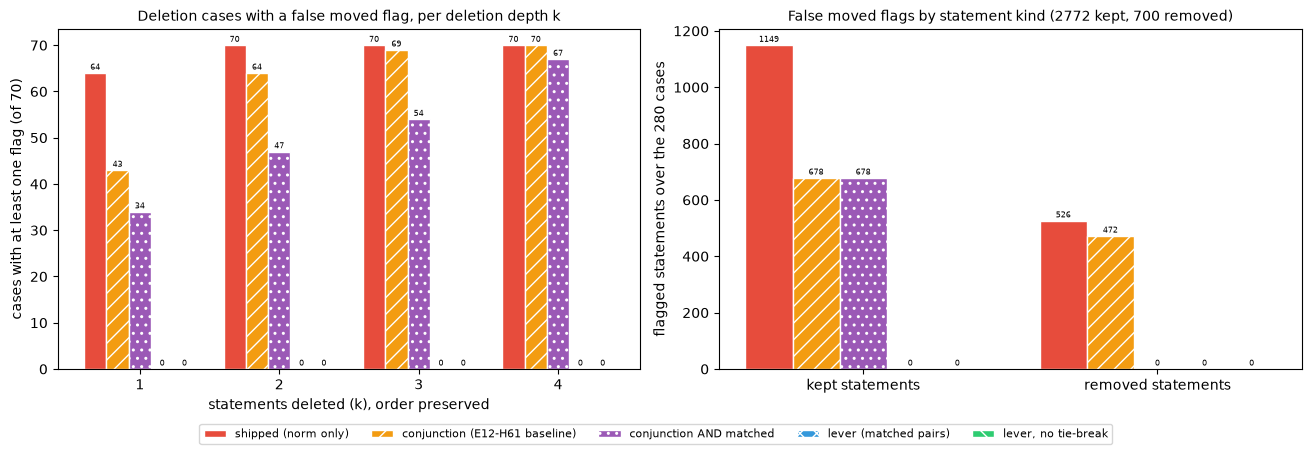

In [15]:
any_by_k = del_df.group_by("k").agg([pl.col(f"any_{arm}").sum() for arm in FLAG_ARMS]).sort("k")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)
grouped_bars(axes[0], any_by_k["k"].to_list(), {arm: any_by_k[f"any_{arm}"].to_numpy() for arm in FLAG_ARMS},
             "cases with at least one flag (of 70)", "Deletion cases with a false moved flag, per deletion depth k")
axes[0].set_xlabel("statements deleted (k), order preserved")
grouped_bars(axes[1], ["kept statements", "removed statements"],
             {arm: [DEL_SUMMARY[arm]["flagged_kept"], DEL_SUMMARY[arm]["flagged_removed"]] for arm in FLAG_ARMS},
             "flagged statements over the 280 cases", f"False moved flags by statement kind ({DEL_KEPT_TOTAL} kept, {DEL_REMOVED_TOTAL} removed)")
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=8, loc="outside lower center", ncol=5)
plt.show()

## Clause 2 - verbatim reorder pool

The registered clause: on every permutation of the verbatim reorder pool (1680, all fully matched) the lever's flag
array is `np.array_equal` to the conjunction's flag array. The comparison is made per permutation over the
per-statement arrays, never over counts. The table also reads how many pairs are fully matched and on how many the
matching is the exact-plan alignment, which is the mechanism the record names.

In [16]:
pool_eq_rows = []
for pair in POOL_PAIRS:
    A = EMB[pair["base"]]
    pair["flags"] = arm_flags(pair["details"], A, A[pair["perm"]])
    row = {"base": pair["base"], "k": pair["k"], **case_counts(pair["flags"], pair["relocated"], np.ones(len(A), dtype=bool))}
    row |= {f"equal_{arm}": bool(np.array_equal(pair["flags"][arm], pair["flags"]["conjunction"])) for arm in FLAG_ARMS}
    pool_eq_rows.append(row)
POOL_EQUAL = {arm: total(pool_eq_rows, f"equal_{arm}") for arm in FLAG_ARMS}
POOL_FULLY_MATCHED, POOL_SAME_MAP = total(pool_eq_rows, "fully_matched"), total(pool_eq_rows, "same_map")
POOL_TRUE = total(pool_eq_rows, "n_true")
POOL_IN_PLACE = total(pool_eq_rows, "n_a") - POOL_TRUE
POOL_RULE_ACTED = total(pool_eq_rows, "rule_acted")
CLAUSE2_MET = bool(len(pool_eq_rows) == N_POOL_PERMUTATIONS and POOL_EQUAL["lever"] == N_POOL_PERMUTATIONS)

c2_colour = "dark_sea_green" if CLAUSE2_MET else "indian_red"
console.print(Group(
    make_table(f"Clause 2 - every arm against the conjunction on the {len(pool_eq_rows)} verbatim permutations",
               ["arm", "permutations with flags np.array_equal to the conjunction", "true relocations flagged", "false fires on in-place statements"],
               [[ARM_LABEL[arm], f"{POOL_EQUAL[arm]}/{len(pool_eq_rows)}", f"{total(pool_eq_rows, f'tp_{arm}')}/{POOL_TRUE}",
                 f"{total(pool_eq_rows, f'fp_kept_{arm}')}/{POOL_IN_PLACE}"] for arm in FLAG_ARMS]),
    Panel(
        f"[bold {c2_colour}]clause 2 {'MET' if CLAUSE2_MET else 'NOT MET'}[/bold {c2_colour}]: lever flags np.array_equal to the conjunction flags on"
        f" {POOL_EQUAL['lever']}/{len(pool_eq_rows)} permutations (bar {N_POOL_PERMUTATIONS}/{N_POOL_PERMUTATIONS})\n"
        f"fully matched pairs: {POOL_FULLY_MATCHED}/{len(pool_eq_rows)} | matching equal to the exact-plan alignment: {POOL_SAME_MAP}/{len(pool_eq_rows)}"
        f" | statements the no_counterpart rule switched off in the lever: {POOL_RULE_ACTED}\n"
        f"scope: documents of {N_MIN} to {N_MAX} statements, where one rank step is at least 1/{N_MAX} = {1 / N_MAX:.4f} and above the tolerance {MOVED_TOLERANCE}",
        border_style=c2_colour, expand=False)))

                  Clause 2 - every arm against the conjunction on the 1680 verbatim permutations                   
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                            ┃    permutations with flags ┃                          ┃                            ┃
┃                            ┃      np.array_equal to the ┃                          ┃    false fires on in-place ┃
┃ arm                        ┃                conjunction ┃ true relocations flagged ┃                 statements ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ shipped (norm only)        │                  1680/1680 │              13675/13675 │                     0/7157 │
│ conjunction (E12-H61       │                  1680/1680 │              13675/13675 │                     0/7157 │
│ baseline)                  │                            │                          │                            │
│ conjunction AND matched    │                  1680/1680 │              13675/13675 │                     0/7157 │
│ lever (matched pairs)      │                  1680/1680 │              13675/13675 │                     0/7157 │
│ lever, no tie-break        │                  1680/1680 │              13675/13675 │                     0/7157 │
└────────────────────────────┴────────────────────────────┴──────────────────────────┴────────────────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 2 MET: lever flags np.array_equal to the conjunction flags on 1680/1680 permutations (bar 1680/1680)     │
│ fully matched pairs: 1680/1680 | matching equal to the exact-plan alignment: 1680/1680 | statements the         │
│ no_counterpart rule switched off in the lever: 0                                                                │
│ scope: documents of 11 to 14 statements, where one rank step is at least 1/14 = 0.0714 and above the tolerance  │
│ 0.05                                                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Clause 3 - reworded reorders

The registered clause: with `A` the base document and `B` its back-translation in the permuted order, the lever flags
at least 98% of the truly relocated statements that the conjunction flags, pooled over the 10 bases and the same 1680
permutations. Ground truth is the E12-H61 rule applied to the permutation. The first cell checks the one-to-one
statement alignment of every `<base>~bt` document before it is used as ground truth, under the executor rule of the
configuration cell.

In [17]:
bt_rows = []
for base in BASES:
    key = f"{base}~bt"
    n = len(STATEMENTS[base]["statements"])
    cost = cost_matrix(EMB[base], EMB[key])
    same_count = bool(len(STATEMENTS[key]["statements"]) == n)
    rows_, cols_ = match_pairs(cost, C_MATCH, EPS_TIE)
    row = {
        "base": base, "n": n, "n_bt": len(STATEMENTS[key]["statements"]),
        "names_base": bool(STATEMENTS[key].get("paraphrase_of") == base),
        "stored_equal": bool(json.loads((PARAPHRASE_DIR / f"{base}.bt.json").read_text()) == STATEMENTS[key]["statements"]),
        "row_min_on_diagonal": int((cost.argmin(1) == np.arange(n)).sum()) if same_count else 0,
        "col_min_on_diagonal": int((cost.argmin(0) == np.arange(n)).sum()) if same_count else 0,
        "true_cost_max": float(np.diag(cost).max()) if same_count else float("nan"),
        "true_at_or_above_c": int((np.diag(cost) >= C_MATCH).sum()) if same_count else -1,
        "other_cost_min": float(cost[~np.eye(n, dtype=bool)].min()) if same_count else float("nan"),
        "identity_matching": bool(len(rows_) == n and np.array_equal(rows_, cols_)),
    }
    row["aligned"] = bool(same_count and row["names_base"] and row["stored_equal"] and row["row_min_on_diagonal"] == n and row["col_min_on_diagonal"] == n)
    bt_rows.append(row)
bt_df = pl.DataFrame(bt_rows)
TRUE_COSTS = np.concatenate([np.diag(cost_matrix(EMB[base], EMB[f"{base}~bt"])) for base in BASES])   # ground cost of every statement and its reword
USABLE_BASES = bt_df.filter(pl.col("aligned"))["base"].to_list()
LEFT_OUT_BASES = bt_df.filter(~pl.col("aligned"))["base"].to_list()
BT_STATEMENTS = int(bt_df["n"].sum())
BT_TRUE_COST_MAX = float(bt_df["true_cost_max"].max())
BT_TRUE_AT_OR_ABOVE_C = int(bt_df["true_at_or_above_c"].sum())

console.print(Group(
    make_table("Back-translation alignment - <base>~bt against its base, before use as ground truth",
               ["base", "n", "~bt n", "names base", "equals .bt.json", "row min on diagonal", "col min on diagonal",
                "true-pair cost max", f"true pairs >= {C_MATCH}", "smallest other cost", "matching = identity", "aligned"],
               [[row["base"], row["n"], row["n_bt"], row["names_base"], row["stored_equal"], f"{row['row_min_on_diagonal']}/{row['n']}",
                 f"{row['col_min_on_diagonal']}/{row['n']}", f"{row['true_cost_max']:.6f}", row["true_at_or_above_c"],
                 f"{row['other_cost_min']:.6f}", row["identity_matching"], row["aligned"]] for row in bt_rows]),
    f"[bold]bases used: {len(USABLE_BASES)}/{len(BASES)} | left out: {LEFT_OUT_BASES or 'none'}[/bold]\n"
    f"true reworded pairs: {BT_STATEMENTS}; largest ground cost {BT_TRUE_COST_MAX:.6f}; at or above c = {C_MATCH}: {BT_TRUE_AT_OR_ABOVE_C}\n"
    f"[dim]'row min on diagonal' = statements of the base whose cheapest paraphrase statement has the same index; 'col min on diagonal' = the"
    f" reverse direction; 'matching = identity' = the lever's matching of the base with its unpermuted paraphrase pairs every statement with its own reword[/dim]"))

                Back-translation alignment - <base>~bt against its base, before use as ground truth                
┏━━━━━━━━┳━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┓
┃        ┃    ┃       ┃         ┃         ┃         ┃         ┃          ┃    true ┃          ┃         ┃         ┃
┃        ┃    ┃       ┃         ┃         ┃ row min ┃ col min ┃          ┃   pairs ┃ smallest ┃ matchi… ┃         ┃
┃        ┃    ┃       ┃   names ┃  equals ┃      on ┃      on ┃ true-pa… ┃      >= ┃    other ┃       = ┃         ┃
┃ base   ┃  n ┃ ~bt n ┃    base ┃ .bt.js… ┃ diagon… ┃ diagon… ┃ cost max ┃   0.325 ┃     cost ┃ identi… ┃ aligned ┃
┡━━━━━━━━╇━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━┩
│ gold   │ 11 │    11 │    True │    True │   11/11 │   11/11 │ 0.288564 │       0 │ 0.300420 │    True │    True │
│ gold-2 │ 13 │    13 │    True │    True │   13/13 │   13/13 │ 0.262141 │       0 │ 0.289713 │    True │    True │
│ v1     │ 12 │    12 │    True │    True │   12/12 │   12/12 │ 0.213628 │       0 │ 0.300738 │    True │    True │
│ v2     │ 12 │    12 │    True │    True │   12/12 │   12/12 │ 0.306936 │       0 │ 0.267236 │    True │    True │
│ opus   │ 13 │    13 │    True │    True │   13/13 │   13/13 │ 0.297756 │       0 │ 0.298978 │    True │    True │
│ sonnet │ 11 │    11 │    True │    True │   11/11 │   11/11 │ 0.235190 │       0 │ 0.301780 │    True │    True │
│ haiku  │ 14 │    14 │    True │    True │   14/14 │   14/14 │ 0.322901 │       0 │ 0.319761 │    True │    True │
│ werg-a │ 11 │    11 │    True │    True │   11/11 │   11/11 │ 0.222005 │       0 │ 0.310580 │    True │    True │
│ werg-b │ 13 │    13 │    True │    True │   13/13 │   13/13 │ 0.256245 │       0 │ 0.345062 │    True │    True │
│ werg-c │ 14 │    14 │    True │    True │   14/14 │   14/14 │ 0.218599 │       0 │ 0.310807 │    True │    True │
└────────┴────┴───────┴─────────┴─────────┴─────────┴─────────┴──────────┴─────────┴──────────┴─────────┴─────────┘
bases used: 10/10 | left out: none
true reworded pairs: 124; largest ground cost 0.322901; at or above c = 0.325: 0
'row min on diagonal' = statements of the base whose cheapest paraphrase statement has the same index; 'col min on 
diagonal' = the reverse direction; 'matching = identity' = the lever's matching of the base with its unpermuted 
paraphrase pairs every statement with its own reword

In [18]:
rw_rows = []
RW_PAIRS = []                  # per reworded pair: ground cost, ground truth and exact-plan arms, kept for the cutoff pass
for pair in POOL_PAIRS:
    base, perm, truth = pair["base"], pair["perm"], pair["relocated"]
    if base not in USABLE_BASES:
        continue
    S, P = STATEMENTS[base]["statements"], STATEMENTS[f"{base}~bt"]["statements"]
    B = EMB[f"{base}~bt"][perm]
    flags, counts = score_pair(S, EMB[base], [P[j] for j in perm], B, truth, np.ones(len(S), dtype=bool))
    RW_PAIRS.append({"cost": cost_matrix(EMB[base], B), "truth": truth, "conjunction": flags["conjunction"], "no_counterpart": flags["no_counterpart"]})
    conj_true = truth & flags["conjunction"]                       # truly relocated statements the conjunction flags
    counts |= {"base": base, "k": pair["k"], "conj_true": int(conj_true.sum())}
    counts |= {f"ret_{arm}": int((conj_true & flags[arm]).sum()) for arm in FLAG_ARMS}
    counts |= {f"equal_{arm}": bool(np.array_equal(flags[arm], flags["conjunction"])) for arm in FLAG_ARMS}
    rw_rows.append(counts)
rw_df = pl.DataFrame(rw_rows)

RET_DEN = total(rw_rows, "conj_true")
RET_NUM = {arm: total(rw_rows, f"ret_{arm}") for arm in FLAG_ARMS}
RETENTION = RET_NUM["lever"] / RET_DEN
RW_TRUE = total(rw_rows, "n_true")
RW_IN_PLACE = total(rw_rows, "n_a") - RW_TRUE
RW_FALSE = {arm: total(rw_rows, f"fp_kept_{arm}") for arm in FLAG_ARMS}
RW_TP = {arm: total(rw_rows, f"tp_{arm}") for arm in FLAG_ARMS}
RW_FULLY_MATCHED, RW_SAME_MAP, RW_RULE_ACTED = total(rw_rows, "fully_matched"), total(rw_rows, "same_map"), total(rw_rows, "rule_acted")
RW_EQUAL = {arm: total(rw_rows, f"equal_{arm}") for arm in FLAG_ARMS}
CLAUSE3_MET = bool(RETENTION >= RETENTION_BAR and not LEFT_OUT_BASES)

rw_base = rw_df.group_by("base", maintain_order=True).agg(
    pl.len().alias("permutations"), pl.col("n_true").sum(), pl.col("conj_true").sum(), pl.col("ret_lever").sum(),
    pl.col("ret_lever_no_tiebreak").sum(), pl.col("fp_kept_lever").sum(), pl.col("fp_kept_conjunction").sum(),
    pl.col("fully_matched").sum(), pl.col("same_map").sum())
RET_BASE = {row["base"]: row["ret_lever"] / row["conj_true"] for row in rw_base.iter_rows(named=True)}

c3_colour = "dark_sea_green" if CLAUSE3_MET else "indian_red"
console.print(Group(
    make_table(f"Clause 3 - reworded reorders per base (A = base, B = back-translation in the permuted order), {len(rw_rows)} pairs",
               ["base", "permutations", "truly relocated", "of which conjunction flags", "of which lever flags", "retention",
                "lever false fires", "conjunction false fires", "fully matched", "matching = exact plan"],
               [[row["base"], row["permutations"], row["n_true"], row["conj_true"], row["ret_lever"], f"{row['ret_lever'] / row['conj_true']:.4f}",
                 row["fp_kept_lever"], row["fp_kept_conjunction"], f"{row['fully_matched']}/{row['permutations']}",
                 f"{row['same_map']}/{row['permutations']}"] for row in rw_base.iter_rows(named=True)]
               + [["all", len(rw_rows), RW_TRUE, RET_DEN, RET_NUM["lever"], f"{RETENTION:.4f}", RW_FALSE["lever"], RW_FALSE["conjunction"],
                   f"{RW_FULLY_MATCHED}/{len(rw_rows)}", f"{RW_SAME_MAP}/{len(rw_rows)}"]]),
    make_table("Reworded reorders per arm - retention of the conjunction-flagged true relocations, and false fires (no bar)",
               ["arm", "kept / conjunction-flagged true relocations", "retention", "true relocations flagged", "false fires on statements that did not relocate"],
               [[ARM_LABEL[arm], f"{RET_NUM[arm]}/{RET_DEN}", f"{RET_NUM[arm] / RET_DEN:.4f}", f"{RW_TP[arm]}/{RW_TRUE}",
                 f"{RW_FALSE[arm]}/{RW_IN_PLACE}"] for arm in FLAG_ARMS]),
    Panel(
        f"[bold {c3_colour}]clause 3 {'MET' if CLAUSE3_MET else 'NOT MET'}[/bold {c3_colour}]: the lever flags {RET_NUM['lever']}/{RET_DEN} ="
        f" {RETENTION:.6f} of the truly relocated statements the conjunction flags (bar >= {RETENTION_BAR}; prediction {PRED_RETENTION_MIN} to 1.00)\n"
        f"bases pooled: {len(USABLE_BASES)}/{len(BASES)} | smallest per-base retention: {min(RET_BASE.values()):.4f} ({min(RET_BASE, key=RET_BASE.get)})"
        f" | lever with no tie-break: {RET_NUM['lever_no_tiebreak']}/{RET_DEN} = {RET_NUM['lever_no_tiebreak'] / RET_DEN:.6f}\n"
        f"fully matched pairs: {RW_FULLY_MATCHED}/{len(rw_rows)}; matching equal to the exact-plan alignment: {RW_SAME_MAP}/{len(rw_rows)};"
        f" pairs on which the lever's flag array is np.array_equal to the conjunction's: {RW_EQUAL['lever']}/{len(rw_rows)}\n"
        f"statements the no_counterpart rule switched off in the lever: {RW_RULE_ACTED}",
        border_style=c3_colour, expand=False)))

     Clause 3 - reworded reorders per base (A = base, B = back-translation in the permuted order), 1680 pairs      
┏━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┓
┃        ┃           ┃           ┃  of which ┃  of which ┃          ┃     lever ┃ conjunc… ┃           ┃ matching ┃
┃        ┃           ┃     truly ┃ conjunct… ┃     lever ┃          ┃     false ┃    false ┃     fully ┃  = exact ┃
┃ base   ┃ permutat… ┃ relocated ┃     flags ┃     flags ┃ retenti… ┃     fires ┃    fires ┃   matched ┃     plan ┃
┡━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━┩
│ gold   │       168 │      1245 │      1245 │      1245 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ gold-2 │       168 │      1406 │      1406 │      1406 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ v1     │       168 │      1346 │      1346 │      1346 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ v2     │       168 │      1360 │      1360 │      1360 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ opus   │       168 │      1416 │      1416 │      1416 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ sonnet │       168 │      1242 │      1242 │      1242 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ haiku  │       168 │      1491 │      1491 │      1491 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ werg-a │       168 │      1237 │      1237 │      1237 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ werg-b │       168 │      1402 │      1402 │      1402 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ werg-c │       168 │      1530 │      1530 │      1530 │   1.0000 │         0 │        0 │   168/168 │  168/168 │
│ all    │      1680 │     13675 │     13675 │     13675 │   1.0000 │         0 │        0 │ 1680/1680 │ 1680/16… │
└────────┴───────────┴───────────┴───────────┴───────────┴──────────┴───────────┴──────────┴───────────┴──────────┘
    Reworded reorders per arm - retention of the conjunction-flagged true relocations, and false fires (no bar)    
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                        ┃                  kept / ┃           ┃                        ┃          false fires on ┃
┃                        ┃     conjunction-flagged ┃           ┃       true relocations ┃ statements that did not ┃
┃ arm                    ┃        true relocations ┃ retention ┃                flagged ┃                relocate ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ shipped (norm only)    │             13675/13675 │    1.0000 │            13675/13675 │                  0/7157 │
│ conjunction (E12-H61   │             13675/13675 │    1.0000 │            13675/13675 │                  0/7157 │
│ baseline)              │                         │           │                        │                         │
│ conjunction AND        │             13675/13675 │    1.0000 │            13675/13675 │                  0/7157 │
│ matched                │                         │           │                        │                         │
│ lever (matched pairs)  │             13675/13675 │    1.0000 │            13675/13675 │                  0/7157 │
│ lever, no tie-break    │             13675/13675 │    1.0000 │            13675/13675 │                  0/7157 │
└────────────────────────┴─────────────────────────┴───────────┴────────────────────────┴─────────────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 3 MET: the lever flags 13675/13675 = 1.000000 of the truly relocated statements the conjunction flags    │
│ (bar >= 0.98; prediction 0.99 to 1.00)                

The figure shows the reworded reorders. Left: per base, the share of the conjunction-flagged true relocations that each
matched arm keeps, against the registered bar (dashed). Right: the false fires of every arm on statements that did not
relocate, pooled. The reading to check is the distance of the lever bars from the dashed line and whether the lever
adds false fires.

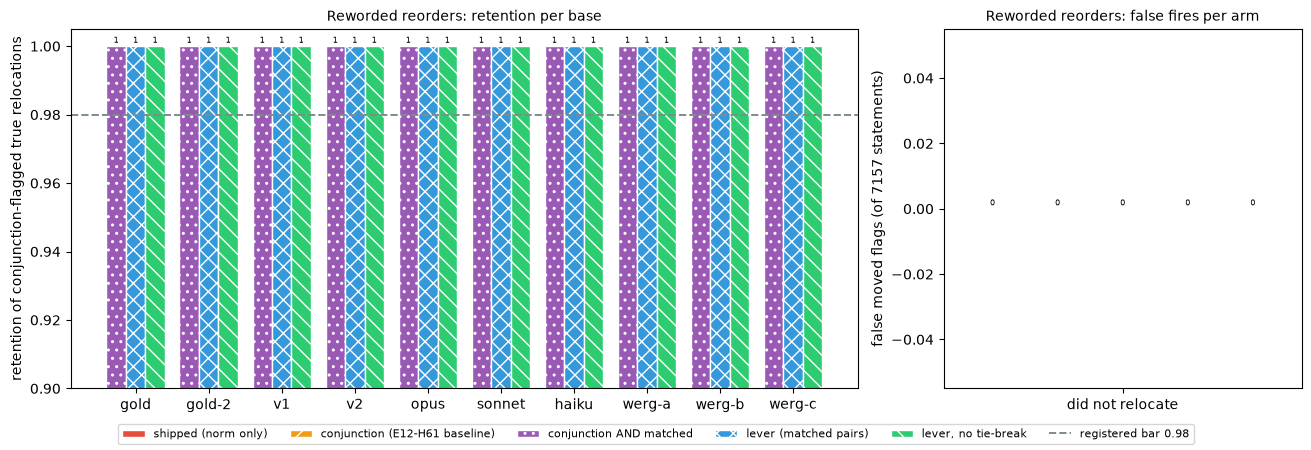

In [19]:
matched_arms = ("conjunction_and_matched", "lever", "lever_no_tiebreak")
ret_base = rw_df.group_by("base", maintain_order=True).agg(pl.col("conj_true").sum(), *[pl.col(f"ret_{arm}").sum() for arm in matched_arms])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True, gridspec_kw={"width_ratios": [2.2, 1]})
grouped_bars(axes[0], ret_base["base"].to_list(), {arm: (ret_base[f"ret_{arm}"] / ret_base["conj_true"]).to_numpy() for arm in matched_arms},
             "retention of conjunction-flagged true relocations", "Reworded reorders: retention per base")
axes[0].axhline(RETENTION_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"registered bar {RETENTION_BAR}")
axes[0].set_ylim(min(0.9, min(RET_BASE.values()) - 0.02), 1.005)
grouped_bars(axes[1], ["did not relocate"], {arm: [RW_FALSE[arm]] for arm in FLAG_ARMS},
             f"false moved flags (of {RW_IN_PLACE} statements)", "Reworded reorders: false fires per arm")
handles, labels = axes[1].get_legend_handles_labels()
bar_line = [(handle, label) for handle, label in zip(*axes[0].get_legend_handles_labels()) if label.startswith("registered bar")]
fig.legend(handles + [bar_line[0][0]], labels + [bar_line[0][1]], fontsize=8, loc="outside lower center", ncol=6)
plt.show()

## Clause 4 - the E12-H61 fixtures

The registered clause: the lever reads insertion 0 of 6, swap 2 of 2, reversal 12 of 12 and the 12 to 8 text shrinkage
0 of 12. The fixtures are the E12-H61 ones, unchanged. The record does not say which of the two E12-H61 reversal
fixtures it means, so the clause requires both; the orthogonal shrinkage fixture is reported beside the text one.

In [20]:
fixture_flags = {name: arm_flags(_build_structural_details(f["sa"], f["ea"], f["sb"], f["eb"]), f["ea"], f["eb"]) for name, f in FIXTURES.items()}
shrink_kept = np.zeros(SHRINK_N, dtype=bool)
shrink_kept[SHRINK_KEPT] = True


def fixture_reading(arm: str) -> dict:
    """The clause-4 readings of one arm as ``(flagged, of)`` pairs."""
    flagged = {name: fixture_flags[name][arm] for name in FIXTURES}
    return {
        "insertion": (int(flagged["insertion"].sum()), len(FIXTURES["insertion"]["sa"])),
        "swap": (int(flagged["worked_example"][list(SWAP_INDICES)].sum()), len(SWAP_INDICES)),
        "worked_example_all": (int(flagged["worked_example"].sum()), len(FIXTURES["worked_example"]["sa"])),
        "reversal_orth": (int(flagged["reversal_orth"].sum()), SHRINK_N),
        "reversal_text": (int(flagged["reversal_text"].sum()), SHRINK_N),
        "shrinkage": (int(flagged["shrink_text"].sum()), SHRINK_N),
        "shrinkage_kept": (int((flagged["shrink_text"] & shrink_kept).sum()), len(SHRINK_KEPT)),
        "shrinkage_removed": (int((flagged["shrink_text"] & ~shrink_kept).sum()), len(SHRINK_REMOVED)),
        "shrinkage_orth": (int(flagged["shrink_orth"].sum()), SHRINK_N),
    }


FIX_READ = {arm: fixture_reading(arm) for arm in FLAG_ARMS}
lever_fix = FIX_READ["lever"]
CLAUSE4 = {
    "insertion": lever_fix["insertion"] == FIXTURE_BAR["insertion"],
    "swap": lever_fix["swap"] == FIXTURE_BAR["swap"],
    "reversal": lever_fix["reversal_orth"] == FIXTURE_BAR["reversal"] and lever_fix["reversal_text"] == FIXTURE_BAR["reversal"],
    "shrinkage": lever_fix["shrinkage"] == FIXTURE_BAR["shrinkage"],
}
CLAUSE4_MET = bool(all(CLAUSE4.values()))
WORKED_UNMATCHED = np.flatnonzero(~fixture_flags["worked_example"]["matched"]).tolist()   # statements of the worked example without a match
FIX_ROWS = {"insertion": "insertion (bar 0 of 6)", "swap": "swap pair A2/A3 (bar 2 of 2)", "worked_example_all": "worked example, all 6 statements",
            "reversal_orth": "reversal, orthogonal (bar 12 of 12)", "reversal_text": "reversal, real text (bar 12 of 12)",
            "shrinkage": "12 to 8 text shrinkage (bar 0 of 12)", "shrinkage_kept": "text shrinkage, 8 kept", "shrinkage_removed": "text shrinkage, 4 removed",
            "shrinkage_orth": "12 to 8 orthogonal shrinkage"}

c4_colour = "dark_sea_green" if CLAUSE4_MET else "indian_red"
console.print(Group(
    make_table("Clause 4 - flagged statements per fixture and arm", ["reading", *[ARM_LABEL[arm] for arm in FLAG_ARMS]],
               [[label, *[f"{FIX_READ[arm][key][0]} of {FIX_READ[arm][key][1]}" for arm in FLAG_ARMS]] for key, label in FIX_ROWS.items()]),
    Panel(
        f"[bold {c4_colour}]clause 4 {'MET' if CLAUSE4_MET else 'NOT MET'}[/bold {c4_colour}]: lever reads insertion {lever_fix['insertion'][0]} of {lever_fix['insertion'][1]},"
        f" swap {lever_fix['swap'][0]} of {lever_fix['swap'][1]}, reversal {lever_fix['reversal_orth'][0]} of {lever_fix['reversal_orth'][1]} (orthogonal) and"
        f" {lever_fix['reversal_text'][0]} of {lever_fix['reversal_text'][1]} (real text), text shrinkage {lever_fix['shrinkage'][0]} of {lever_fix['shrinkage'][1]}\n"
        f"per part: {CLAUSE4}\n"
        f"conjunction baseline on the text shrinkage: {FIX_READ['conjunction']['shrinkage_kept'][0]} of 8 kept and"
        f" {FIX_READ['conjunction']['shrinkage_removed'][0]} of 4 removed statements flagged (DEF-TRANS-13)\n"
        f"worked example: statements of A without a match at c = {C_MATCH}: {WORKED_UNMATCHED}; flagged by the conjunction"
        f" {np.flatnonzero(fixture_flags['worked_example']['conjunction']).tolist()}, by the lever {np.flatnonzero(fixture_flags['worked_example']['lever']).tolist()}",
        border_style=c4_colour, expand=False)))

                                 Clause 4 - flagged statements per fixture and arm                                 
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃                  ┃                  ┃      conjunction ┃                  ┃                  ┃                  ┃
┃                  ┃    shipped (norm ┃         (E12-H61 ┃  conjunction AND ┃   lever (matched ┃        lever, no ┃
┃ reading          ┃            only) ┃        baseline) ┃          matched ┃           pairs) ┃        tie-break ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ insertion (bar 0 │           4 of 6 │           0 of 6 │           0 of 6 │           0 of 6 │           0 of 6 │
│ of 6)            │                  │                  │                  │                  │                  │
│ swap pair A2/A3  │           2 of 2 │           2 of 2 │           2 of 2 │           2 of 2 │           2 of 2 │
│ (bar 2 of 2)     │                  │                  │                  │                  │                  │
│ worked example,  │           4 of 6 │           4 of 6 │           2 of 6 │           2 of 6 │           2 of 6 │
│ all 6 statements │                  │                  │                  │                  │                  │
│ reversal,        │         12 of 12 │         12 of 12 │         12 of 12 │         12 of 12 │         12 of 12 │
│ orthogonal (bar  │                  │                  │                  │                  │                  │
│ 12 of 12)        │                  │                  │                  │                  │                  │
│ reversal, real   │         12 of 12 │         12 of 12 │         12 of 12 │         12 of 12 │         12 of 12 │
│ text (bar 12 of  │                  │                  │                  │                  │                  │
│ 12)              │                  │                  │                  │                  │                  │
│ 12 to 8 text     │          2 of 12 │          2 of 12 │          0 of 12 │          0 of 12 │          0 of 12 │
│ shrinkage (bar 0 │                  │                  │                  │                  │                  │
│ of 12)           │                  │                  │                  │                  │                  │
│ text shrinkage,  │           0 of 8 │           0 of 8 │           0 of 8 │           0 of 8 │           0 of 8 │
│ 8 kept           │                  │                  │                  │                  │                  │
│ text shrinkage,  │           2 of 4 │           2 of 4 │           0 of 4 │           0 of 4 │           0 of 4 │
│ 4 removed        │                  │                  │                  │                  │                  │
│ 12 to 8          │          0 of 12 │          0 of 12 │          0 of 12 │          0 of 12 │          0 of 12 │
│ orthogonal       │                  │                  │                  │                  │                  │
│ shrinkage        │                  │                  │                  │                  │                  │
└──────────────────┴──────────────────┴──────────────────┴──────────────────┴──────────────────┴──────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 4 MET: lever reads insertion 0 of 6, swap 2 of 2, reversal 12 of 12 (orthogonal) and 12 of 12 (real      │
│ text), text shrinkage 0 of 12                                                                                   │
│ per part: {'insertion': True, 'swap': True, 'reversal': True, 'shrinkage': True}                                │
│ conjunction baseline on the text shrinkage: 0 of 8 kept and 2 of 4 removed statements flagged (DEF-TRANS-13)    │
│ worked example: statements of A without a match at c =

The figure shows the flagged statements of every arm on each fixture reading of the clause. The reading to check is
that the lever is at zero on the insertion and shrinkage fixtures and at the full count on the swap and reversal
fixtures.

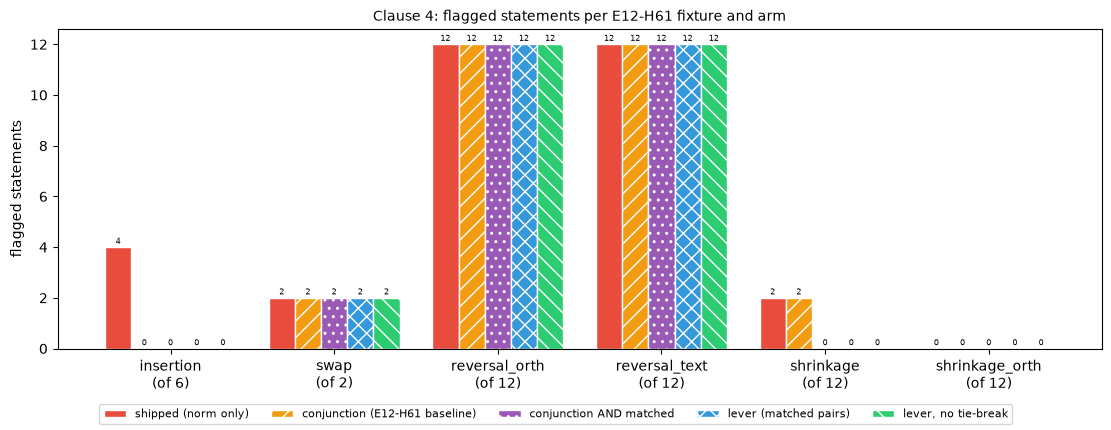

In [21]:
fix_keys = ("insertion", "swap", "reversal_orth", "reversal_text", "shrinkage", "shrinkage_orth")
fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
grouped_bars(ax, [f"{key}\n(of {FIX_READ['lever'][key][1]})" for key in fix_keys], {arm: [FIX_READ[arm][key][0] for key in fix_keys] for arm in FLAG_ARMS},
             "flagged statements", "Clause 4: flagged statements per E12-H61 fixture and arm")
fig.legend(fontsize=8, loc="outside lower center", ncol=5)
plt.show()

## Reported without a bar - reordered-and-deleted cases

The record asks for the per-statement precision and recall of each arm against a rank-among-survivors ground truth on
the E13-H70 ladder with 2 deletions. Every unique permutation of the reorder pool is applied to its base and each of
the 7 `k=2` deletion plans is applied to the reordered document. A surviving statement truly relocated when its rank
among the survivors differs between the order of `A` and the order of `B`; a removed statement did not relocate.

In [22]:
def survivors_truth(n_a: int, survivors: np.ndarray) -> np.ndarray:
    """Rank-among-survivors ground truth of a reordered-and-deleted pair.

    ``survivors[q]`` is the index in ``A`` of the statement at position ``q`` of ``B``. A surviving statement
    truly relocated when its rank among the survivors in ``A`` order differs from ``q``. Removed statements read false.
    """
    truth = np.zeros(n_a, dtype=bool)
    truth[survivors] = np.argsort(np.argsort(survivors)) != np.arange(len(survivors))
    return truth


UNIQUE_PERMS = []              # one entry per unique permutation of every base (the E13-H70 list)
for base in BASES:
    seen = set()
    for entry in REORDER[base]:
        perm = tuple(entry["perm"])
        if perm not in seen:
            seen.add(perm)
            UNIQUE_PERMS.append({"base": base, "perm": list(perm), "disp": entry["disp"], "rung": rung_of(entry["disp"])})
PLANS_K2 = {base: deletion_plans(base_index, len(EMB[base]), K_LADDER) for base_index, base in enumerate(BASES)}
print(f"{len(UNIQUE_PERMS)} unique permutations over {len(BASES)} bases (pool entries: {sum(len(v) for v in REORDER.values())})"
      f" | {sum(len(v) for v in PLANS_K2.values())} k={K_LADDER} deletion plans")

1611 unique permutations over 10 bases (pool entries: 1820) | 70 k=2 deletion plans


In [23]:
ladder_rows = []
for item in tqdm(UNIQUE_PERMS, desc="unique permutations", mininterval=15.0, file=sys.stdout):
    S, A = STATEMENTS[item["base"]]["statements"], EMB[item["base"]]
    Y = A[item["perm"]]
    for plan in PLANS_K2[item["base"]]:
        survivors = np.asarray(item["perm"])[plan["keep"]]
        kept = np.zeros(len(S), dtype=bool)
        kept[survivors] = True
        flags, counts = score_pair(S, A, [S[j] for j in survivors], Y[plan["keep"]], survivors_truth(len(S), survivors), kept)
        rows, cols = flags["pairs"]
        ladder_rows.append({"base": item["base"], "rung": item["rung"], "family": plan["family"],
                            "recovered": bool(len(rows) == len(survivors) and np.array_equal(rows, survivors[cols])), **counts})
ladder_df = pl.DataFrame(ladder_rows)

unique permutations:   0%|          | 0/1611 [00:00<?, ?it/s]

unique permutations: 100%|██████████| 1611/1611 [00:10<00:00, 146.75it/s]

In [24]:
def precision_recall(frame: pl.DataFrame, arm: str) -> dict:
    """Pooled per-statement counts, precision and recall of one arm over the rows of ``frame``."""
    tp, fp_kept, fp_removed = int(frame[f"tp_{arm}"].sum()), int(frame[f"fp_kept_{arm}"].sum()), int(frame[f"fp_removed_{arm}"].sum())
    n_true = int(frame["n_true"].sum())
    flagged = tp + fp_kept + fp_removed
    return {"tp": tp, "fp_kept": fp_kept, "fp_removed": fp_removed, "fn": n_true - tp, "n_true": n_true,
            "precision": tp / flagged if flagged else None, "recall": tp / n_true if n_true else None}


def ratio(value: float | None) -> str:
    """A precision or recall value at 4 decimals, or ``n/a`` when its denominator is zero."""
    return "n/a" if value is None else f"{value:.4f}"


LADDER = {arm: precision_recall(ladder_df, arm) for arm in FLAG_ARMS}
LADDER_RUNG = {arm: {r: precision_recall(ladder_df.filter(pl.col("rung") == r), arm) for r in range(1, N_RUNGS + 1)} for arm in FLAG_ARMS}
LADDER_STATEMENTS = int(ladder_df["n_a"].sum())
LADDER_REMOVED = int(ladder_df["n_removed"].sum())
LADDER_RUNG_CASES = {r: ladder_df.filter(pl.col("rung") == r).height for r in range(1, N_RUNGS + 1)}
LADDER_RECOVERED = int(ladder_df["recovered"].sum())                # cases in which every survivor is matched with its own copy
LADDER_MATCHED_MIN, LADDER_MATCHED_MAX = int(ladder_df["n_matched"].min()), int(ladder_df["n_matched"].max())

console.print(Group(
    make_table(f"Reordered-and-deleted ladder (k={K_LADDER}) - per-statement precision and recall against rank-among-survivors ground truth,"
               f" {ladder_df.height} cases, {LADDER_STATEMENTS} statements of A",
               ["arm", "true positives", "false fires on kept", "false fires on removed", "missed", "precision", "recall"],
               [[ARM_LABEL[arm], f"{v['tp']}/{v['n_true']}", v["fp_kept"], f"{v['fp_removed']}/{LADDER_REMOVED}", v["fn"],
                 ratio(v["precision"]), ratio(v["recall"])] for arm, v in LADDER.items()]),
    make_table("Per E11 rung of the permutation - precision / recall",
               ["rung", "cases", *[ARM_LABEL[arm] for arm in FLAG_ARMS]],
               [[r, LADDER_RUNG_CASES[r], *[f"{ratio(LADDER_RUNG[arm][r]['precision'])} / {ratio(LADDER_RUNG[arm][r]['recall'])}" for arm in FLAG_ARMS]]
                for r in range(1, N_RUNGS + 1)]),
    f"the matching pairs every survivor with its own copy in {LADDER_RECOVERED}/{ladder_df.height} cases; matched pairs per case: {LADDER_MATCHED_MIN} to"
    f" {LADDER_MATCHED_MAX}, so one rank step is at least 1/{LADDER_MATCHED_MAX} = {1 / LADDER_MATCHED_MAX:.4f} and above the tolerance {MOVED_TOLERANCE}\n"
    f"[dim]no bar is registered for this table; fully matched pairs do not occur here (B is 2 statements shorter than A);"
    f" statements the no_counterpart rule switched off in the lever: {int(ladder_df['rule_acted'].sum())}[/dim]"))

Reordered-and-deleted ladder (k=2) - per-statement precision and recall against rank-among-survivors ground truth, 
                                        11277 cases, 139909 statements of A                                        
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━┓
┃                      ┃                ┃                     ┃      false fires on ┃        ┃           ┃        ┃
┃ arm                  ┃ true positives ┃ false fires on kept ┃             removed ┃ missed ┃ precision ┃ recall ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━┩
│ shipped (norm only)  │    77921/83778 │               11131 │         18304/22554 │   5857 │    0.7258 │ 0.9301 │
│ conjunction (E12-H61 │    73549/83778 │                5482 │         17444/22554 │  10229 │    0.7624 │ 0.8779 │
│ baseline)            │                │                     │                     │        │           │        │
│ conjunction AND      │    73549/83778 │                5482 │             0/22554 │  10229 │    0.9306 │ 0.8779 │
│ matched              │                │                     │                     │        │           │        │
│ lever (matched       │    83778/83778 │                   0 │             0/22554 │      0 │    1.0000 │ 1.0000 │
│ pairs)               │                │                     │                     │        │           │        │
│ lever, no tie-break  │    83778/83778 │                   0 │             0/22554 │      0 │    1.0000 │ 1.0000 │
└──────────────────────┴────────────────┴─────────────────────┴─────────────────────┴────────┴───────────┴────────┘
                               Per E11 rung of the permutation - precision / recall                                
┏━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃      ┃       ┃                   ┃       conjunction ┃                   ┃                   ┃                  ┃
┃      ┃       ┃     shipped (norm ┃          (E12-H61 ┃   conjunction AND ┃    lever (matched ┃        lever, no ┃
┃ rung ┃ cases ┃             only) ┃         baseline) ┃           matched ┃            pairs) ┃        tie-break ┃
┡━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ 1    │  1267 │   0.3421 / 0.8403 │   0.4165 / 0.7587 │   0.5726 / 0.7587 │   1.0000 / 1.0000 │  1.0000 / 1.0000 │
│ 2    │  1904 │   0.5787 / 0.8673 │   0.6372 / 0.7830 │   0.8236 / 0.7830 │   1.0000 / 1.0000 │  1.0000 / 1.0000 │
│ 3    │  2191 │   0.7312 / 0.9088 │   0.7653 / 0.8441 │   0.9400 / 0.8441 │   1.0000 / 1.0000 │  1.0000 / 1.0000 │
│ 4    │  2905 │   0.7991 / 0.9398 │   0.8151 / 0.8912 │   0.9761 / 0.8912 │   1.0000 / 1.0000 │  1.0000 / 1.0000 │
│ 5    │  2009 │   0.8183 / 0.9622 │   0.8289 / 0.9234 │   0.9826 / 0.9234 │   1.0000 / 1.0000 │  1.0000 / 1.0000 │
│ 6    │  1001 │   0.8154 / 0.9731 │   0.8297 / 0.9491 │   0.9850 / 0.9491 │   1.0000 / 1.0000 │  1.0000 / 1.0000 │
└──────┴───────┴───────────────────┴───────────────────┴───────────────────┴───────────────────┴──────────────────┘
the matching pairs every survivor with its own copy in 11277/11277 cases; matched pairs per case: 9 to 12, so one 
rank step is at least 1/12 = 0.0833 and above the tolerance 0.05
no bar is registered for this table; fully matched pairs do not occur here (B is 2 statements shorter than A); 
statements the no_counterpart rule switched off in the lever: 0

The figure shows the pooled precision (left) and recall (right) of each arm per E11 rung of the permutation. The reading
to check is the gap between the exact-plan arms and the matched arms at the low rungs, where few statements relocate and
a false fire weighs most.

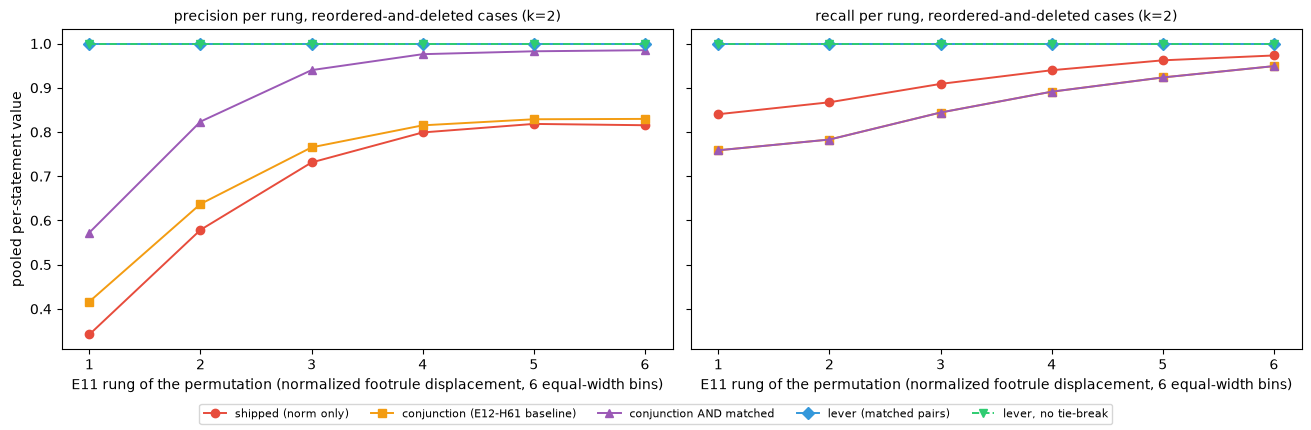

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True, sharey=True)
rungs = np.arange(1, N_RUNGS + 1)
for ax, measure in zip(axes, ("precision", "recall")):
    for arm in FLAG_ARMS:
        label, colour, _, marker = ARM_STYLE[arm]
        ax.plot(rungs, [np.nan if LADDER_RUNG[arm][r][measure] is None else LADDER_RUNG[arm][r][measure] for r in rungs], color=colour, marker=marker, ms=6, lw=1.4, label=label,
                ls="--" if arm == "lever_no_tiebreak" else "-")
    ax.set_xticks(rungs)
    ax.set_xlabel("E11 rung of the permutation (normalized footrule displacement, 6 equal-width bins)")
    ax.set_title(f"{measure} per rung, reordered-and-deleted cases (k={K_LADDER})", fontsize=10)
axes[0].set_ylabel("pooled per-statement value")
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=8, loc="outside lower center", ncol=5)
plt.show()

## Reported without a bar - tied plan rows

The record asks for the share of deletion cases in which two builds could differ: a removed statement whose exact-plan
row holds two equal largest entries. The exact plan is the coupling `order_alignment` takes its row argmax from
(`_aligned_plan`). A second reading goes one step further: every combination of the tied entries is taken as the
aligned target in turn, the flags the detail file would then carry are recomputed, and a case counts when two
combinations give different flag arrays. `flags_for_alignment` re-states the flag lines of the shipped builder for that
purpose; it is checked against the shipped records on the actual alignment first.

In [26]:
def flags_for_alignment(align: np.ndarray, cost: np.ndarray, lever_raw: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Shipped, conjunction and lever flags the detail file would carry if the crisp alignment were ``align``.

    Re-states the flag lines of the shipped builder: stable rank displacement, target-relative norm and the
    no_counterpart rule. Used only to evaluate the alternative argmax choices of a tied plan row.
    """
    n_a, n_b = cost.shape
    index = np.arange(n_a)
    displacement = np.argsort(np.argsort(align, kind="stable"), kind="stable") - index
    no_counterpart = cost[index, align] > NO_COUNTERPART_COST
    shipped = ~no_counterpart & (np.abs(align / n_b - index / n_a) > MOVED_TOLERANCE)
    return shipped, shipped & (displacement != 0), lever_raw & ~no_counterpart


TIE_ARMS = ("shipped", "conjunction", "lever")
tie_rows, tie_example = [], None
for entry in DEL:
    cost = cost_matrix(entry["A"], entry["B"])
    plan = _core._aligned_plan(entry["A"], entry["B"])              # the coupling order_alignment takes its argmax from
    align = plan.argmax(1)
    removed = np.flatnonzero(~entry["kept"])
    tied = [np.flatnonzero(plan[i].max() - plan[i] <= TIE_ATOL) for i in removed]
    tied_exact = [np.flatnonzero(plan[i] == plan[i].max()) for i in removed]
    n_resolutions = int(np.prod([len(t) for t in tied]))
    assert n_resolutions <= TIE_COMBO_CAP, f"{n_resolutions} tie resolutions exceed the cap {TIE_COMBO_CAP}"
    variants = {arm: set() for arm in TIE_ARMS}
    for choice in itertools.product(*tied):
        alternative = align.copy()
        alternative[removed] = choice
        for arm, flagged in zip(TIE_ARMS, flags_for_alignment(alternative, cost, entry["flags"]["lever_raw"])):
            variants[arm].add(flagged.tobytes())
    actual = flags_for_alignment(align, cost, entry["flags"]["lever_raw"])
    if tie_example is None and any(len(t) >= 2 for t in tied):
        i = int(removed[[len(t) >= 2 for t in tied].index(True)])
        tie_example = {"base": entry["case"]["base"], "k": entry["case"]["k"], "family": entry["case"]["family"], "statement": i,
                       "n_a": len(entry["A"]), "n_b": len(entry["B"]), "aligned_target": int(align[i]),
                       "row_entries": [repr(float(v)) for v in np.sort(plan[i])[::-1][:4]],
                       "tied_targets": np.flatnonzero(plan[i].max() - plan[i] <= TIE_ATOL).tolist()}
    tie_rows.append({
        "k": entry["case"]["k"], "n_removed": len(removed),
        "alignment_equal": bool(np.array_equal(align, entry["record"]["target_index"])),
        "replica_equal": bool(all(np.array_equal(actual[p], entry["flags"][arm]) for p, arm in enumerate(TIE_ARMS))),
        "tied_statements": sum(len(t) >= 2 for t in tied), "tied_statements_exact": sum(len(t) >= 2 for t in tied_exact),
        "largest_tie": max(len(t) for t in tied), "n_resolutions": n_resolutions,
        **{f"variants_{arm}": len(v) for arm, v in variants.items()},
    })
tie_df = pl.DataFrame(tie_rows)

TIE_CASES = int((tie_df["tied_statements"] > 0).sum())
TIE_CASES_EXACT = int((tie_df["tied_statements_exact"] > 0).sum())
TIE_SHARE = TIE_CASES / tie_df.height
TIE_STATEMENTS, TIE_STATEMENTS_EXACT = int(tie_df["tied_statements"].sum()), int(tie_df["tied_statements_exact"].sum())
TIE_VARIES = {arm: int((tie_df[f"variants_{arm}"] > 1).sum()) for arm in TIE_ARMS}
TIE_REPLICA_OK = int((tie_df["alignment_equal"] & tie_df["replica_equal"]).sum())

tie_k = tie_df.group_by("k").agg(pl.len().alias("cases"), (pl.col("tied_statements") > 0).sum().alias("tied_cases"), pl.col("tied_statements").sum(),
                                 pl.col("n_removed").sum(), pl.col("largest_tie").max(), pl.col("n_resolutions").max(),
                                 *[(pl.col(f"variants_{arm}") > 1).sum().alias(f"varies_{arm}") for arm in TIE_ARMS]).sort("k")
console.print(Group(
    make_table(f"Tied plan rows on the {tie_df.height} deletion cases (two largest entries of a removed statement's row within {TIE_ATOL})",
               ["k", "cases", "cases with a tied removed statement", "tied removed statements", "largest tie", "most tie resolutions",
                "shipped flags vary", "conjunction flags vary", "lever flags vary"],
               [[row["k"], row["cases"], f"{row['tied_cases']}/{row['cases']}", f"{row['tied_statements']}/{row['n_removed']}", row["largest_tie"],
                 row["n_resolutions"], f"{row['varies_shipped']}/{row['cases']}", f"{row['varies_conjunction']}/{row['cases']}",
                 f"{row['varies_lever']}/{row['cases']}"] for row in tie_k.iter_rows(named=True)]
               + [["all", tie_df.height, f"{TIE_CASES}/{tie_df.height}", f"{TIE_STATEMENTS}/{int(tie_df['n_removed'].sum())}",
                   int(tie_df["largest_tie"].max()), int(tie_df["n_resolutions"].max()), f"{TIE_VARIES['shipped']}/{tie_df.height}",
                   f"{TIE_VARIES['conjunction']}/{tie_df.height}", f"{TIE_VARIES['lever']}/{tie_df.height}"]]),
    f"[bold]share of deletion cases where two builds could differ: {TIE_CASES}/{tie_df.height} = {TIE_SHARE:.4f}[/bold]"
    f" (under exact float equality of the two largest entries: {TIE_CASES_EXACT}/{tie_df.height}; tied removed statements {TIE_STATEMENTS}, exact {TIE_STATEMENTS_EXACT})\n"
    f"cases in which two tie resolutions give different flag arrays: shipped {TIE_VARIES['shipped']}/{tie_df.height},"
    f" conjunction {TIE_VARIES['conjunction']}/{tie_df.height}, lever {TIE_VARIES['lever']}/{tie_df.height}\n"
    f"check of the re-stated flag lines: alignment and all three flag arrays equal to the shipped records on the actual alignment in {TIE_REPLICA_OK}/{tie_df.height} cases\n"
    f"example - {tie_example['base']}, k={tie_example['k']}, {tie_example['family']} ({tie_example['n_a']} to {tie_example['n_b']} statements): removed statement"
    f" {tie_example['statement']} is aligned to target {tie_example['aligned_target']}; its 4 largest plan entries are {', '.join(tie_example['row_entries'])};"
    f" targets within {TIE_ATOL} of the largest: {tie_example['tied_targets']}"))

     Tied plan rows on the 280 deletion cases (two largest entries of a removed statement's row within 1e-12)      
┏━━━━━┳━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃     ┃       ┃  cases with ┃             ┃             ┃              ┃             ┃              ┃             ┃
┃     ┃       ┃      a tied ┃        tied ┃             ┃              ┃             ┃              ┃             ┃
┃     ┃       ┃     removed ┃     removed ┃             ┃     most tie ┃     shipped ┃  conjunction ┃ lever flags ┃
┃ k   ┃ cases ┃   statement ┃  statements ┃ largest tie ┃  resolutions ┃  flags vary ┃   flags vary ┃        vary ┃
┡━━━━━╇━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ 1   │    70 │       70/70 │       70/70 │          13 │           13 │       70/70 │        70/70 │        0/70 │
│ 2   │    70 │       70/70 │     140/140 │           6 │           36 │       57/70 │        69/70 │        0/70 │
│ 3   │    70 │       70/70 │     210/210 │           3 │           27 │       57/70 │        70/70 │        0/70 │
│ 4   │    70 │       49/70 │     170/280 │           3 │           24 │       37/70 │        48/70 │        0/70 │
│ all │   280 │     259/280 │     590/700 │          13 │           36 │     221/280 │      257/280 │       0/280 │
└─────┴───────┴─────────────┴─────────────┴─────────────┴──────────────┴─────────────┴──────────────┴─────────────┘
share of deletion cases where two builds could differ: 259/280 = 0.9250 (under exact float equality of the two 
largest entries: 245/280; tied removed statements 590, exact 524)
cases in which two tie resolutions give different flag arrays: shipped 221/280, conjunction 257/280, lever 0/280
check of the re-stated flag lines: alignment and all three flag arrays equal to the shipped records on the actual 
alignment in 280/280 cases
example - gold, k=1, head (11 to 10 statements): removed statement 0 is aligned to target 1; its 4 largest plan 
entries are 0.009090909090909094, 0.009090909090909094, 0.009090909090909094, 0.009090909090909094; targets within 
1e-12 of the largest: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

The figure shows, per deletion depth `k`, the number of the 70 cases that hold a tied removed statement, and the number
in which the choice among the tied entries changes the flag array of each arm. The reading to check is whether the
exact-plan arms follow the tie count and whether the lever stays at zero.

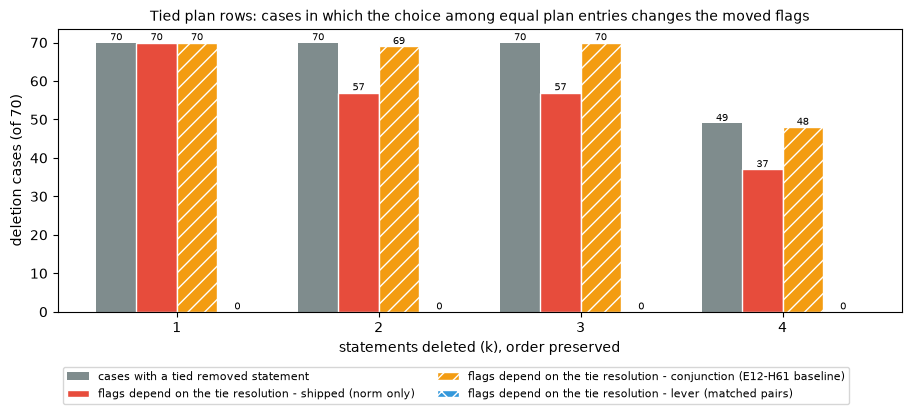

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.0), constrained_layout=True)
ks = tie_k["k"].to_list()
x = np.arange(len(ks))
ax.bar_label(ax.bar(x - 0.3, tie_k["tied_cases"].to_numpy(), 0.2, color=COL_REFERENCE, label="cases with a tied removed statement"), fontsize=7)
for position, arm in enumerate(TIE_ARMS):
    label, colour, hatch, _ = ARM_STYLE[arm]
    ax.bar_label(ax.bar(x - 0.1 + 0.2 * position, tie_k[f"varies_{arm}"].to_numpy(), 0.2, color=colour, hatch=hatch, edgecolor="white",
                        label=f"flags depend on the tie resolution - {label}"), fontsize=7)
ax.set_xticks(x, [str(k) for k in ks])
ax.set_xlabel("statements deleted (k), order preserved")
ax.set_ylabel("deletion cases (of 70)")
ax.set_title("Tied plan rows: cases in which the choice among equal plan entries changes the moved flags", fontsize=10)
fig.legend(fontsize=8, loc="outside lower center", ncol=2)
plt.show()

## Outside the record - the cutoff on the reworded reorders

An executor pass, with no registered bar and no part in the verdict. Clause 3 is read at the registered cutoff
`c = 0.325`, and every one of the 124 true reworded pairs of the fixture costs less than that. The cutoff therefore
never leaves a reworded statement unmatched in clause 3, which is the one way the lever can lose a flag the conjunction
keeps. This pass repeats the clause-3 reading at cutoffs below and above the registered one, on the same 1680 reworded
pairs, to show what the lever reads once true pairs cost at or above the cutoff.

In [28]:
sweep_rows = []
for c in C_SWEEP:
    kept_true = lost_unmatched = lost_matched = false_fires = fully_matched = 0
    for pair in RW_PAIRS:
        reading = lever_reading(pair["cost"], pair["no_counterpart"], EPS_TIE, c)
        conj_true = pair["truth"] & pair["conjunction"]
        kept_true += int((conj_true & reading["flags"]).sum())
        lost_unmatched += int((conj_true & ~reading["matched"]).sum())                      # the statement itself holds no match
        lost_matched += int((conj_true & reading["matched"] & ~reading["flags"]).sum())     # matched, rank among the matched unchanged
        false_fires += int((reading["flags"] & ~pair["truth"]).sum())
        fully_matched += int(len(reading["rows"]) == pair["cost"].shape[0])
    sweep_rows.append({"c": c, "true_pairs_at_or_above_c": int((TRUE_COSTS >= c).sum()), "kept": kept_true, "retention": kept_true / RET_DEN,
                       "lost_unmatched": lost_unmatched, "lost_matched": lost_matched, "false_fires": false_fires, "fully_matched": fully_matched})
SWEEP_REGISTERED_EQUAL = bool(next(row["kept"] for row in sweep_rows if row["c"] == C_MATCH) == RET_NUM["lever"])
SWEEP_BELOW_BAR = [row["c"] for row in sweep_rows if row["retention"] < RETENTION_BAR]
TRUE_COST_MARGIN = C_MATCH - float(TRUE_COSTS.max())

console.print(Group(
    make_table(f"Outside the record - clause-3 reading of the lever per cutoff, {len(RW_PAIRS)} reworded pairs (registered cutoff {C_MATCH})",
               ["cutoff c", f"true pairs at or above c (of {len(TRUE_COSTS)})", "kept / conjunction-flagged true relocations", "retention",
                "lost: statement unmatched", "lost: matched, rank unchanged", "false fires", "fully matched pairs"],
               [[f"{row['c']}" + (" (registered)" if row["c"] == C_MATCH else ""), row["true_pairs_at_or_above_c"], f"{row['kept']}/{RET_DEN}",
                 f"{row['retention']:.4f}", row["lost_unmatched"], row["lost_matched"], f"{row['false_fires']}/{RW_IN_PLACE}",
                 f"{row['fully_matched']}/{len(RW_PAIRS)}"] for row in sweep_rows]),
    f"[bold]largest true-pair cost {float(TRUE_COSTS.max()):.6f}: {TRUE_COST_MARGIN:.6f} below the registered cutoff {C_MATCH}[/bold]"
    f" | cutoffs of this table with retention below {RETENTION_BAR}: {SWEEP_BELOW_BAR or 'none'}\n"
    f"[dim]no bar is registered for this pass; the row at c = {C_MATCH} equals the clause-3 reading: {SWEEP_REGISTERED_EQUAL}[/dim]"))

   Outside the record - clause-3 reading of the lever per cutoff, 1680 reworded pairs (registered cutoff 0.325)    
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃              ┃              ┃       kept / ┃           ┃             ┃        lost: ┃             ┃             ┃
┃              ┃   true pairs ┃ conjunction… ┃           ┃       lost: ┃     matched, ┃             ┃       fully ┃
┃              ┃  at or above ┃         true ┃           ┃   statement ┃         rank ┃             ┃     matched ┃
┃ cutoff c     ┃   c (of 124) ┃  relocations ┃ retention ┃   unmatched ┃    unchanged ┃ false fires ┃       pairs ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ 0.25         │           11 │  12195/13675 │    0.8918 │        1216 │          264 │    789/7157 │    672/1680 │
│ 0.28         │            4 │  13084/13675 │    0.9568 │         445 │          146 │    336/7157 │   1008/1680 │
│ 0.3          │            2 │  13359/13675 │    0.9769 │         224 │           92 │    176/7157 │   1344/1680 │
│ 0.32         │            1 │  13530/13675 │    0.9894 │         102 │           43 │    112/7157 │   1512/1680 │
│ 0.325        │            0 │  13675/13675 │    1.0000 │           0 │            0 │      0/7157 │   1680/1680 │
│ (registered) │              │              │           │             │              │             │             │
│ 0.35         │            0 │  13675/13675 │    1.0000 │           0 │            0 │      0/7157 │   1680/1680 │
│ 0.45         │            0 │  13675/13675 │    1.0000 │           0 │            0 │      0/7157 │   1680/1680 │
│ 0.6          │            0 │  13675/13675 │    1.0000 │           0 │            0 │      0/7157 │   1680/1680 │
└──────────────┴──────────────┴──────────────┴───────────┴─────────────┴──────────────┴─────────────┴─────────────┘
largest true-pair cost 0.322901: 0.002099 below the registered cutoff 0.325 | cutoffs of this table with retention 
below 0.98: [0.25, 0.28, 0.3]
no bar is registered for this pass; the row at c = 0.325 equals the clause-3 reading: True

The figure shows the retention of the lever on the reworded reorders per cutoff, with the registered bar (dashed), the
registered cutoff (dotted) and the 124 true-pair costs as ticks on the lower edge. The reading to check is where the
retention leaves `1.0` relative to the largest true-pair cost.

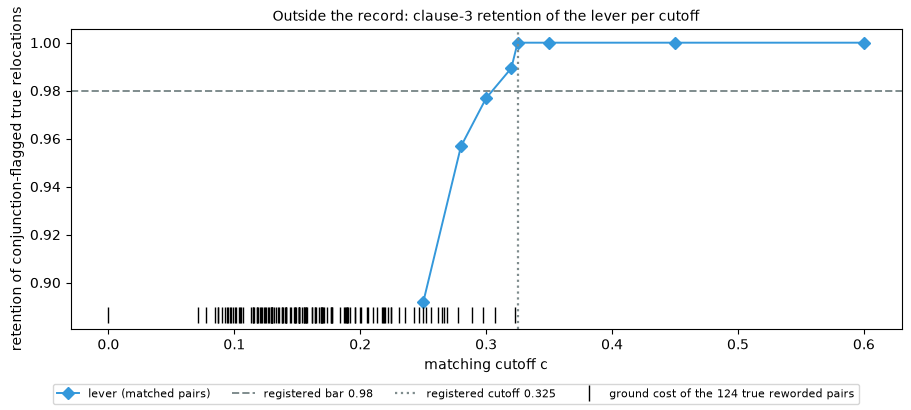

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.0), constrained_layout=True)
label, colour, _, marker = ARM_STYLE["lever"]
ax.plot([row["c"] for row in sweep_rows], [row["retention"] for row in sweep_rows], color=colour, marker=marker, ms=6, lw=1.4, label=label)
ax.axhline(RETENTION_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"registered bar {RETENTION_BAR}")
ax.axvline(C_MATCH, color=COL_REFERENCE, ls=":", lw=1.6, label=f"registered cutoff {C_MATCH}")
ax.plot(TRUE_COSTS, np.full(len(TRUE_COSTS), ax.get_ylim()[0]), "|", color="black", ms=12, label=f"ground cost of the {len(TRUE_COSTS)} true reworded pairs")
ax.set_xlabel("matching cutoff c")
ax.set_ylabel("retention of conjunction-flagged true relocations")
ax.set_title("Outside the record: clause-3 retention of the lever per cutoff", fontsize=10)
fig.legend(fontsize=8, loc="outside lower center", ncol=4)
plt.show()

## Outside the record - reworded survivors

An executor pass, with no registered bar and no part in the verdict. Clause 1 keeps the surviving statements
byte-identical, so every true pair costs about `0` and the cutoff `c = 0.325` cannot reject one. This pass repeats the
280 deletion plans with the survivors replaced by their back-translation: the pair is `(A, P minus k statements)`, where
statement `i` of `P` rewords statement `i` of `A`. Order is still preserved, so the ground truth is 0 moved, and each
true pair now has a ground cost that the cutoff could reject.

In [30]:
rwdel_rows = []
for entry in DEL:
    base, keep = entry["case"]["base"], entry["case"]["keep"]
    if base not in USABLE_BASES:
        continue
    P = STATEMENTS[f"{base}~bt"]["statements"]
    flags, counts = score_pair(entry["S"], entry["A"], [P[j] for j in keep], EMB[f"{base}~bt"][keep],
                               np.zeros(len(entry["S"]), dtype=bool), entry["kept"])
    rwdel_rows.append({"base": base, "k": entry["case"]["k"], "true_pairs_only": survivors_recovered(*flags["pairs"], keep), **counts})
RWDEL_SUMMARY = deletion_summary(rwdel_rows)
RWDEL_KEPT, RWDEL_REMOVED = total(rwdel_rows, "n_kept"), total(rwdel_rows, "n_removed")
RWDEL_TRUE_PAIRS_ONLY = total(rwdel_rows, "true_pairs_only")
RWDEL_SURVIVORS_MATCHED = total(rwdel_rows, "n_matched")

console.print(Group(
    make_table(f"Outside the record - the {len(rwdel_rows)} deletion plans on reworded survivors (ground truth: 0 moved)",
               ["arm", "flagged kept statements", "flagged removed statements", "cases with >= 1 flag"],
               [[ARM_LABEL[arm], f"{s['flagged_kept']}/{RWDEL_KEPT}", f"{s['flagged_removed']}/{RWDEL_REMOVED}", f"{s['cases_with_flag']}/{len(rwdel_rows)}"]
                for arm, s in RWDEL_SUMMARY.items()]),
    f"lever matching: every matched pair joins a statement with its own reword and every survivor is matched in {RWDEL_TRUE_PAIRS_ONLY}/{len(rwdel_rows)} cases;"
    f" survivors matched {RWDEL_SURVIVORS_MATCHED}/{RWDEL_KEPT}\n"
    f"[dim]no bar is registered for this pass; the largest ground cost of a true reworded pair is {BT_TRUE_COST_MAX:.6f} against c = {C_MATCH}[/dim]"))

           Outside the record - the 280 deletion plans on reworded survivors (ground truth: 0 moved)            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm                            ┃ flagged kept statements ┃ flagged removed statements ┃ cases with >= 1 flag ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ shipped (norm only)            │               1149/2772 │                    496/700 │              277/280 │
│ conjunction (E12-H61 baseline) │                704/2772 │                    454/700 │              250/280 │
│ conjunction AND matched        │                704/2772 │                      0/700 │              205/280 │
│ lever (matched pairs)          │                  0/2772 │                      0/700 │                0/280 │
│ lever, no tie-break            │                  0/2772 │                      0/700 │                0/280 │
└────────────────────────────────┴─────────────────────────┴────────────────────────────┴──────────────────────┘
lever matching: every matched pair joins a statement with its own reword and every survivor is matched in 280/280 
cases; survivors matched 2772/2772
no bar is registered for this pass; the largest ground cost of a true reworded pair is 0.322901 against c = 0.325

## Outside the record - a long document with repeated statements

An executor pass, with no registered bar and no part in the verdict. The 10 base documents hold 11 to 14 statements and
no repeated statement, so on the registered sets the zero-cost assignment is unique, the tie-break has nothing to
decide, and one rank step always exceeds the tolerance. This pass repeats the order-preserving deletion on the one long
document of the structure fixture, `source`, with the cases of the E13-H70 third pass: prefixes of increasing length, 2
interior deletions, 20 draws per length seeded `[7, prefix length, draw]`, in two arms - the document with its repeated
statements kept, and with every repeated statement removed. The ground truth is 0 moved in every case.

In [31]:
long_texts = STATEMENTS[LONG_DOC]["statements"]
long_counts = Counter(long_texts)
REPEATED_TEXTS = {text: n for text, n in long_counts.items() if n > 1}
REPEATED_POSITIONS = [i for i, text in enumerate(long_texts) if long_counts[text] > 1]
unique_positions = [i for i, text in enumerate(long_texts) if long_counts[text] == 1]
DOC_KEPT, DOC_REMOVED = "repeated statements kept", "repeated statements removed"
LONG_DOCS = {DOC_KEPT: (long_texts, EMB[LONG_DOC]), DOC_REMOVED: ([long_texts[i] for i in unique_positions], EMB[LONG_DOC][unique_positions])}


def prefix_lengths(n_doc: int) -> tuple[int, ...]:
    """The configured prefix lengths below the document length, then the document length itself."""
    return (*(p for p in LONG_PREFIXES if p < n_doc), n_doc)


long_rows = []
for doc_arm, (texts, doc) in LONG_DOCS.items():
    for n in prefix_lengths(len(doc)):
        S, A = texts[:n], doc[:n]
        for rep in range(LONG_REPS):
            drop = delete_positions(n, LONG_K, "interior", np.random.default_rng([LONG_SEED, n, rep]))
            keep = [i for i in range(n) if i not in drop]
            kept = np.zeros(n, dtype=bool)
            kept[keep] = True
            flags, counts = score_pair(S, A, [S[j] for j in keep], A[keep], np.zeros(n, dtype=bool), kept)
            rows, cols = flags["pairs"]
            long_rows.append({"doc_arm": doc_arm, "n": n, "rep": rep, "drop": drop,
                              "positional_lever": float(np.abs(rows / n - cols / len(keep)).sum()),
                              "positional_true": float(np.abs(np.asarray(keep) / n - np.arange(len(keep)) / len(keep)).sum()),
                              "lever_flagged": np.flatnonzero(flags["lever"]).tolist(),
                              "lever_unmatched": np.flatnonzero(~flags["matched"]).tolist(),
                              "recovered": survivors_recovered(*flags["pairs"], keep),
                              "recovered_no_tiebreak": survivors_recovered(*flags["pairs_no_tiebreak"], keep), **counts})
LIST_KEYS = ("drop", "lever_flagged", "lever_unmatched")           # per-case index lists, kept out of the frame
long_df = pl.DataFrame([{key: value for key, value in row.items() if key not in LIST_KEYS} for row in long_rows])

LONG = {doc_arm: deletion_summary([row for row in long_rows if row["doc_arm"] == doc_arm]) for doc_arm in LONG_DOCS}
LONG_CASES = {doc_arm: long_df.filter(pl.col("doc_arm") == doc_arm).height for doc_arm in LONG_DOCS}
LONG_RECOVERED = {doc_arm: {key: int(long_df.filter(pl.col("doc_arm") == doc_arm)[key].sum()) for key in ("recovered", "recovered_no_tiebreak")}
                  for doc_arm in LONG_DOCS}
LONG_PER_N = {doc_arm: {n: {arm: int(long_df.filter((pl.col("doc_arm") == doc_arm) & (pl.col("n") == n))[f"any_{arm}"].sum()) for arm in FLAG_ARMS}
                        for n in prefix_lengths(len(LONG_DOCS[doc_arm][1]))} for doc_arm in LONG_DOCS}
LONG_RECOVERED_PER_N = {doc_arm: {n: {key: int(long_df.filter((pl.col("doc_arm") == doc_arm) & (pl.col("n") == n))[key].sum())
                                      for key in ("recovered", "recovered_no_tiebreak")} for n in LONG_PER_N[doc_arm]} for doc_arm in LONG_DOCS}
LONG_LEVER_CASES = [{"doc_arm": row["doc_arm"], "n": row["n"], "deleted": row["drop"], "lever_flagged": row["lever_flagged"],
                     "lever_unmatched": row["lever_unmatched"], "repeated_in_prefix": [i for i in REPEATED_POSITIONS if i < row["n"]],
                     "survivors_recovered": row["recovered"], "positional_lever": sig(row["positional_lever"]),
                     "positional_true": sig(row["positional_true"]),
                     "positional_reading": ("equal" if abs(row["positional_lever"] - row["positional_true"]) <= TIE_ATOL
                                            else "lever matching smaller" if row["positional_lever"] < row["positional_true"] else "true matching smaller")}
                    for row in long_rows if row["any_lever"]]

console.print(Group(
    *[make_table(f"Outside the record - k={LONG_K} interior deletions on prefixes of '{LONG_DOC}', {doc_arm}: cases with >= 1 flag (of {LONG_REPS} per length)",
                 ["arm", *[f"n = {n}" for n in LONG_PER_N[doc_arm]], "all cases", "flagged kept", "flagged removed"],
                 [[ARM_LABEL[arm], *[LONG_PER_N[doc_arm][n][arm] for n in LONG_PER_N[doc_arm]], f"{LONG[doc_arm][arm]['cases_with_flag']}/{LONG_CASES[doc_arm]}",
                   LONG[doc_arm][arm]["flagged_kept"], LONG[doc_arm][arm]["flagged_removed"]] for arm in FLAG_ARMS]
                 + [[f"survivors recovered, {label}", *[LONG_RECOVERED_PER_N[doc_arm][n][key] for n in LONG_PER_N[doc_arm]],
                     f"{LONG_RECOVERED[doc_arm][key]}/{LONG_CASES[doc_arm]}", "-", "-"]
                    for key, label in (("recovered", "tie-break"), ("recovered_no_tiebreak", "no tie-break"))])
      for doc_arm in LONG_DOCS],
    make_table("Cases in which the lever flags a statement",
               ["document arm", "prefix length", "deleted positions", "statements the lever flags", "statements left unmatched",
                "repeated statements in the prefix", "positional term: lever matching", "positional term: true matching", "reading"],
               [[row["doc_arm"], row["n"], row["deleted"], row["lever_flagged"], row["lever_unmatched"], row["repeated_in_prefix"],
                 row["positional_lever"], row["positional_true"], row["positional_reading"]] for row in LONG_LEVER_CASES]
               or [["none", "-", "-", "-", "-", "-", "-", "-", "-"]]),
    f"[bold]'{LONG_DOC}': {len(long_texts)} statements, {len(REPEATED_POSITIONS)} of them carry a repeated text[/bold] - "
    + "; ".join(f"{text!r} x{n}" for text, n in REPEATED_TEXTS.items())
    + f"; with them removed: {len(unique_positions)} statements\n"
    + "\n".join(f"{doc_arm}: the matching pairs every survivor with its own copy in {LONG_RECOVERED[doc_arm]['recovered']}/{LONG_CASES[doc_arm]} cases"
                f" with the tie-break and in {LONG_RECOVERED[doc_arm]['recovered_no_tiebreak']}/{LONG_CASES[doc_arm]} without it" for doc_arm in LONG_DOCS)
    + "\n[dim]'positional term' = sum of abs(i / n - j / m) over the matched pairs, the quantity the tie-break minimizes among matchings of equal"
      " ground cost; 'true matching' = every survivor paired with its own copy. No bar is registered for this pass; one document; ground truth 0"
      " moved in every case[/dim]"))

Outside the record - k=2 interior deletions on prefixes of 'source', repeated statements kept: cases with >= 1 flag
                                                (of 20 per length)                                                 
┏━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃               ┃        ┃        ┃        ┃        ┃        ┃        ┃           ┃              ┃        flagged ┃
┃ arm           ┃ n = 14 ┃ n = 20 ┃ n = 30 ┃ n = 40 ┃ n = 50 ┃ n = 62 ┃ all cases ┃ flagged kept ┃        removed ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ shipped (norm │     19 │     20 │     19 │     15 │     16 │     19 │   108/120 │           97 │            117 │
│ only)         │        │        │        │        │        │        │           │              │                │
│ conjunction   │     19 │     20 │     19 │     15 │     16 │     19 │   108/120 │           72 │            110 │
│ (E12-H61      │        │        │        │        │        │        │           │              │                │
│ baseline)     │        │        │        │        │        │        │           │              │                │
│ conjunction   │     18 │      9 │      7 │      3 │      0 │      4 │    41/120 │           67 │              0 │
│ AND matched   │        │        │        │        │        │        │           │              │                │
│ lever         │      4 │      0 │      0 │      0 │      0 │      0 │     4/120 │            4 │              4 │
│ (matched      │        │        │        │        │        │        │           │              │                │
│ pairs)        │        │        │        │        │        │        │           │              │                │
│ lever, no     │      6 │      2 │      6 │     10 │      4 │      3 │    31/120 │           69 │             19 │
│ tie-break     │        │        │        │        │        │        │           │              │                │
│ survivors     │     15 │     20 │     17 │     18 │     20 │     20 │   110/120 │            - │              - │
│ recovered,    │        │        │        │        │        │        │           │              │                │
│ tie-break     │        │        │        │        │        │        │           │              │                │
│ survivors     │     14 │     18 │     13 │     10 │     16 │     17 │    88/120 │            - │              - │
│ recovered, no │        │        │        │        │        │        │           │              │                │
│ tie-break     │        │        │        │        │        │        │           │              │                │
└───────────────┴────────┴────────┴────────┴────────┴────────┴────────┴───────────┴──────────────┴────────────────┘
 Outside the record - k=2 interior deletions on prefixes of 'source', repeated statements removed: cases with >= 1 
                                              flag (of 20 per length)                                              
┏━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃               ┃        ┃        ┃        ┃        ┃        ┃        ┃           ┃              ┃        flagged ┃
┃ arm           ┃ n = 14 ┃ n = 20 ┃ n = 30 ┃ n = 40 ┃ n = 50 ┃ n = 53 ┃ all cases ┃ flagged kept ┃        removed ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ shipped (norm │     20 │     20 │     17 │     16 │     19 │     20 │   112/120 │           83 │            133 │
│ only)         │        │        │        │        │        │        │           │              │                │
│ conjunction   │     16 │     20 │     17 │     16 │     19 │     20 │   108/120 │           45 │            131 │
│ (E12-H61      │        │        │        │        │   

The figure shows, per prefix length and arm, the number of the 20 order-preserving deletion cases in which at least one
statement is flagged, for the document with its repeated statements kept (left) and removed (right). The reading to
check is whether the lever stays at zero and whether the lever without the tie-break does.

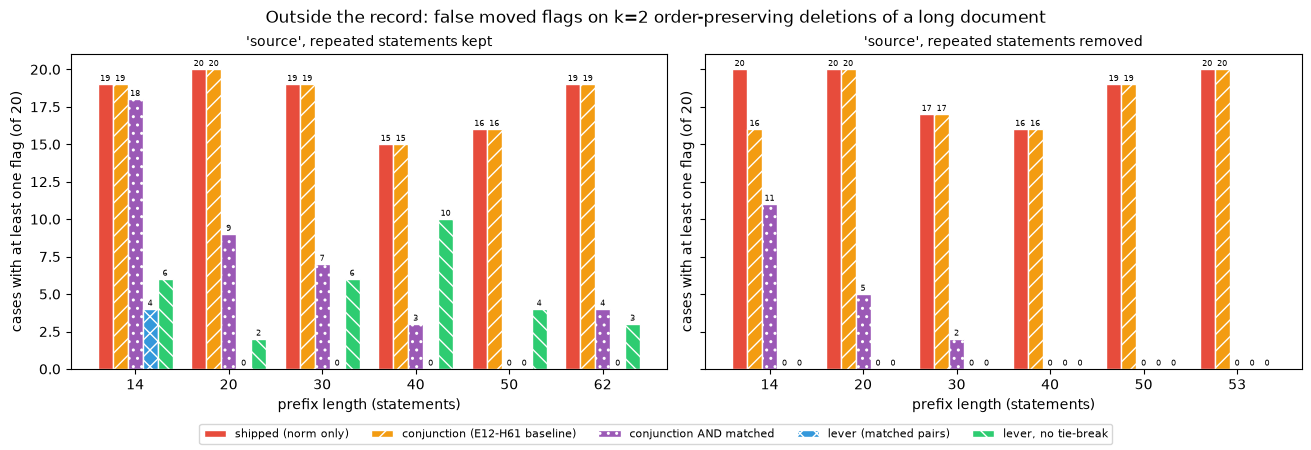

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True, sharey=True)
for ax, doc_arm in zip(axes, LONG_DOCS):
    lengths = list(LONG_PER_N[doc_arm])
    grouped_bars(ax, lengths, {arm: [LONG_PER_N[doc_arm][n][arm] for n in lengths] for arm in FLAG_ARMS},
                 f"cases with at least one flag (of {LONG_REPS})", f"'{LONG_DOC}', {doc_arm}")
    ax.set_xlabel("prefix length (statements)")
fig.suptitle(f"Outside the record: false moved flags on k={LONG_K} order-preserving deletions of a long document")
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=8, loc="outside lower center", ncol=5)
plt.show()

## Outside the record - lengths where one rank step equals the tolerance

An executor pass, with no registered bar and no part in the verdict. Clause 2 is read on documents of 11 to 14
statements, where one rank step is at least `1/14 = 0.0714` and above the tolerance `0.05`, so the tolerance term of
neither arm decides a flag. The two arms compute that term in different float forms: the shipped norm is
`j / n - i / n` and the lever is `(r_B - r_A) / n`. The first table scans every pair `(i, j)` of each length up to 100
for cells in which the two forms give a different threshold result. The second repeats clause 2 on every single
transposition of the first 14, 20 and 40 statements of `source` with its repeated statements removed.

In [33]:
SCAN = {}
for n in range(2, BOUNDARY_SCAN_MAX + 1):
    i, j = np.arange(n)[:, None], np.arange(n)[None, :]
    differs = (np.abs(j / n - i / n) > MOVED_TOLERANCE) != (np.abs((j - i) / n) > MOVED_TOLERANCE)
    if differs.any():
        SCAN[n] = {"cells": int(differs.sum()), "rank_steps": sorted({int(v) for v in np.abs(j - i)[differs]})}

unique_texts, unique_doc = LONG_DOCS[DOC_REMOVED]
boundary_rows = []
for n in BOUNDARY_LENGTHS:
    S, A = unique_texts[:n], unique_doc[:n]
    equal, fully_matched, differing = 0, 0, Counter()
    conjunction_only = lever_only = 0
    transpositions = list(itertools.combinations(range(n), 2))
    for p, q in transpositions:
        perm = np.arange(n)
        perm[[p, q]] = perm[[q, p]]
        flags = arm_flags(_build_structural_details(S, A, [S[k] for k in perm], A[perm]), A, A[perm])
        fully_matched += flags["fully_matched"]
        conjunction_only += int((flags["conjunction"] & ~flags["lever"]).sum())
        lever_only += int((flags["lever"] & ~flags["conjunction"]).sum())
        if np.array_equal(flags["lever"], flags["conjunction"]):
            equal += 1
        else:
            differing[q - p] += 1
    boundary_rows.append({"n": n, "transpositions": len(transpositions), "fully_matched": int(fully_matched), "equal": equal,
                          "differing_rank_steps": dict(sorted(differing.items())),
                          "statements_only_conjunction_flags": conjunction_only, "statements_only_lever_flags": lever_only})

console.print(Group(
    make_table(f"Arithmetic scan, lengths 2 to {BOUNDARY_SCAN_MAX}: cells (i, j) where abs(j/n - i/n) > {MOVED_TOLERANCE} and abs((j - i)/n) > {MOVED_TOLERANCE} differ",
               ["length n", "differing cells", "rank steps abs(j - i) of those cells"],
               [[n, row["cells"], row["rank_steps"]] for n, row in SCAN.items()] or [["none", 0, "-"]]),
    make_table(f"Clause 2 repeated on single transpositions of '{LONG_DOC}' (repeated statements removed)",
               ["length n", "transpositions", "fully matched", "lever flags np.array_equal to the conjunction", "rank steps of the differing transpositions: count",
                "statements only the conjunction flags", "statements only the lever flags"],
               [[row["n"], row["transpositions"], f"{row['fully_matched']}/{row['transpositions']}", f"{row['equal']}/{row['transpositions']}",
                 row["differing_rank_steps"] or "none", row["statements_only_conjunction_flags"], row["statements_only_lever_flags"]]
                for row in boundary_rows]),
    f"[dim]no bar is registered for this pass; lengths of the registered sets: {N_MIN} to {N_MAX}, none of them in the scan table: "
    f"{not any(N_MIN <= n <= N_MAX for n in SCAN)}[/dim]"))

Arithmetic scan, lengths 2 to 100: cells (i, j) where abs(j/n - i/n) 
               > 0.05 and abs((j - i)/n) > 0.05 differ               
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ length n ┃ differing cells ┃ rank steps abs(j - i) of those cells ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 20       │              14 │                                  [1] │
│ 40       │              30 │                                  [2] │
│ 60       │              44 │                                  [3] │
│ 80       │              62 │                                  [4] │
│ 100      │              76 │                                  [5] │
└──────────┴─────────────────┴──────────────────────────────────────┘
               Clause 2 repeated on single transpositions of 'source' (repeated statements removed)                
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃          ┃                ┃               ┃     lever flags ┃  rank steps of ┃                 ┃                ┃
┃          ┃                ┃               ┃  np.array_equal ┃  the differing ┃ statements only ┃     statements ┃
┃          ┃                ┃               ┃          to the ┃ transposition… ┃ the conjunction ┃ only the lever ┃
┃ length n ┃ transpositions ┃ fully matched ┃     conjunction ┃          count ┃           flags ┃          flags ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ 14       │             91 │         91/91 │           91/91 │           none │               0 │              0 │
│ 20       │            190 │       190/190 │         183/190 │         {1: 7} │              14 │              0 │
│ 40       │            780 │       780/780 │         765/780 │        {2: 15} │              30 │              0 │
└──────────┴────────────────┴───────────────┴─────────────────┴────────────────┴─────────────────┴────────────────┘
no bar is registered for this pass; lengths of the registered sets: 11 to 14, none of them in the scan table: True

The figure shows, per document length, the single transpositions on which the lever's flag array equals the
conjunction's and those on which it differs. The reading to check is whether the differing share is zero at 14
statements, the upper end of the registered lengths, and non-zero at 20 and 40.

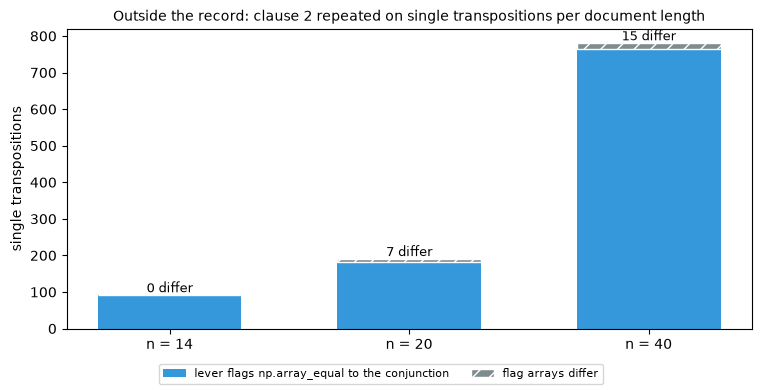

In [34]:
fig, ax = plt.subplots(figsize=(7.5, 3.8), constrained_layout=True)
x = np.arange(len(boundary_rows))
equal_counts = np.array([row["equal"] for row in boundary_rows])
differing_counts = np.array([row["transpositions"] - row["equal"] for row in boundary_rows])
ax.bar(x, equal_counts, 0.6, color=ARM_STYLE["lever"][1], label="lever flags np.array_equal to the conjunction")
ax.bar(x, differing_counts, 0.6, bottom=equal_counts, color=COL_REFERENCE, hatch="//", edgecolor="white", label="flag arrays differ")
for position, row in enumerate(boundary_rows):
    ax.text(position, row["transpositions"], f"{row['transpositions'] - row['equal']} differ", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, [f"n = {row['n']}" for row in boundary_rows])
ax.set_ylabel("single transpositions")
ax.set_title("Outside the record: clause 2 repeated on single transpositions per document length", fontsize=10)
fig.legend(fontsize=8, loc="outside lower center", ncol=2)
plt.show()

## Outside the record - each document encoded in its own call

An executor pass, with no registered bar and no part in the verdict. Every registered verbatim set builds document `B`
from rows of the encoding of `A` (`A[keep]`, `A[perm]`), so a statement and its copy have bitwise equal embeddings. The
shipped encoder batches statements by token length, so the same text encoded inside another document can return a
different row. This pass encodes `B` in its own call for the 280 deletion cases and for one permutation per base and
swap level of the reorder pool, and compares every flag array with the row-copy reading of the same case.

In [35]:
own_rows = []
for entry in tqdm(DEL, desc="deletion cases, B encoded in its own call", mininterval=15.0, file=sys.stdout):
    keep = entry["case"]["keep"]
    texts_b = [entry["S"][j] for j in keep]
    B_own = ENC.encode(texts_b)
    flags, counts = score_pair(entry["S"], entry["A"], texts_b, B_own, np.zeros(len(entry["S"]), dtype=bool), entry["kept"])
    own_rows.append({"rows_equal": bool(np.array_equal(B_own, entry["B"])), "max_abs_row_diff": float(np.abs(B_own - entry["B"]).max()),
                     "recovered": survivors_recovered(*flags["pairs"], keep),
                     **{f"same_{arm}": bool(np.array_equal(flags[arm], entry["flags"][arm])) for arm in FLAG_ARMS}, **counts})

deletion cases, B encoded in its own call:   0%|          | 0/280 [00:00<?, ?it/s]

deletion cases, B encoded in its own call:  89%|████████▉ | 250/280 [00:15<00:01, 16.64it/s]

deletion cases, B encoded in its own call: 100%|██████████| 280/280 [00:16<00:00, 17.12it/s]

In [36]:
OWN_PERM_SAMPLE, seen = [], set()        # the first permutation of each base and swap level k
for pair in POOL_PAIRS:
    if (pair["base"], pair["k"]) not in seen:
        seen.add((pair["base"], pair["k"]))
        OWN_PERM_SAMPLE.append(pair)

own_perm_rows = []
for pair in tqdm(OWN_PERM_SAMPLE, desc="permutations, B encoded in its own call", mininterval=15.0, file=sys.stdout):
    S, A = STATEMENTS[pair["base"]]["statements"], EMB[pair["base"]]
    texts_b = [S[j] for j in pair["perm"]]
    B_own = ENC.encode(texts_b)
    flags = arm_flags(_build_structural_details(S, A, texts_b, B_own), A, B_own)
    own_perm_rows.append({"rows_equal": bool(np.array_equal(B_own, A[pair["perm"]])),
                          "max_abs_row_diff": float(np.abs(B_own - A[pair["perm"]]).max()),
                          "lever_equals_conjunction": bool(np.array_equal(flags["lever"], flags["conjunction"])),
                          **{f"same_{arm}": bool(np.array_equal(flags[arm], pair["flags"][arm])) for arm in FLAG_ARMS}})

permutations, B encoded in its own call:   0%|          | 0/120 [00:00<?, ?it/s]

permutations, B encoded in its own call: 100%|██████████| 120/120 [00:07<00:00, 15.57it/s]

In [37]:
OWN_SUMMARY = deletion_summary(own_rows)
OWN_ROWS_EQUAL, OWN_MAX_DIFF = total(own_rows, "rows_equal"), max(row["max_abs_row_diff"] for row in own_rows)
OWN_RECOVERED = total(own_rows, "recovered")
OWN_SAME = {arm: total(own_rows, f"same_{arm}") for arm in FLAG_ARMS}
OWN_PERM_ROWS_EQUAL, OWN_PERM_MAX_DIFF = total(own_perm_rows, "rows_equal"), max(row["max_abs_row_diff"] for row in own_perm_rows)
OWN_PERM_EQUAL = total(own_perm_rows, "lever_equals_conjunction")
OWN_PERM_SAME = {arm: total(own_perm_rows, f"same_{arm}") for arm in FLAG_ARMS}

console.print(Group(
    make_table(f"Outside the record - the {len(own_rows)} deletion cases with B encoded in its own call (ground truth: 0 moved)",
               ["arm", "flagged kept statements", "flagged removed statements", "cases with >= 1 flag", "cases with >= 1 flag, row copies",
                "flag array equal to the row-copy reading"],
               [[ARM_LABEL[arm], f"{OWN_SUMMARY[arm]['flagged_kept']}/{DEL_KEPT_TOTAL}", f"{OWN_SUMMARY[arm]['flagged_removed']}/{DEL_REMOVED_TOTAL}",
                 f"{OWN_SUMMARY[arm]['cases_with_flag']}/{len(own_rows)}", f"{DEL_SUMMARY[arm]['cases_with_flag']}/{len(del_rows)}",
                 f"{OWN_SAME[arm]}/{len(own_rows)}"] for arm in FLAG_ARMS]),
    make_table(f"Outside the record - {len(own_perm_rows)} verbatim permutations (one per base and swap level) with B encoded in its own call",
               ["arm", "flag array equal to the row-copy reading"], [[ARM_LABEL[arm], f"{OWN_PERM_SAME[arm]}/{len(own_perm_rows)}"] for arm in FLAG_ARMS]),
    f"[bold]deletion cases[/bold]: every row of B bitwise equal to its row copy in {OWN_ROWS_EQUAL}/{len(own_rows)} cases; largest absolute difference"
    f" of one embedding entry {OWN_MAX_DIFF:.3e}; the matching pairs every survivor with its own copy in {OWN_RECOVERED}/{len(own_rows)} cases\n"
    f"[bold]permutations[/bold]: rows bitwise equal in {OWN_PERM_ROWS_EQUAL}/{len(own_perm_rows)} pairs; largest absolute difference {OWN_PERM_MAX_DIFF:.3e};"
    f" lever flags np.array_equal to the conjunction flags on {OWN_PERM_EQUAL}/{len(own_perm_rows)}\n"
    "[dim]no bar is registered for this pass; 'row copies' = the registered construction, B taken from the rows of the encoding of A[/dim]"))

        Outside the record - the 280 deletion cases with B encoded in its own call (ground truth: 0 moved)         
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃                  ┃                  ┃                  ┃                  ┃                  ┃ flag array equal ┃
┃                  ┃     flagged kept ┃  flagged removed ┃  cases with >= 1 ┃  cases with >= 1 ┃  to the row-copy ┃
┃ arm              ┃       statements ┃       statements ┃             flag ┃ flag, row copies ┃          reading ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ shipped (norm    │        1149/2772 │          526/700 │          274/280 │          274/280 │          280/280 │
│ only)            │                  │                  │                  │                  │                  │
│ conjunction      │         678/2772 │          472/700 │          246/280 │          246/280 │          280/280 │
│ (E12-H61         │                  │                  │                  │                  │                  │
│ baseline)        │                  │                  │                  │                  │                  │
│ conjunction AND  │         678/2772 │            0/700 │          202/280 │          202/280 │          280/280 │
│ matched          │                  │                  │                  │                  │                  │
│ lever (matched   │           0/2772 │            0/700 │            0/280 │            0/280 │          280/280 │
│ pairs)           │                  │                  │                  │                  │                  │
│ lever, no        │           0/2772 │            0/700 │            0/280 │            0/280 │          280/280 │
│ tie-break        │                  │                  │                  │                  │                  │
└──────────────────┴──────────────────┴──────────────────┴──────────────────┴──────────────────┴──────────────────┘
Outside the record - 120 verbatim permutations (one per base and swap level) 
                       with B encoded in its own call                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm                            ┃ flag array equal to the row-copy reading ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ shipped (norm only)            │                                  120/120 │
│ conjunction (E12-H61 baseline) │                                  120/120 │
│ conjunction AND matched        │                                  120/120 │
│ lever (matched pairs)          │                                  120/120 │
│ lever, no tie-break            │                                  120/120 │
└────────────────────────────────┴──────────────────────────────────────────┘
deletion cases: every row of B bitwise equal to its row copy in 259/280 cases; largest absolute difference of one 
embedding entry 6.864e-03; the matching pairs every survivor with its own copy in 280/280 cases
permutations: rows bitwise equal in 120/120 pairs; largest absolute difference 0.000e+00; lever flags 
np.array_equal to the conjunction flags on 120/120
no bar is registered for this pass; 'row copies' = the registered construction, B taken from the rows of the 
encoding of A

## Guardrails

The standing guardrails, measured. `V` is the count of (gold, adversarial) pairs ranked in the wrong order by shipped
`smd` on the ibm panel, out of 24, with the panel built as in E13-H70 (title line dropped, shipped segmenter, shipped
INT8 encoder). The metric property is read as the triangle inequality of shipped `smd` over every ordered triple of the
11 panel documents, with no tolerance: a triple violates it when `d(a, b) > d(a, c) + d(c, b)` in floats, and the
smallest margin `d(a, c) + d(c, b) - d(a, b)` is printed. The source tree is hashed again and compared with the opening
digest, `git status` is read for `src/` and `tests/`, and the shipped details of `(gold, gold-2)` are rebuilt and
compared byte for byte.

In [38]:
def load_body(path: Path) -> str:
    """Body text of a summary with the markdown title line removed (the E12-H66 panel loader)."""
    return "\n".join(line for line in path.read_text().splitlines() if not line.startswith("# ")).strip()


def state(ok: bool) -> str:
    """Rich-coloured guardrail state."""
    return "[dark_sea_green]hold[/dark_sea_green]" if ok else "[indian_red]BREACH[/indian_red]"


panel_labels = [label for _, label, _ in PANEL_DOCS]
panel_emb = {label: ENC.encode(dd.segmenter.split(load_body(SUMMARY_DIR / fname))) for fname, label, _ in PANEL_DOCS}
panel_pair = {(a, b): smd(panel_emb[a], panel_emb[b]) for a in panel_labels for b in panel_labels if a != b}
gold_labels = [label for _, label, tier in PANEL_DOCS if tier == "gold" and label != PANEL_REFERENCE]
adv_labels = [label for _, label, tier in PANEL_DOCS if tier != "gold"]
V = int(sum(panel_pair[(g, PANEL_REFERENCE)] >= panel_pair[(a, PANEL_REFERENCE)] for g in gold_labels for a in adv_labels))
V_TOTAL = len(gold_labels) * len(adv_labels)
closeness_of = {label: max(0.0, 1.0 - panel_pair[(label, PANEL_REFERENCE)] / SMD_MAX) for label in panel_labels if label != PANEL_REFERENCE}
PANEL_MARGIN_PTS = (min(closeness_of[g] for g in gold_labels) - max(closeness_of[a] for a in adv_labels)) * 100

tri_margins = np.array([panel_pair[(a, c)] + panel_pair[(c, b)] - panel_pair[(a, b)] for a, b, c in itertools.permutations(panel_labels, 3)])
TRI_CHECKED = len(tri_margins)
TRI_VIOLATIONS = int((tri_margins < 0).sum())                      # d(a, b) > d(a, c) + d(c, b), no tolerance
TRI_MIN_MARGIN = float(tri_margins.min())
METRIC_OK = bool(TRI_VIOLATIONS == 0)

digest_after = {folder: tree_digest(folder) for folder in GUARD_FOLDERS}
SRC_UNTOUCHED = bool(digest_after == digest_before)
git_status = subprocess.run(["git", "status", "--porcelain", "src/", "tests/"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
DEFAULT_PATH_EQUAL = bool(detail_bytes(*GUARD_PAIR) == guard_before)
GUARDRAILS_HELD = bool(V == V_GUARDRAIL and METRIC_OK and SRC_UNTOUCHED and not git_status and DEFAULT_PATH_EQUAL)

t = Table(title="Guardrails", header_style="bold medium_purple")
for column in ("guardrail", "reading", "state"):
    t.add_column(column)
t.add_row("V - content ordinality (ibm panel)", f"{V}/{V_TOTAL} violations, boundary margin {PANEL_MARGIN_PTS:+.2f} pts"
          f" (primer naive row: V {PANEL_PRIMER_ROW['V']}/24, margin {PANEL_PRIMER_ROW['margin_pts']:+.2f})", state(V == V_GUARDRAIL))
t.add_row("metric property - smd triangle inequality", f"{TRI_VIOLATIONS} violations of {TRI_CHECKED} ordered triples of the {len(panel_labels)} panel documents,"
          f" no tolerance; smallest margin {TRI_MIN_MARGIN:.6f}", state(METRIC_OK))
t.add_row("src/ and tests/ sha256 unchanged", ", ".join(f"{folder} {digest_after[folder][:16]}" for folder in GUARD_FOLDERS), state(SRC_UNTOUCHED))
t.add_row("git status src/ tests/", git_status or "(clean)", state(not git_status))
t.add_row(f"shipped details of {GUARD_PAIR} rebuilt", f"{len(guard_before)} bytes, byte-identical {DEFAULT_PATH_EQUAL}", state(DEFAULT_PATH_EQUAL))
console.print(Group(t,
    "[dim]rows that can fail: V, the triangle inequality, the sha256 comparison and git status. The detail row compares two calls of the unmodified"
    " shipped builder inside this kernel, so it detects a change made during this run only. Every arm of this notebook is computed outside the"
    " shipped builder: no distance, plan or detail field is rewritten.[/dim]"))

                                                    Guardrails                                                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ guardrail                                     ┃ reading                                                 ┃ state ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ V - content ordinality (ibm panel)            │ 0/24 violations, boundary margin +4.71 pts (primer      │ hold  │
│                                               │ naive row: V 0/24, margin +4.71)                        │       │
│ metric property - smd triangle inequality     │ 0 violations of 990 ordered triples of the 11 panel     │ hold  │
│                                               │ documents, no tolerance; smallest margin 0.177149       │       │
│ src/ and tests/ sha256 unchanged              │ src be7e159f81c53284, tests 00ea6c7799307adb            │ hold  │
│ git status src/ tests/                        │ (clean)                                                 │ hold  │
│ shipped details of ('gold', 'gold-2') rebuilt │ 8503 bytes, byte-identical True                         │ hold  │
└───────────────────────────────────────────────┴─────────────────────────────────────────────────────────┴───────┘
rows that can fail: V, the triangle inequality, the sha256 comparison and git status. The detail row compares two 
calls of the unmodified shipped builder inside this kernel, so it detects a change made during this run only. Every
arm of this notebook is computed outside the shipped builder: no distance, plan or detail field is rewritten.

## Acceptance bar

The registered bar, applied literally: all four clauses at `c = 0.325` and `ε = 1e-6`. The verdict follows the campaign
vocabulary - a failed harness check reads `Blocked`, a fired kill-gate `Killed-at-gate`, a lever that meets its bar
`Promoted`, a lever that misses it `Refuted`. The prediction rows are not clauses of the bar; each is read against the
number the record states.

In [39]:
BAR_MET = bool(CLAUSE1_MET and CLAUSE2_MET and CLAUSE3_MET and CLAUSE4_MET)
PREDICTION = {
    "conjunction flags >= 1 statement in at least 10% of the deletion cases": bool(CONJ_CASE_SHARE >= PRED_CONJ_CASE_SHARE),
    "lever flags 0 statements in 280/280": bool(LEVER_CLEAN_CASES == N_DELETION_CASES == len(del_rows)),
    "flags equal on 1680/1680 verbatim permutations": bool(POOL_EQUAL["lever"] == N_POOL_PERMUTATIONS == len(pool_eq_rows)),
    "lever keeps 99% to 100% of the true relocations the conjunction flags": bool(PRED_RETENTION_MIN <= RETENTION <= PRED_RETENTION_MAX),
    "fixtures read insertion 0/6, swap 2/2, reversal 12/12, shrinkage 0/12": CLAUSE4_MET,
}
PREDICTION_HELD = bool(all(PREDICTION.values()))
if not SANITY_PASSED:
    VERDICT = "Blocked"
elif not KILL_GATE_PASSED:
    VERDICT = "Killed-at-gate"
elif BAR_MET and GUARDRAILS_HELD:
    VERDICT = "Promoted"
else:
    VERDICT = "Refuted"

t = Table(title="Registered acceptance bar - E15-H80", header_style="bold medium_purple")
for column in ("clause", "requirement", "reading", "met"):
    t.add_column(column)
t.add_row("harness check", f"E12-H61 pool reading {H61_POOL_FLAGGED} flagged, {H61_POOL_LOST} lost over {N_POOL_PERMUTATIONS}; deletion set 280/280",
          f"{POOL_SHIPPED_TRUE} flagged, {POOL_LOST} lost over {n_pairs}; {DEL_WITHIN[C_H70]}/{len(CASES)}", "yes" if SANITY_PASSED else "no")
t.add_row("kill-gate", "the conjunction flags >= 1 statement in >= 1 deletion case",
          f"{KILL_CASES_WITH_FLAG}/{kill_df.height} cases, {KILL_FLAGGED_KEPT} kept + {KILL_FLAGGED_REMOVED} removed statements", "yes" if KILL_GATE_PASSED else "no")
t.add_row("1 - deletions", f"lever flags 0 statements in {N_DELETION_CASES}/{N_DELETION_CASES}", f"{LEVER_CLEAN_CASES}/{len(del_rows)}", "yes" if CLAUSE1_MET else "no")
t.add_row("2 - verbatim pool", f"flags np.array_equal on {N_POOL_PERMUTATIONS}/{N_POOL_PERMUTATIONS}", f"{POOL_EQUAL['lever']}/{len(pool_eq_rows)}", "yes" if CLAUSE2_MET else "no")
t.add_row("3 - reworded reorders", f"retention >= {RETENTION_BAR}, pooled over the 10 bases",
          f"{RET_NUM['lever']}/{RET_DEN} = {RETENTION:.6f} over {len(USABLE_BASES)} bases", "yes" if CLAUSE3_MET else "no")
t.add_row("4 - fixtures", "insertion 0 of 6, swap 2 of 2, reversal 12 of 12, text shrinkage 0 of 12",
          f"{lever_fix['insertion'][0]} of 6, {lever_fix['swap'][0]} of 2, {lever_fix['reversal_orth'][0]} and {lever_fix['reversal_text'][0]} of 12,"
          f" {lever_fix['shrinkage'][0]} of 12", "yes" if CLAUSE4_MET else "no")
for name, held in PREDICTION.items():
    t.add_row("prediction", name, "", "yes" if held else "no")
verdict_colour = "dark_sea_green" if VERDICT == "Promoted" else "indian_red"
console.print(Group(t, Panel(
    f"[bold {verdict_colour}]bar met: {BAR_MET} | guardrails held: {GUARDRAILS_HELD} | verdict: {VERDICT}[/bold {verdict_colour}]\n"
    f"scope of the registered sets: documents of {N_MIN} to {N_MAX} statements with {REPEATED_IN_BASES} repeated statements\n"
    f"outside the bar: reworded survivors - lever flags in {RWDEL_SUMMARY['lever']['cases_with_flag']}/{len(rwdel_rows)} cases;"
    f" long document - lever flags in {LONG[DOC_KEPT]['lever']['cases_with_flag']}/{LONG_CASES[DOC_KEPT]} cases with repeated statements kept and"
    f" {LONG[DOC_REMOVED]['lever']['cases_with_flag']}/{LONG_CASES[DOC_REMOVED]} with them removed;"
    f" single transpositions - flags equal on " + ", ".join(f"{row['equal']}/{row['transpositions']} at n = {row['n']}" for row in boundary_rows)
    + f"; cutoff pass - retention below {RETENTION_BAR} at c in {SWEEP_BELOW_BAR or 'none'}, largest true-pair cost {float(TRUE_COSTS.max()):.6f}"
    + f"; B encoded in its own call - lever flags in {OWN_SUMMARY['lever']['cases_with_flag']}/{len(own_rows)} deletion cases, conjunction in"
      f" {OWN_SUMMARY['conjunction']['cases_with_flag']}/{len(own_rows)}",
    border_style=verdict_colour, expand=False)))

                                        Registered acceptance bar - E15-H80                                        
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┓
┃ clause                ┃ requirement                             ┃ reading                                 ┃ met ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━┩
│ harness check         │ E12-H61 pool reading 13675 flagged, 0   │ 13675 flagged, 0 lost over 1680;        │ yes │
│                       │ lost over 1680; deletion set 280/280    │ 280/280                                 │     │
│ kill-gate             │ the conjunction flags >= 1 statement in │ 246/280 cases, 678 kept + 472 removed   │ yes │
│                       │ >= 1 deletion case                      │ statements                              │     │
│ 1 - deletions         │ lever flags 0 statements in 280/280     │ 280/280                                 │ yes │
│ 2 - verbatim pool     │ flags np.array_equal on 1680/1680       │ 1680/1680                               │ yes │
│ 3 - reworded reorders │ retention >= 0.98, pooled over the 10   │ 13675/13675 = 1.000000 over 10 bases    │ yes │
│                       │ bases                                   │                                         │     │
│ 4 - fixtures          │ insertion 0 of 6, swap 2 of 2, reversal │ 0 of 6, 2 of 2, 12 and 12 of 12, 0 of   │ yes │
│                       │ 12 of 12, text shrinkage 0 of 12        │ 12                                      │     │
│ prediction            │ conjunction flags >= 1 statement in at  │                                         │ yes │
│                       │ least 10% of the deletion cases         │                                         │     │
│ prediction            │ lever flags 0 statements in 280/280     │                                         │ yes │
│ prediction            │ flags equal on 1680/1680 verbatim       │                                         │ yes │
│                       │ permutations                            │                                         │     │
│ prediction            │ lever keeps 99% to 100% of the true     │                                         │ yes │
│                       │ relocations the conjunction flags       │                                         │     │
│ prediction            │ fixtures read insertion 0/6, swap 2/2,  │                                         │ yes │
│                       │ reversal 12/12, shrinkage 0/12          │                                         │     │
└───────────────────────┴─────────────────────────────────────────┴─────────────────────────────────────────┴─────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ bar met: True | guardrails held: True | verdict: Promoted                                                       │
│ scope of the registered sets: documents of 11 to 14 statements with 0 repeated statements                       │
│ outside the bar: reworded survivors - lever flags in 0/280 cases; long document - lever flags in 4/120 cases    │
│ with repeated statements kept and 0/120 with them removed; single transpositions - flags equal on 91/91 at n =  │
│ 14, 183/190 at n = 20, 765/780 at n = 40; cutoff pass - retention below 0.98 at c in [0.25, 0.28, 0.3], largest │
│ true-pair cost 0.322901; B encoded in its own call - lever flags in 0/280 deletion cases, conjunction in        │
│ 246/280                                                                                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Metrics

Every measured number, the bar readings and the guardrail readings, written to
`reports/E15-H80-moved-on-matched-pairs-metrics.json`. The printed block is the file content, so each number the stage A
result quotes appears in this output.

In [40]:
def arm_block(summary: dict, cases: int, kept: int, removed: int) -> dict:
    """Per-arm deletion counts with their denominators."""
    return {arm: values | {"cases": cases, "kept_statements": kept, "removed_statements": removed} for arm, values in summary.items()}


metrics = {
    "id": "E15-H80",
    "slug": "moved-on-matched-pairs",
    "environment": {"python": sys.version.split()[0], "docdistance": docdistance.__version__, "pot": ot.__version__,
                    "numpy": np.__version__, "scipy": scipy.__version__, "encoder": "mmBERT OpenVINO INT8 (CPU)"},
    "seed": SEED,
    "lever": {"c": C_MATCH, "eps": EPS_TIE, "moved_tolerance": MOVED_TOLERANCE, "no_counterpart_cost": NO_COUNTERPART_COST,
              "definition": "not no_counterpart AND matched AND matched_displacement != 0 AND abs(matched_displacement / n_matched) > moved_tolerance",
              "matching": "linear_sum_assignment on min(cost, c) + eps * abs(i / n - j / m); a pair with cost >= c is unmatched"},
    "arms": dict(ARM_LABEL),
    "scope": {"n_statements_min": N_MIN, "n_statements_max": N_MAX, "repeated_statements_in_base_documents": REPEATED_IN_BASES,
              "repeated_statements_in_paraphrases": REPEATED_IN_PARAPHRASES},
    "sanity_check": {
        "passed": SANITY_PASSED,
        "pool": {"passed": HARNESS_POOL_PASSED, "n_permutations": n_pairs, "relocated_statements": POOL_RELOCATED,
                 "true_positives_shipped": POOL_SHIPPED_TRUE, "true_positives_conjunction": POOL_CONJ_TRUE, "true_positives_lost": POOL_LOST,
                 "false_fires_shipped": POOL_SHIPPED_FALSE, "false_fires_conjunction": POOL_CONJ_FALSE,
                 "record": {"flagged": H61_POOL_FLAGGED, "lost": H61_POOL_LOST, "n_permutations": N_POOL_PERMUTATIONS}},
        "arm_consistency": {"passed": HARNESS_ARM_CONSISTENT, "record_conjunction_equal_compiled_pool": RECORD_CONJ_EQUAL_POOL,
                            "record_conjunction_equal_compiled_fixtures": RECORD_CONJ_EQUAL_FIXTURES,
                            "saved_h61_fixture_counts_reproduced": FIXTURE_COUNTS_REPRODUCED, "fixtures": fixture_conj_rows},
        "deletion_set": {"passed": HARNESS_DELETION_PASSED, "cases": len(CASES), "ceiling": GAP_BAR,
                         "within_ceiling_c060": DEL_WITHIN[C_H70], "within_ceiling_c0325": DEL_WITHIN[C_MATCH],
                         "shipped_above_ceiling": SHIPPED_ABOVE_BAR, "saved_h70_values_equal": f"{H70_SAVED_EQUAL}/{len(h70_compare)}",
                         "readings": {name: {"here": here, "saved": saved} for name, here, saved in h70_compare},
                         "functions_copied_unchanged": COPIED, "h61_substitutions_copied_unchanged": COPIED_H61},
    },
    "kill_gate": {"ran": True, "passed": KILL_GATE_PASSED, "cases": kill_df.height, "cases_with_conjunction_flag": KILL_CASES_WITH_FLAG,
                  "share": sig(KILL_CASES_WITH_FLAG / kill_df.height), "flagged_kept": KILL_FLAGGED_KEPT, "flagged_removed": KILL_FLAGGED_REMOVED,
                  "per_k": {str(row["k"]): {key: row[key] for key in ("cases", "case_with_flag", "flagged_kept", "flagged_removed", "removed_no_counterpart")}
                            for row in per_k.iter_rows(named=True)}},
    "clause_1_deletions": {
        "met": CLAUSE1_MET, "cases": len(del_rows), "lever_cases_with_0_flags": LEVER_CLEAN_CASES, "survivors_recovered": DEL_RECOVERED,
        "no_counterpart_rule_acted": DEL_RULE_ACTED, "conjunction_case_share": sig(CONJ_CASE_SHARE),
        "per_arm": arm_block(DEL_SUMMARY, len(del_rows), DEL_KEPT_TOTAL, DEL_REMOVED_TOTAL),
        "cases_with_flag_per_k": {str(row["k"]): {arm: row[f"any_{arm}"] for arm in FLAG_ARMS} for row in any_by_k.iter_rows(named=True)},
    },
    "clause_2_verbatim_pool": {
        "met": CLAUSE2_MET, "permutations": len(pool_eq_rows), "fully_matched": POOL_FULLY_MATCHED, "matching_equals_exact_plan": POOL_SAME_MAP,
        "relocated_statements": POOL_TRUE, "in_place_statements": POOL_IN_PLACE, "no_counterpart_rule_acted": POOL_RULE_ACTED,
        "per_arm": {arm: {"pool_equality_count": POOL_EQUAL[arm], "true_relocations_flagged": total(pool_eq_rows, f"tp_{arm}"),
                          "false_fires": total(pool_eq_rows, f"fp_kept_{arm}")} for arm in FLAG_ARMS},
    },
    "clause_3_reworded_reorders": {
        "met": CLAUSE3_MET, "bar": RETENTION_BAR, "pairs": len(rw_rows), "bases_used": USABLE_BASES, "bases_left_out": LEFT_OUT_BASES,
        "retention": sig(RETENTION), "retention_numerator": RET_NUM["lever"], "retention_denominator": RET_DEN,
        "retention_min_per_base": sig(min(RET_BASE.values())), "retention_per_base": {base: sig(value) for base, value in RET_BASE.items()},
        "relocated_statements": RW_TRUE, "statements_that_did_not_relocate": RW_IN_PLACE,
        "fully_matched": RW_FULLY_MATCHED, "matching_equals_exact_plan": RW_SAME_MAP, "no_counterpart_rule_acted": RW_RULE_ACTED,
        "per_arm": {arm: {"retention_numerator": RET_NUM[arm], "retention_denominator": RET_DEN, "retention": sig(RET_NUM[arm] / RET_DEN),
                          "true_relocations_flagged": RW_TP[arm], "false_fires_on_not_relocated": RW_FALSE[arm],
                          "pairs_with_flags_equal_to_conjunction": RW_EQUAL[arm]} for arm in FLAG_ARMS},
        "alignment_check": {"statements": BT_STATEMENTS, "true_pair_cost_max": sig(BT_TRUE_COST_MAX), "true_pairs_at_or_above_c": BT_TRUE_AT_OR_ABOVE_C,
                            "per_base": {row["base"]: {key: (sig(value) if isinstance(value, float) else value) for key, value in row.items() if key != "base"}
                                         for row in bt_rows}},
    },
    "clause_4_fixtures": {"met": CLAUSE4_MET, "worked_example_statements_without_match": WORKED_UNMATCHED, "bar": {key: list(value) for key, value in FIXTURE_BAR.items()}, "parts": CLAUSE4,
                          "per_arm": {arm: {key: list(value) for key, value in FIX_READ[arm].items()} for arm in FLAG_ARMS}},
    "reported_without_bar": {
        "reordered_and_deleted_ladder": {
            "k": K_LADDER, "unique_permutations": len(UNIQUE_PERMS), "cases": ladder_df.height, "statements": LADDER_STATEMENTS,
            "removed_statements": LADDER_REMOVED, "no_counterpart_rule_acted": int(ladder_df["rule_acted"].sum()),
            "survivors_recovered": LADDER_RECOVERED, "matched_pairs_min": LADDER_MATCHED_MIN, "matched_pairs_max": LADDER_MATCHED_MAX,
            "per_arm": {arm: {key: (sig(value) if isinstance(value, float) else value) for key, value in values.items()} for arm, values in LADDER.items()},
            "per_rung": {str(r): {"cases": LADDER_RUNG_CASES[r]} | {arm: {key: (sig(LADDER_RUNG[arm][r][key]) if LADDER_RUNG[arm][r][key] is not None else None)
                                                                          for key in ("precision", "recall")} for arm in FLAG_ARMS} for r in range(1, N_RUNGS + 1)},
        },
        "tied_plan_rows": {
            "tie_atol": TIE_ATOL, "cases": tie_df.height, "cases_with_tied_removed_statement": TIE_CASES, "share": sig(TIE_SHARE),
            "cases_with_tied_removed_statement_exact_equality": TIE_CASES_EXACT, "tied_removed_statements": TIE_STATEMENTS,
            "tied_removed_statements_exact_equality": TIE_STATEMENTS_EXACT, "removed_statements": int(tie_df["n_removed"].sum()),
            "largest_tie": int(tie_df["largest_tie"].max()), "most_tie_resolutions": int(tie_df["n_resolutions"].max()),
            "cases_where_tie_resolutions_change_the_flags": TIE_VARIES, "restated_flag_lines_equal_shipped": TIE_REPLICA_OK, "example": tie_example,
        },
    },
    "outside_the_record": {
        "cutoff_on_reworded_reorders": {"in_bar": False, "pairs": len(RW_PAIRS), "true_pairs": len(TRUE_COSTS),
                                        "true_pair_cost_max": sig(TRUE_COSTS.max()), "margin_below_registered_cutoff": sig(TRUE_COST_MARGIN),
                                        "cutoffs_with_retention_below_bar": SWEEP_BELOW_BAR, "registered_row_equals_clause_3": SWEEP_REGISTERED_EQUAL,
                                        "per_cutoff": {str(row["c"]): {key: (sig(value) if isinstance(value, float) else value)
                                                                       for key, value in row.items() if key != "c"} for row in sweep_rows}},
        "reworded_survivors": {"in_bar": False, "cases": len(rwdel_rows), "true_pairs_only": RWDEL_TRUE_PAIRS_ONLY,
                               "survivors_matched": RWDEL_SURVIVORS_MATCHED,
                               "per_arm": arm_block(RWDEL_SUMMARY, len(rwdel_rows), RWDEL_KEPT, RWDEL_REMOVED)},
        "long_document": {"in_bar": False, "document": LONG_DOC, "statements": len(long_texts), "repeated_statements": len(REPEATED_POSITIONS),
                          "repeated_texts": REPEATED_TEXTS, "statements_after_removal": len(unique_positions), "k": LONG_K,
                          "draws_per_length": LONG_REPS, "seed": f"[{LONG_SEED}, prefix length, draw]",
                          "docs": {doc_arm: {"cases": LONG_CASES[doc_arm], "survivors_recovered": LONG_RECOVERED[doc_arm],
                                             "per_arm": LONG[doc_arm],
                                             "lever_flagged_cases": [row for row in LONG_LEVER_CASES if row["doc_arm"] == doc_arm],
                                             "cases_with_flag_per_length": {str(n): values for n, values in LONG_PER_N[doc_arm].items()},
                                             "survivors_recovered_per_length": {str(n): values for n, values in LONG_RECOVERED_PER_N[doc_arm].items()}}
                                   for doc_arm in LONG_DOCS}},
        "tolerance_boundary": {"in_bar": False, "scan_max_length": BOUNDARY_SCAN_MAX, "lengths_with_differing_cells": {str(n): row for n, row in SCAN.items()},
                               "single_transpositions": [{**row, "differing_rank_steps": {str(k): v for k, v in row["differing_rank_steps"].items()}}
                                                         for row in boundary_rows]},
    },
    "prediction": {"parts": PREDICTION, "held": PREDICTION_HELD},
    "outside_the_record_own_encoding": {
        "in_bar": False,
        "deletion_cases": {"cases": len(own_rows), "rows_bitwise_equal": OWN_ROWS_EQUAL, "max_abs_row_diff": sig(OWN_MAX_DIFF),
                           "survivors_recovered": OWN_RECOVERED, "flag_array_equal_to_row_copy_reading": OWN_SAME,
                           "per_arm": arm_block(OWN_SUMMARY, len(own_rows), DEL_KEPT_TOTAL, DEL_REMOVED_TOTAL)},
        "permutations": {"pairs": len(own_perm_rows), "rows_bitwise_equal": OWN_PERM_ROWS_EQUAL, "max_abs_row_diff": sig(OWN_PERM_MAX_DIFF),
                         "lever_equals_conjunction": OWN_PERM_EQUAL, "flag_array_equal_to_row_copy_reading": OWN_PERM_SAME},
    },
    "acceptance": {
        "bar": "PASS iff, at c = 0.325 and eps = 1e-6: (1) the lever flags 0 statements in 280/280 order-preserving deletion cases; (2) lever flags"
               " np.array_equal to the conjunction flags on every one of the 1680 verbatim permutations; (3) the lever flags >= 98% of the truly relocated"
               " statements the conjunction flags on reworded reorders, pooled over the 10 bases; (4) fixtures insertion 0 of 6, swap 2 of 2,"
               " reversal 12 of 12, text shrinkage 0 of 12",
        "clause_1_met": CLAUSE1_MET, "clause_2_met": CLAUSE2_MET, "clause_3_met": CLAUSE3_MET, "clause_4_met": CLAUSE4_MET,
        "met": BAR_MET, "verdict": VERDICT,
    },
    "guardrails": {
        "V": f"{V}/{V_TOTAL}", "panel_margin_pts": round(PANEL_MARGIN_PTS, 4), "triangle_checks": TRI_CHECKED, "triangle_violations": TRI_VIOLATIONS,
        "triangle_tolerance": 0.0, "triangle_min_margin": sig(TRI_MIN_MARGIN),
        "metric_property_held": METRIC_OK, "src_untouched": SRC_UNTOUCHED, "sha256": {folder: digest_after[folder][:16] for folder in GUARD_FOLDERS},
        "git_status_src_tests": git_status or "clean", "shipped_details_byte_identical": DEFAULT_PATH_EQUAL, "held": GUARDRAILS_HELD,
        "rows_that_can_fail": "V, triangle inequality, sha256 of src and tests, git status",
    },
}
METRICS_OUT.parent.mkdir(parents=True, exist_ok=True)
METRICS_OUT.write_text(json.dumps(metrics, indent=2) + "\n")
print(f"wrote {METRICS_OUT.relative_to(ROOT)} ({METRICS_OUT.stat().st_size} bytes)")
print(json.dumps(metrics, indent=1))

wrote reports/E15-H80-moved-on-matched-pairs-metrics.json (41265 bytes)
{
 "id": "E15-H80",
 "slug": "moved-on-matched-pairs",
 "environment": {
  "python": "3.14.8",
  "docdistance": "1.1.5",
  "pot": "0.9.6.post1",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "encoder": "mmBERT OpenVINO INT8 (CPU)"
 },
 "seed": 0,
 "lever": {
  "c": 0.325,
  "eps": 1e-06,
  "moved_tolerance": 0.05,
  "no_counterpart_cost": 0.6,
  "definition": "not no_counterpart AND matched AND matched_displacement != 0 AND abs(matched_displacement / n_matched) > moved_tolerance",
  "matching": "linear_sum_assignment on min(cost, c) + eps * abs(i / n - j / m); a pair with cost >= c is unmatched"
 },
 "arms": {
  "shipped": "shipped (norm only)",
  "conjunction": "conjunction (E12-H61 baseline)",
  "conjunction_and_matched": "conjunction AND matched",
  "lever": "lever (matched pairs)",
  "lever_no_tiebreak": "lever, no tie-break"
 },
 "scope": {
  "n_statements_min": 11,
  "n_statements_max": 14,
  "repeated_statement

## Conclusions

**Verdict: Promoted, within the scope of the registered sets.** At `c = 0.325` and `ε = 1e-6` the lever meets all four
clauses of the registered bar, after the harness reproduced the E12-H61 pool reading and the kill-gate passed. The
registered sets hold documents of 11 to 14 statements with 0 repeated statements, and every true reworded pair of the
fixture costs less than the cutoff. Five passes outside the record measure what those sets cannot show. The lever keeps
0 false flags on reworded survivors (0 of 280 cases) and on a long document without repeated statements (0 of 120). It
flags statements in 4 of 120 cases on a document with repeated statements, differs from the conjunction on 7 of 190 and
15 of 780 single transpositions at 20 and 40 statements, and reads a retention below the 98% bar at cutoffs of `0.30`
and lower.

**Harness and gate**

- **Harness check passed** - 1680 permutations, 13675 truly relocated statements, 13675 flagged by the shipped flag, 0 lost under the conjunction. These are the numbers of the record and of the saved E12-H61 metrics. The conjunction arm of this notebook (record field `moved` AND `displacement != 0`) equals the compiled E12-H61 conjunction flag for flag on 1680 of 1680 permutations and on 6 of 6 fixtures
- **Deletion set reproduced** - 280 cases; 280 of 280 at or below `0.005` under the matched order gap at `c = 0.6`, and 280 of 280 at `c = 0.325`; the 5 compared values equal the saved E13-H70 metrics at 6 significant digits; the 5 copied functions occur verbatim in the E13-H70 notebook
- **Kill-gate passed** - the conjunction flags at least one statement in 246 of 280 order-preserving deletion cases (87.9%; the gate needs 1 case): 678 of 2772 kept statements and 472 of 700 removed statements. The count rises with the deletion depth: 43, 64, 69 and 70 of 70 cases at `k` = 1 to 4. DEF-TRANS-13 reproduces on real documents

**Clause 1 - deletions: met, 280 of 280**

- **Reading** - the lever flags 0 of 2772 kept and 0 of 700 removed statements. The shipped flag fires in 274 of 280 cases (1149 kept, 526 removed), the conjunction in 246 (678 kept, 472 removed), the conjunction restricted to matched statements in 202 (678 kept, 0 removed)
- **Mechanism** - the matching pairs every survivor with its own copy in 280 of 280 cases and leaves exactly the removed statements unmatched, so the ranks inside the two matched sub-sequences are equal. Restricting the conjunction to matched statements removes the 472 flags on removed statements and none of the 678 flags on kept statements: those 678 come from the rank shift that the target of a removed statement causes in the exact-plan alignment, which is why the lever takes its ranks from the matched pairs
- **Meaning** - on this set the clause holds by construction once the matching is exact: the survivors are byte-identical and no base document holds a repeated statement, so the zero-cost assignment is unique. The lever without the tie-break reads the same 0 of 280

**Clause 2 - verbatim pool: met, 1680 of 1680**

- **Reading** - per permutation, the lever's flag array is `np.array_equal` to the conjunction's on 1680 of 1680. All 1680 pairs are fully matched and on all 1680 the matching is the exact-plan alignment. Every arm flags 13675 of 13675 true relocations and 0 of 7157 in-place statements
- **Scope** - the pool holds documents of 11 to 14 statements, where one rank step is at least `1/14 = 0.0714` and above the tolerance `0.05`. The tolerance term decides no flag in this clause

**Clause 3 - reworded reorders: met, 13675 of 13675 = 1.000000 against a bar of 0.98**

- **Reading** - pooled over 10 of 10 bases, the lever flags every truly relocated statement that the conjunction flags. The smallest per-base retention is `1.0000`. No arm fires on any of the 7157 statements that did not relocate
- **Mechanism** - all 10 `~bt` documents pass the alignment check (same statement count, equal to the stored `.bt.json`, every statement and its reword mutual cheapest partners). All 124 true reworded pairs cost less than the cutoff (largest `0.322901`), so all 1680 pairs are fully matched, the matching is the exact-plan alignment on all 1680, and the lever's flag array equals the conjunction's on 1680 of 1680
- **Meaning** - the clause does not separate the lever from the baseline on this fixture. The lever can lose a flag that the conjunction keeps only when a reworded statement costs at or above the cutoff, and no such statement is in the fixture. The cutoff pass measures that case

**Clause 4 - fixtures: met**

- **Reading** - insertion 0 of 6, swap 2 of 2, reversal 12 of 12 on both reversal fixtures, text shrinkage 0 of 12
- **Against the conjunction** - on the text shrinkage the conjunction flags 2 of the 4 removed statements (the DEF-TRANS-13 reading) and the lever flags 0. On the worked example the conjunction flags statements 1, 2, 3 and 4 and the lever flags 2 and 3: statements 1 and 4 are the two replaced statements, they hold no match at `c = 0.325`, and the lever does not read a statement without a match as moved

**Reported without a bar**

- **Reordered-and-deleted ladder** - 11277 cases, 83778 truly relocated statements. Lever: precision `1.0000`, recall `1.0000`. Conjunction: precision `0.7624`, recall `0.8779` (5482 false fires on kept statements, 17444 on the 22554 removed statements, 10229 relocations missed). Shipped: `0.7258` and `0.9301`. Conjunction AND matched: `0.9306` and `0.8779`. At rung 1 the conjunction reads `0.4165` and `0.7587`. The lever's reading holds by construction on this set: the matching pairs every survivor with its own copy in 11277 of 11277 cases and each case holds 9 to 12 matched pairs, so the lever's rank shift is the ground-truth definition and one rank step exceeds the tolerance
- **False fires on reworded reorders** - 0 of 7157 for every arm
- **Lever with no tie-break** - equal to the lever on every registered set: 0 of 280 deletion cases flagged, 1680 of 1680 permutations equal, 13675 of 13675 kept, the same fixture readings. The registered sets hold no repeated statement, so they give the tie-break nothing to decide
- **Tied plan rows** - 259 of 280 deletion cases (`0.9250`) hold a removed statement whose two largest plan entries are within `1e-12`; 245 of 280 under exact float equality. 590 of the 700 removed statements are tied and the largest tie holds 13 entries. When each tied entry is taken as the aligned target in turn, the conjunction's flag array changes in 257 of 280 cases, the shipped flag array in 221, the lever's in 0. The exact-plan flags of a deletion case therefore depend on which of several equal plan entries the argmax returns

**Outside the record**

- **Cutoff on the reworded reorders** - the largest true-pair cost is `0.002099` below the registered cutoff. With 1 of the 124 true pairs at or above the cutoff (`c = 0.32`) the retention is `0.9894` and the lever fires on 112 statements that did not relocate. At `c = 0.30` (2 pairs) the retention is `0.9769`, below the bar, with 176 false fires; at `c = 0.25` (11 pairs) it is `0.8918` with 789. From `0.325` to `0.6` the reading is `1.0000` with 0 false fires. Mechanism, at `c = 0.32`: 102 of the 145 lost flags belong to a statement that holds no match, and 43 to a matched statement whose rank among the matched statements did not change; the 112 false fires are statements whose position did not change and whose rank among the matched statements did
- **Reworded survivors** - the lever flags 0 statements in 280 of 280 order-preserving deletion cases on back-translated survivors, and every survivor is matched with its own reword in 280 of 280. The conjunction fires in 250 of 280. This reading is not by construction: the true pairs cost up to `0.322901`
- **Long document, repeated statements removed** - the lever flags 0 of 120 cases at 14 to 53 statements, with and without the tie-break. The conjunction fires in 108 of 120
- **Long document, repeated statements kept** - `source` holds 9 statements with the text `-`. The lever fires in 4 of 120 cases (4 kept and 4 removed statements, all at prefix length 14) and in 31 of 120 without the tie-break. The matching pairs every survivor with its own copy in 110 of 120 cases with the tie-break and in 88 without. In each of the 4 cases a deleted `-` is matched in place of a surviving `-`. In 2 of them the positional term of that matching equals the positional term of the true matching, so the tie-break has a tie of its own; in the other 2 it is smaller (`0.547619` against `0.595238`, `0.595238` against `0.642857`), so the tie-break selects the wrong statement
- **Tolerance boundary** - at lengths 20, 40, 60, 80 and 100 the float forms `abs(j/n - i/n)` and `abs((j - i)/n)` give different threshold results for the rank step that equals 5% of the length. On single transpositions of `source`, the lever's flag array equals the conjunction's on 91 of 91 at 14 statements, 183 of 190 at 20 and 765 of 780 at 40. In the differing transpositions the conjunction flags statements that the lever does not (14 at 20 statements, 30 at 40) and the lever flags none that the conjunction does not: the lever reads a shift of exactly 5% as not above the tolerance at every position, and the shipped norm reads it above the tolerance at some positions through float rounding

- **Each document encoded in its own call** - with `B` encoded in its own call, every row of `B` is bitwise equal to its row copy in 259 of 280 deletion cases and the largest difference of one embedding entry is `6.864e-03`. Every arm's flag array equals its row-copy reading in 280 of 280 cases: the conjunction fires in 246 of 280 and the lever in 0 of 280, and the matching pairs every survivor with its own copy in 280 of 280. On the 120 sampled verbatim permutations the rows are bitwise equal in 120 of 120, so that part repeats the row-copy input and shows nothing new

**Guardrails hold, measured**

- `V = 0/24` on the ibm panel, boundary margin `+4.71` points, equal to the naive row of the campaign primer
- Triangle inequality of shipped `smd`, read with no tolerance: 0 violations of 990 ordered triples of the 11 panel documents; the smallest margin is `0.177149`
- `src/` and `tests/` digests are unchanged and `git status` is clean for both. The shipped details of `(gold, gold-2)` rebuild byte-identical; that row compares two calls inside one kernel
- The lever is an annotation computed outside the shipped builder: no distance, plan or detail field is rewritten. The no_counterpart rule switched off 0 lever flags on every registered set

**What this warrants and what it does not**

- **Warranted** - the registered bar is met at `c = 0.325` and `ε = 1e-6`. On documents of 11 to 14 statements without repeated statements the lever removes every false `moved` flag of an order-preserving deletion (conjunction 246 of 280 cases → lever 0 of 280), equals the conjunction on every fully matched verbatim and reworded reorder of the fixture, and keeps the four fixture readings
- **Not warranted** - flag-for-flag equality with the conjunction on every fully matched equal-length pair: 183 of 190 and 765 of 780 on single transpositions at 20 and 40 statements. A reading of 0 false flags on a document with repeated statements: 4 of 120 cases with the registered tie-break. A retention of at least 98% when reworded statements cost at or above the cutoff: `0.9769` with 2 of 124 pairs there
- **Deferred to the build** - which float form of the tolerance term the detail file carries on fully matched pairs; the reading on documents with repeated statements; a measurement of clause 3 on paraphrases outside this fixture, because the evidence line of the record cites these same 124 pairs for the cutoff
- **Not shown** - insertions and substitutions on real documents beyond the E12-H61 fixtures; pairs that hold statements without a counterpart on both sides; a second encoder; a paraphrase method other than the opus-mt back-translation
- **Executor readings of the record** - the cutoff of the deletion-set check, both reversal fixtures in clause 4, the alignment rule of the `~bt` documents and the tie tolerance `1e-12` are written in the configuration section. The tie-resolution reading enumerates the argmax choices of the measured plan; it does not enumerate other optimal plans